# POI Recommendation — Đà Nẵng + Gowalla

**Mở Google Colab → chọn T4 GPU → Run all. Không cần upload dữ liệu, mount Drive hoặc clone repo.**

Notebook tự tải và train riêng trên hai bộ:

| Bộ dữ liệu | Nguồn | Ý nghĩa |
|---|---|---|
| Đà Nẵng | [GitHub NHP28/DSS](https://github.com/NHP28/DSS), pin commit cố định và SHA256 | POI từ OSM, tương tác và rating/giá/phổ biến mô phỏng |
| Gowalla | [Stanford SNAP](https://snap.stanford.edu/data/loc-gowalla.html) | Check-in thực, benchmark POI; dữ liệu gốc 6.442.890 sự kiện |

Mặc định Gowalla dùng **toàn bộ dữ liệu sau lọc lặp ≥15 POI/user và ≥10 user/POI**, không cắt phần đầu file.
Tải raw, lọc và train bộ này tốn thời gian hơn Đà Nẵng. File đã tải được cache và kiểm tra checksum.
Nếu cần chạy nhanh, đặt `GOWALLA_MAX_USERS = 2000` (tập con được ghi rõ trong báo cáo) hoặc `RUN_MODE = "smoke"`.

Mỗi bộ train **mô hình độc lập**, so sánh popularity, hourly popularity, LightGCN, TAS-GNN.
Không gộp ID/người dùng của hai bộ, không so trực tiếp accuracy giữa hai catalog.

Notebook bổ sung BPR-MF, geo-hourly, ablation, global time split, 3 seed, bootstrap theo user,
kiểm tra chất lượng dữ liệu, ma trận/heatmap, learning curves và phân tích lỗi.
**Câu hỏi nghiên cứu:** các nhánh thời gian/không gian có cải thiện xếp hạng trong cùng giao thức và budget tuning không?

**Đầu ra:** ZIP gồm các thư mục dataset/seed, bảng kết quả, biểu đồ, báo cáo chất lượng, mã nguồn và SHA256 manifest.
Không có bước tự upload dữ liệu/artifact tới dịch vụ khác.

**Bố cục rút gọn: 20 cell (13 code, 7 Markdown).** Mỗi cell code gộp các bước cùng mục đích; các tiểu mục được giữ bằng comment.

## 1. Môi trường và cấu hình

`RUN_MODE = "full"` chạy cả hai bộ theo cấu hình bên dưới. `smoke` train 24 user, 1 epoch, dim 16, 1 lớp để kiểm tra luồng.
Mọi lượt smoke hoặc subset được ghi nhãn, không gọi là kết quả benchmark đầy đủ.
Chạy nhiều seed để báo cáo mean/std, không chọn seed theo test score.

In [1]:
# 1. Môi trường và cấu hình (Tối ưu hóa cho GPU Colab Pro: A100 / L4 / V100 / T4)
%pip -q install "numpy>=1.26,<3" "pandas>=2.2,<4" "matplotlib>=3.8,<4" "torch>=2.6,<3"
import json, sys, hashlib, shutil, uuid, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore", message=".*Sparse invariant checks.*")
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")
    gpu_name = torch.cuda.get_device_name(0)
    gpu_vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
else:
    gpu_name, gpu_vram_gb = "CPU", 0.0
print(f"Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | Device: {gpu_name} ({gpu_vram_gb:.1f} GB VRAM)")

DATASETS = ["danang", "gowalla"]
RUN_MODE = "full"  # full | smoke
GOWALLA_MAX_USERS = None  # None: toàn bộ sau lọc; 2000: subset ngẫu nhiên có seed
SEEDS = [42, 123, 2026]
SPLIT_PROTOCOL = "global_time"  # global_time | per_user (đối chiếu giao thức cũ)
RUN_ABLATION = True
LEARNING_RATES = [0.001, 0.003]  # Cùng grid cho mọi model được train
PATIENCE = 6  # Tăng từ 4 lên 6 kết hợp warmup min_epochs để tránh dừng sớm giả tạo ở epoch đầu
COVERAGE_QUERIES = 500  # Mẫu cố định, ghi nhãn coverage của mẫu
BOOTSTRAP_SAMPLES = 2000
ACTIVE_SEEDS = SEEDS[:2] if RUN_MODE == "smoke" else SEEDS
ACTIVE_LRS = LEARNING_RATES
EPOCHS = {"danang": 20, "gowalla": 10}
# Tự động mở rộng batch size khi chạy trên GPU Colab Pro (L4/A100/T4) để tận dụng tối đa VRAM và băng thông
BATCH_SIZES = {"danang": 1024, "gowalla": 8192 if gpu_vram_gb >= 14 else 4096}
EVAL_BATCH_SIZE = 2048 if gpu_vram_gb >= 14 else (1024 if torch.cuda.is_available() else 256)
DIM, LAYERS = 64, 3
WORK = Path("/content/dss_colab_v2") if Path("/content").exists() else Path("dss_colab_v2")
RUN_TAG = f"{RUN_MODE}_{SPLIT_PROTOCOL}_{uuid.uuid4().hex[:8]}"
OUT = WORK / "artifacts" / RUN_TAG
WORK.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
assert RUN_MODE in {"full", "smoke"}
assert SEEDS and len(set(SEEDS)) == len(SEEDS)
assert DATASETS and set(DATASETS).issubset({"danang", "gowalla"})
assert SPLIT_PROTOCOL in {"global_time", "per_user"}
assert LEARNING_RATES and all(lr > 0 for lr in LEARNING_RATES)
assert BOOTSTRAP_SAMPLES >= 100 and COVERAGE_QUERIES > 0
if RUN_MODE == "full" and not torch.cuda.is_available():
    print("Đang chạy CPU. Nên chọn GPU (T4 / L4 / A100) trước khi train toàn bộ Gowalla.")

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | Device: Tesla T4 (14.6 GB VRAM)


## 2. Mã nguồn độc lập theo nhóm chức năng

Các cell bên dưới hiển thị Python trực tiếp, không đóng gói mã thành chuỗi `MODEL_SOURCE`.

- Hai cell model: dữ liệu/kiến trúc và đánh giá/huấn luyện/khôi phục.
- Một cell tải và tiền xử lý dataset.
- Hai cell phân tích: kiểm tra dữ liệu/metric/inference và thí nghiệm/bootstrap/biểu đồ.
- Một cell import các module và tải dữ liệu.

`%%writefile` ghi mới file; `-a` nối phần tiếp theo. Sau khi sửa mã nguồn, chạy lại toàn bộ mục 2 từ trên xuống.
Chạy đến cell import/tải dữ liệu để nạp đầy đủ các định nghĩa. Mã nguồn cũng được đưa vào ZIP kết quả.
Gowalla không có category/rating/giá; giờ địa phương được xấp xỉ theo kinh độ, chưa xử lý timezone/DST chính xác.

In [2]:
%%writefile "{WORK}/poi_model.py"
# ### 2.1. Thư viện và hằng số của mô hình
"""Reproducible POI experiments. Shared by the standalone Colab notebook and serving."""
from __future__ import annotations

import argparse
import copy
import hashlib
import json
import math
import platform
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F

warnings.filterwarnings("ignore", message=".*Sparse invariant checks.*")
CATEGORIES = {"cafe": 0, "restaurant": 1, "hotel": 2, "tourist_spot": 3}
FORMAT_VERSION = 1

# ### 2.2. Metadata và dấu vân tay dữ liệu
def dataset_metadata(directory):
    directory = Path(directory)
    metadata = {"dataset_id": "danang", "has_categories": True, "timezone": "Asia/Ho_Chi_Minh",
                "data_provenance": "OSM POIs; synthetic check-ins/ratings/prices/popularity"}
    for name in ("metadata.json", "experiment_metadata.json"):
        if (directory / name).is_file():
            metadata.update(json.loads((directory / name).read_text(encoding="utf-8")))
    metadata.setdefault("poi_file", "danang_pois_full.csv")
    metadata.setdefault("event_file", "danang_checkins_full.csv")
    return metadata


def dataset_fingerprints(directory):
    metadata = dataset_metadata(directory)
    raw, lf, crlf = hashlib.sha256(), hashlib.sha256(), hashlib.sha256()
    for name in (metadata["poi_file"], metadata["event_file"]):
        content = (Path(directory) / name).read_bytes()
        normalized = content.replace(b"\r\n", b"\n")
        raw.update(content)
        lf.update(normalized)
        crlf.update(normalized.replace(b"\n", b"\r\n"))
    return raw.hexdigest(), sorted({lf.hexdigest(), crlf.hexdigest()})

# ### 2.3. Cố định seed và kích hoạt tăng tốc TF32 trên GPU
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        torch.set_float32_matmul_precision("high")
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

# ### 2.4. Đọc, kiểm tra và ánh xạ dữ liệu
def load_data(directory, max_users=None):
    directory = Path(directory)
    metadata = dataset_metadata(directory)
    pois = pd.read_csv(directory / metadata["poi_file"]).sort_values("l").reset_index(drop=True)
    events = pd.read_csv(directory / metadata["event_file"])
    required = {"u", "l", "ts", "hour", "day_of_week"}
    if not required.issubset(events.columns) or not {"l", "lat", "lon", "category"}.issubset(pois.columns):
        raise ValueError("CSV thiếu cột bắt buộc")
    if events[list(required)].isna().any().any() or pois[["l", "lat", "lon", "category"]].isna().any().any():
        raise ValueError("Dữ liệu có giá trị thiếu")
    if not np.isfinite(events[["ts", "hour", "day_of_week"]].to_numpy(dtype=float)).all():
        raise ValueError("Thời gian không hữu hạn")
    if not events.hour.between(0, 23).all() or not events.day_of_week.between(0, 6).all():
        raise ValueError("Giờ/thứ nằm ngoài miền hợp lệ")
    if not np.isfinite(pois[["lat", "lon"]].to_numpy()).all() or not pois.lat.between(-90, 90).all() or not pois.lon.between(-180, 180).all():
        raise ValueError("Tọa độ không hợp lệ")
    allowed_categories = set(CATEGORIES) if metadata["has_categories"] else {"unknown"}
    if pois.l.duplicated().any() or not set(pois.category).issubset(allowed_categories):
        raise ValueError("POI ID trùng hoặc category không hỗ trợ")
    for column in (events.u, events.l, pois.l, events.hour, events.day_of_week):
        values = column.to_numpy(dtype=float)
        if not np.isfinite(values).all() or not (values >= 0).all() or not (values == np.floor(values)).all():
            raise ValueError("ID, giờ, thứ phải là số nguyên không âm")
    if not set(events.l).issubset(set(pois.l)):
        raise ValueError("Check-in tham chiếu POI không tồn tại")
    events = events.drop_duplicates(["u", "l", "ts"]).copy()
    counts = events.groupby("u").size()
    distinct_times = events.groupby("u").ts.nunique()
    eligible = counts[(counts >= 5) & (distinct_times >= 3)].index
    events = events[events.u.isin(eligible)].copy()
    user_ids = sorted(int(u) for u in events.u.unique())
    if max_users is not None:
        user_ids = user_ids[:max_users]
        events = events[events.u.isin(user_ids)].copy()
    if not user_ids:
        raise ValueError("Không đủ người dùng có ít nhất 5 sự kiện")
    if max_users is not None and metadata["dataset_id"] == "gowalla":
        pois = pois[pois.l.isin(events.l)].reset_index(drop=True)
    poi_ids = [int(v) for v in pois.l]
    events["user"] = events.u.map({u: i for i, u in enumerate(user_ids)})
    events["item"] = events.l.map({v: i for i, v in enumerate(poi_ids)})
    events = events.sort_values(["user", "ts"], kind="stable").reset_index(drop=True)
    fingerprint, _ = dataset_fingerprints(directory)
    return pois, events, user_ids, poi_ids, fingerprint

# ### 2.5. Chia tập theo thời gian và lấy mẫu âm vector hóa trên GPU
def temporal_split(events):
    """Per-user 70/10/20; identical timestamps always stay in the same partition."""
    parts = np.empty(len(events), dtype=np.int64)
    for _, rows in events.groupby("user", sort=False):
        ts = rows.ts.to_numpy()
        starts = np.flatnonzero(np.r_[True, ts[1:] != ts[:-1]])
        if len(starts) < 3:
            raise ValueError("Mỗi user cần ít nhất 3 timestamp khác nhau")
        ai = int(np.clip(np.searchsorted(starts, int(len(ts) * .7), side="right") - 1, 1, len(starts) - 2))
        bi = int(np.clip(np.searchsorted(starts, int(len(ts) * .8), side="right") - 1, ai + 1, len(starts) - 1))
        a, b = starts[ai], starts[bi]
        parts[rows.index] = np.where(np.arange(len(ts)) < a, 0, np.where(np.arange(len(ts)) < b, 1, 2))
    frames = tuple(events[parts == i].copy() for i in range(3))
    if any(frame.empty for frame in frames):
        raise ValueError("Không đủ timestamp khác nhau để chia train/validation/test")
    return frames


def seen_items(frame):
    return {int(u): set(map(int, group.item)) for u, group in frame.groupby("user")}


def negative_samples(users, seen, n_items, rng):
    """Exclude ALL fit positives, including the current positive item."""
    negatives = rng.integers(n_items, size=len(users))
    for index, user in enumerate(users):
        visited = seen[int(user)]
        if len(visited) >= n_items:
            raise ValueError("User đã ghé toàn bộ POI; không thể lấy mẫu âm")
        while int(negatives[index]) in visited:
            negatives[index] = rng.integers(n_items)
    return negatives


def sample_negatives_gpu(users_t, seen_keys, n_items, generator):
    """Vectorized rejection sampling directly on GPU/CPU tensor via sorted flat (u * n_items + i) keys."""
    neg = torch.randint(0, n_items, (len(users_t),), generator=generator, device=users_t.device)
    if len(seen_keys) == 0:
        return neg
    max_idx = len(seen_keys) - 1
    keys = users_t * n_items + neg
    idx = torch.searchsorted(seen_keys, keys)
    mask = (idx <= max_idx) & (seen_keys[idx.clamp_max(max_idx)] == keys)
    while mask.any():
        sub_neg = torch.randint(0, n_items, (int(mask.sum()),), generator=generator, device=users_t.device)
        neg[mask] = sub_neg
        keys = users_t[mask] * n_items + sub_neg
        idx = torch.searchsorted(seen_keys, keys)
        sub_mask = (idx <= max_idx) & (seen_keys[idx.clamp_max(max_idx)] == keys)
        mask[mask.clone()] = sub_mask
    return neg


def build_seen_csr(seen, n_users, device="cpu"):
    """Build CSR-style offsets and flat index tensor for O(1) GPU seen-item masking and rank adjustment."""
    offsets = np.zeros(n_users + 1, dtype=np.int64)
    items_list = []
    for u in range(n_users):
        visited = sorted(seen.get(u, ()))
        offsets[u + 1] = offsets[u] + len(visited)
        if visited:
            items_list.extend(visited)
    return (
        torch.as_tensor(offsets, dtype=torch.long, device=device),
        torch.as_tensor(items_list, dtype=torch.long, device=device),
    )

# ### 2.6. Kiến trúc POIGraph: LightGCN và TAS-GNN cải tiến
class POIGraph(nn.Module):
    def __init__(self, n_users, coords, categories, dim=64, layers=3, temporal=True, spatial=True, category_features=True):
        super().__init__()
        self.n_users, self.n_items = n_users, len(coords)
        self.temporal, self.spatial, self.layers = temporal, spatial, layers
        self.category_features = category_features
        self.user_embedding = nn.Embedding(n_users, dim)
        self.item_embedding = nn.Embedding(self.n_items, dim)
        nn.init.xavier_uniform_(self.user_embedding.weight)
        nn.init.xavier_uniform_(self.item_embedding.weight)
        coords = torch.as_tensor(coords.copy() if isinstance(coords, np.ndarray) else coords, dtype=torch.float32).clone()
        self.register_buffer("coords", coords)
        self.register_buffer("coord_center", coords.mean(0))
        self.register_buffer("coord_scale", coords.std(0, unbiased=False).clamp_min(1e-3))
        self.register_buffer("categories", torch.as_tensor(categories.copy() if isinstance(categories, np.ndarray) else categories, dtype=torch.long).clone())
        self.register_buffer("adj", None, persistent=False)
        self.register_buffer("user_item_adj", None, persistent=False)
        if spatial:
            self.spatial_encoder = nn.Sequential(nn.Linear(2, dim), nn.ReLU(), nn.Linear(dim, dim))
            nn.init.xavier_uniform_(self.spatial_encoder[-1].weight, gain=0.1)
            nn.init.zeros_(self.spatial_encoder[-1].bias)
            if category_features:
                self.category_embedding = nn.Embedding(len(CATEGORIES), dim)
                nn.init.normal_(self.category_embedding.weight, std=0.05)
        if temporal:
            # Small periodic inputs; controlled residual init prevents drowning out CF embeddings at epoch 1.
            self.time_encoder = nn.Sequential(nn.Linear(4, dim), nn.Tanh(), nn.Linear(dim, dim))
            self.user_gate = nn.Linear(dim * 2, dim)
            self.item_context = nn.Linear(dim, dim)
            nn.init.xavier_uniform_(self.time_encoder[-1].weight, gain=0.1)
            nn.init.zeros_(self.time_encoder[-1].bias)
            nn.init.xavier_uniform_(self.item_context.weight, gain=0.1)
            nn.init.zeros_(self.item_context.bias)
            nn.init.constant_(self.user_gate.bias, -2.0)
            if category_features:
                self.time_category = nn.Embedding(len(CATEGORIES), dim)
                nn.init.zeros_(self.time_category.weight)
            else:
                # Dedicated item temporal modulation table when category labels are unavailable (e.g. Gowalla).
                self.time_item = nn.Embedding(self.n_items, dim)
                nn.init.zeros_(self.time_item.weight)

    def build_graph(self, pairs):
        pairs = torch.as_tensor(pairs.copy() if isinstance(pairs, np.ndarray) else pairs, dtype=torch.long, device=self.coords.device).unique(dim=0)
        u, it = pairs[:, 0], pairs[:, 1]
        i = it + self.n_users
        row, col = torch.cat([u, i]), torch.cat([i, u])
        n = self.n_users + self.n_items
        degree = torch.bincount(row, minlength=n).float().clamp_min(1)
        values = degree[row].rsqrt() * degree[col].rsqrt()
        coo = torch.sparse_coo_tensor(torch.stack([row, col]), values, (n, n)).coalesce()
        self.adj = coo.to_sparse_csr() if coo.is_cuda else coo
        u_deg = torch.bincount(u, minlength=self.n_users).float().clamp_min(1)
        ui_coo = torch.sparse_coo_tensor(torch.stack([u, it]), u_deg[u].reciprocal(), (self.n_users, self.n_items)).coalesce()
        self.user_item_adj = ui_coo.to_sparse_csr() if ui_coo.is_cuda else ui_coo

    def _cf_embeddings(self):
        if self.adj is None:
            raise RuntimeError("Phải build_graph bằng đúng fit_pairs trước khi predict")
        if self.layers == 0:
            return self.user_embedding.weight, self.item_embedding.weight
        current = torch.cat([self.user_embedding.weight, self.item_embedding.weight])
        result = current
        for _ in range(self.layers):
            current = torch.sparse.mm(self.adj, current)
            result = result + current
        return (result / (self.layers + 1)).split([self.n_users, self.n_items])

    def embeddings(self):
        users, items = self._cf_embeddings()
        if self.spatial:
            spatial_items = self.spatial_encoder((self.coords - self.coord_center) / self.coord_scale)
            if self.category_features:
                spatial_items = spatial_items + self.category_embedding(self.categories)
            users = users + torch.sparse.mm(self.user_item_adj, spatial_items)
            items = items + spatial_items
        return users, items

    def context(self, hours, weekdays, timestamps):
        fraction = torch.remainder(timestamps.double(), 3600) / 3600
        day = (hours.double() + fraction) / 24
        week = (weekdays.double() + day) / 7
        features = torch.stack([torch.sin(2 * math.pi * day), torch.cos(2 * math.pi * day),
                                torch.sin(2 * math.pi * week), torch.cos(2 * math.pi * week)], -1).float()
        return self.time_encoder(features)

    def item_modulation(self, items):
        if self.category_features:
            return torch.sigmoid(self.time_category(self.categories[items]))
        return torch.sigmoid(self.time_item(items))

    def _pair_vectors(self, users, items, hours, weekdays, timestamps, embeddings=None):
        ue, ie = embeddings if embeddings is not None else self.embeddings()
        user, item = ue[users], ie[items]
        if self.temporal:
            context = self.context(hours, weekdays, timestamps)
            user = user + torch.sigmoid(self.user_gate(torch.cat([user, context], -1))) * context
            item = item + self.item_context(context) * self.item_modulation(items)
        return user, item

    def score_pairs(self, users, items, hours, weekdays, timestamps, embeddings=None):
        user, item = self._pair_vectors(users, items, hours, weekdays, timestamps, embeddings)
        return (user * item).sum(-1)

    def scores(self, user, hour, weekday, timestamp, embeddings=None):
        device = self.coords.device
        return self.scores_batch(torch.tensor([user], device=device), torch.tensor([hour], device=device),
                                 torch.tensor([weekday], device=device), torch.tensor([timestamp], dtype=torch.float64, device=device), embeddings)[0]

    def scores_batch(self, users, hours, weekdays, timestamps, embeddings=None):
        ue, ie = embeddings if embeddings is not None else self.embeddings()
        user = ue[users]
        if not self.temporal:
            return user @ ie.T
        context = self.context(hours, weekdays, timestamps)
        user = user + torch.sigmoid(self.user_gate(torch.cat([user, context], -1))) * context
        modulation = self.item_modulation(torch.arange(self.n_items, device=user.device))
        return user @ ie.T + (user * self.item_context(context)) @ modulation.T

    def loss(self, users, pos, neg, hours, weekdays, timestamps):
        u_cf, i_cf = self._cf_embeddings()
        if self.spatial:
            spatial_items = self.spatial_encoder((self.coords - self.coord_center) / self.coord_scale)
            if self.category_features:
                spatial_items = spatial_items + self.category_embedding(self.categories)
            ue = u_cf + torch.sparse.mm(self.user_item_adj, spatial_items)
            ie = i_cf + spatial_items
        else:
            ue, ie = u_cf, i_cf
        u_pos, i_pos = self._pair_vectors(users, pos, hours, weekdays, timestamps, (ue, ie))
        _, i_neg = self._pair_vectors(users, neg, hours, weekdays, timestamps, (ue, ie))
        delta = (u_pos * i_pos).sum(-1) - (u_pos * i_neg).sum(-1)
        bpr = F.softplus(-delta).mean()
        if self.spatial:
            # Auxiliary non-spatial supervision prevents global spatial shortcuts from starving CF/temporal gradients.
            u_ns, ip_ns = self._pair_vectors(users, pos, hours, weekdays, timestamps, (u_cf, i_cf))
            _, in_ns = self._pair_vectors(users, neg, hours, weekdays, timestamps, (u_cf, i_cf))
            delta_ns = (u_ns * ip_ns).sum(-1) - (u_ns * in_ns).sum(-1)
            bpr = 0.5 * bpr + 0.5 * F.softplus(-delta_ns).mean()
        reg_terms = [self.user_embedding(users), self.item_embedding(pos), self.item_embedding(neg), u_pos, i_pos, i_neg]
        reg = sum(x.square().sum() for x in reg_terms) / len(users)
        return bpr + 1e-4 * reg

Writing /content/dss_colab_v2/poi_model.py


In [3]:
%%writefile -a "{WORK}/poi_model.py"
# ### 2.7. Baseline và chỉ số xếp hạng
def hourly_counts(frame, n_items):
    counts = np.ones((24, n_items), dtype=np.float32)  # Laplace smoothing
    np.add.at(counts, (frame.hour.to_numpy(int), frame.item.to_numpy(int)), 1)
    return counts


def evaluate(predict, held_out, seen, ks=(5, 10, 20)):
    """Event-level novel-POI HR/NDCG; fixed fit history, no target location input."""
    sums = {f"{m}@{k}": 0.0 for k in ks for m in ("HR", "NDCG", "MRR")}
    per_user = {}
    count, skipped = 0, 0
    for row in held_out.itertuples():
        if row.item in seen.get(row.user, set()):
            skipped += 1
            continue
        scores = np.array(predict(row), dtype=float, copy=True)
        scores[list(seen.get(row.user, set()))] = -np.inf
        finite = np.flatnonzero(np.isfinite(scores))
        k = min(max(ks), len(finite))
        if k:
            threshold = np.partition(scores[finite], -k)[-k]
            candidates = finite[scores[finite] >= threshold]
            order = candidates[np.lexsort((candidates, -scores[candidates]))[:k]]
        else:
            order = np.array([], dtype=int)
        indices = np.flatnonzero(order == row.item)
        rank = int(indices[0]) + 1 if len(indices) else math.inf
        per_user.setdefault(int(row.user), []).append(float(rank <= 10))
        for k in ks:
            if rank <= k:
                sums[f"HR@{k}"] += 1
                sums[f"NDCG@{k}"] += 1 / math.log2(rank + 1)
                sums[f"MRR@{k}"] += 1 / rank
        count += 1
    if not count:
        raise ValueError("Không có sự kiện POI mới để đánh giá")
    return {**{key: val / count for key, val in sums.items()}, "events": count, "excluded_seen_events": skipped,
            "users": len(per_user), "macro_user_HR@10": float(np.mean([np.mean(v) for v in per_user.values()]))}

# ### 2.8. Đánh giá mô hình theo batch vector hóa trực tiếp trên GPU
def model_metrics(model, held_out, seen, batch_size=512, seen_csr=None, ks=(5, 10, 20)):
    """Vectorized GPU/CPU full-catalog ranking without transferring (N_events x N_items) score matrices to CPU."""
    model.eval()
    device = model.coords.device
    users_np = held_out.user.to_numpy(np.int64, copy=True)
    items_np = held_out.item.to_numpy(np.int64, copy=True)
    novel_mask = np.fromiter((int(i) not in seen.get(int(u), set()) for u, i in zip(users_np, items_np)), dtype=bool, count=len(users_np))
    novel = held_out[novel_mask]
    if novel.empty:
        raise ValueError("Không có sự kiện POI mới để đánh giá")
    if seen_csr is None:
        seen_offsets, seen_flat = build_seen_csr(seen, model.n_users, device=device)
    else:
        seen_offsets, seen_flat = seen_csr
    n_users_arr = novel.user.to_numpy(np.int64, copy=True)
    n_items_arr = novel.item.to_numpy(np.int64, copy=True)
    n_hours_arr = novel.hour.to_numpy(np.int64, copy=True)
    n_days_arr = novel.day_of_week.to_numpy(np.int64, copy=True)
    n_ts_arr = novel.ts.to_numpy(np.float64, copy=True)
    ranks = np.empty(len(novel), dtype=np.float64)
    item_ids_row = torch.arange(model.n_items, device=device).unsqueeze(0)
    with torch.inference_mode():
        emb = model.embeddings()
        for start in range(0, len(novel), batch_size):
            end = min(start + batch_size, len(novel))
            B = end - start
            u_b = torch.as_tensor(n_users_arr[start:end], dtype=torch.long, device=device)
            i_b = torch.as_tensor(n_items_arr[start:end], dtype=torch.long, device=device)
            h_b = torch.as_tensor(n_hours_arr[start:end], dtype=torch.long, device=device)
            w_b = torch.as_tensor(n_days_arr[start:end], dtype=torch.long, device=device)
            ts_b = torch.as_tensor(n_ts_arr[start:end], dtype=torch.float64, device=device)
            scores = model.scores_batch(u_b, h_b, w_b, ts_b, emb)
            row_idx = torch.arange(B, device=device)
            t_scores = scores[row_idx, i_b].unsqueeze(1)
            greater = (scores > t_scores).sum(dim=1)
            eq_mask = (scores == t_scores)
            eq_count = eq_mask.sum(dim=1)
            if (eq_count > 1).any():
                sub = torch.nonzero(eq_count > 1, as_tuple=True)[0]
                greater[sub] += (eq_mask[sub] & (item_ids_row < i_b[sub].unsqueeze(1))).sum(dim=1)
            r_all = 1 + greater
            s_starts = seen_offsets[u_b]
            s_lens = seen_offsets[u_b + 1] - s_starts
            tot = int(s_lens.sum())
            if tot > 0:
                b_idx = torch.repeat_interleave(row_idx, s_lens)
                pref = torch.cumsum(s_lens, 0) - s_lens
                f_pos = torch.repeat_interleave(s_starts - pref, s_lens) + torch.arange(tot, device=device)
                s_items = seen_flat[f_pos]
                s_scores = scores[b_idx, s_items]
                t_rep = t_scores.squeeze(1)[b_idx]
                s_better = (s_scores > t_rep) | ((s_scores == t_rep) & (s_items < i_b[b_idx]))
                seen_better = torch.bincount(b_idx, weights=s_better.float(), minlength=B).long()
                r_nov = r_all - seen_better
            else:
                r_nov = r_all
            ranks[start:end] = r_nov.cpu().numpy()
    result = {}
    for k in ks:
        hit = ranks <= k
        result[f"HR@{k}"] = float(hit.mean())
        result[f"NDCG@{k}"] = float(np.where(hit, 1.0 / np.log2(ranks + 1.0), 0.0).mean())
        result[f"MRR@{k}"] = float(np.where(hit, 1.0 / ranks, 0.0).mean())
    hit10 = (ranks <= 10).astype(np.float64)
    per_user = pd.Series(hit10).groupby(n_users_arr).mean()
    result.update(
        events=len(novel),
        excluded_seen_events=len(held_out) - len(novel),
        users=int(len(per_user)),
        **{"macro_user_HR@10": float(per_user.mean())},
    )
    return result

# ### 2.9. Vòng lặp huấn luyện GPU-resident và early stopping có warmup
def fit_model(config, coords, categories, frame, epochs, seed, device, validation=None, patience=6, batch_size=1024, eval_batch_size=512, lr=.001):
    seed_everything(seed)
    model = POIGraph(coords=coords, categories=categories, **config).to(device)
    pairs_np = frame[["user", "item"]].to_numpy(np.int64, copy=True)
    model.build_graph(pairs_np)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    seen = seen_items(frame)
    n_items = len(coords)
    if any(len(v) >= n_items for v in seen.values()):
        raise ValueError("User đã ghé toàn bộ POI; không thể lấy mẫu âm")
    unique_pairs = np.unique(pairs_np, axis=0)
    seen_keys = torch.as_tensor(np.sort(unique_pairs[:, 0] * n_items + unique_pairs[:, 1]), dtype=torch.long, device=device)
    seen_csr = build_seen_csr(seen, config["n_users"], device=device) if validation is not None else None
    u_all = torch.as_tensor(frame.user.to_numpy(np.int64, copy=True), dtype=torch.long, device=device)
    i_all = torch.as_tensor(frame.item.to_numpy(np.int64, copy=True), dtype=torch.long, device=device)
    h_all = torch.as_tensor(frame.hour.to_numpy(np.int64, copy=True), dtype=torch.long, device=device)
    w_all = torch.as_tensor(frame.day_of_week.to_numpy(np.int64, copy=True), dtype=torch.long, device=device)
    ts_all = torch.as_tensor(frame.ts.to_numpy(np.float64, copy=True), dtype=torch.float64, device=device)
    gen = torch.Generator(device=device).manual_seed(seed)
    warmup = min(3, epochs)
    min_epochs = min(8 if n_items < 5000 else 4, epochs)
    best, best_epoch, best_state, stale, history = -1.0, 0, None, 0, []
    n_events = len(frame)
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, examples = 0.0, 0
        perm = torch.randperm(n_events, generator=gen, device=device)
        for start in range(0, n_events, batch_size):
            idx = perm[start:start + batch_size]
            users = u_all[idx]
            neg = sample_negatives_gpu(users, seen_keys, n_items, gen)
            optimizer.zero_grad(set_to_none=True)
            loss = model.loss(users, i_all[idx], neg, h_all[idx], w_all[idx], ts_all[idx])
            if not torch.isfinite(loss):
                raise ValueError("Loss không hữu hạn")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            loss_sum += loss.item() * len(idx)
            examples += len(idx)
        record = {"epoch": epoch, "loss": loss_sum / examples}
        if validation is not None:
            metric = model_metrics(model, validation, seen, eval_batch_size, seen_csr=seen_csr)["HR@10"]
            record["validation_HR@10"] = metric
            if epoch == warmup and best_epoch < warmup:
                best, best_epoch, stale = metric, epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            elif metric > best or (metric == best and metric > 0):
                best, best_epoch, stale = metric, epoch, 0
                best_state = copy.deepcopy(model.state_dict())
            elif epoch >= min_epochs:
                stale += 1
        history.append(record)
        print(json.dumps(record), flush=True)
        if validation is not None and epoch >= min_epochs and stale >= patience:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_epoch or epochs, history

# ### 2.10. Điều phối thí nghiệm và lưu kết quả
def run_experiment(data_dir, output_dir, epochs=20, seed=42, max_users=None, dim=64, layers=3, batch_size=1024, eval_batch_size=512):
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    pois, events, user_ids, poi_ids, fingerprint = load_data(data_dir, max_users)
    metadata = dataset_metadata(data_dir)
    _, fingerprint_aliases = dataset_fingerprints(data_dir)
    train, validation, test = temporal_split(events)
    fit = pd.concat([train, validation]).sort_values(["user", "ts"])
    coords = pois[["lat", "lon"]].to_numpy(np.float32)
    categories = pois.category.map(CATEGORIES).fillna(0).to_numpy(np.int64)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cpu":
        torch.set_num_threads(min(4, torch.get_num_threads()))
    report = {"seed": seed, "device": device, "dataset_sha256": fingerprint,
              "versions": {"python": platform.python_version(), "torch": str(torch.__version__), "numpy": np.__version__, "pandas": pd.__version__},
              "dataset_id": metadata["dataset_id"], "dataset_metadata": metadata,
              "data_provenance": metadata["data_provenance"],
              "protocol": "per-user chronological 70/10/20; tune epochs on validation; refit train+validation; novel-event test once",
              "smoke_run": max_users is not None, "is_subset": bool(metadata.get("is_subset") or max_users is not None),
              "users": len(user_ids), "pois": len(poi_ids),
              "splits": {"train": len(train), "validation": len(validation), "test": len(test)}, "results": {}, "history": {}}
    seen = seen_items(fit)
    counts = hourly_counts(fit, len(pois))
    report["results"]["hourly_popularity"] = evaluate(lambda r: counts[r.hour], test, seen)
    global_counts = counts.sum(0)
    report["results"]["popularity"] = evaluate(lambda r: global_counts, test, seen)
    for name, temporal, spatial in [("lightgcn", False, False), ("tas_gnn", True, True)]:
        config = dict(n_users=len(user_ids), dim=dim, layers=layers, temporal=temporal, spatial=spatial,
                      category_features=bool(metadata["has_categories"]))
        print(f"Tuning {name} on validation", flush=True)
        _, best_epochs, history = fit_model(config, coords, categories, train, epochs, seed, device,
                                           validation=validation, batch_size=batch_size, eval_batch_size=eval_batch_size)
        print(f"Refit {name}: {best_epochs} epochs", flush=True)
        model, _, _ = fit_model(config, coords, categories, fit, best_epochs, seed, device, batch_size=batch_size)
        report["results"][name] = model_metrics(model, test, seen, eval_batch_size)
        report["history"][name] = {"selected_epoch": best_epochs, "validation": history}
        bundle = {"format_version": FORMAT_VERSION, "model_name": name, "model_config": config,
                  "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                  "fit_pairs": torch.as_tensor(fit[["user", "item"]].to_numpy(copy=True), dtype=torch.long),
                  "hourly_counts": torch.from_numpy(counts), "user_ids": user_ids, "poi_ids": poi_ids,
                  "dataset_sha256": fingerprint, "dataset_sha256_aliases": fingerprint_aliases,
                  "dataset_id": metadata["dataset_id"], "dataset_metadata": metadata,
                  "timezone": metadata["timezone"], "categories": CATEGORIES if metadata["has_categories"] else {},
                  "seed": seed, "selected_epoch": best_epochs, "smoke_run": max_users is not None}
        torch.save(bundle, output / f"{name}.pt")
    (output / "metrics.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
    pd.DataFrame(report["results"]).T.to_csv(output / "comparison.csv")
    print(json.dumps(report["results"], indent=2), flush=True)
    return report

# ### 2.11. Khôi phục model và hỗ trợ chạy bằng dòng lệnh
def restore_bundle(path, device="cpu"):
    bundle = torch.load(path, map_location="cpu", weights_only=True)
    if bundle["format_version"] != FORMAT_VERSION:
        raise ValueError("Artifact format không hỗ trợ")
    state = bundle["state_dict"]
    model = POIGraph(coords=state["coords"], categories=state["categories"], **bundle["model_config"])
    model.load_state_dict(state)
    model.to(device)
    model.build_graph(bundle["fit_pairs"])
    model.eval()
    return model, bundle


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--data-dir", default="data/danang")
    parser.add_argument("--output-dir", default="outputs/colab")
    parser.add_argument("--epochs", type=int, default=20)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--max-users", type=int)
    parser.add_argument("--dim", type=int, default=64)
    parser.add_argument("--layers", type=int, default=3)
    parser.add_argument("--batch-size", type=int, default=1024)
    parser.add_argument("--eval-batch-size", type=int, default=512)
    args = parser.parse_args()
    if args.epochs < 1 or args.batch_size < 1:
        parser.error("epochs và batch-size phải dương")
    run_experiment(**vars(args))

Appending to /content/dss_colab_v2/poi_model.py


In [4]:
%%writefile "{WORK}/poi_datasets.py"
# ### 2.12. Nguồn tải và checksum của hai bộ dữ liệu
#
# **Mục đích:** khai báo URL Đà Nẵng/Gowalla, commit Đà Nẵng đã pin, SHA256 và phiên bản tiền xử lý.
# Cell này tạo mới `poi_datasets.py`; chạy lại từ đây khi thay đổi phần mã tải/chuẩn hóa dữ liệu.
"""Automatic, cached data acquisition for the standalone Colab notebook."""
from __future__ import annotations

import argparse
import hashlib
import json
import time
import urllib.error
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd

DANANG_REVISION = "a3f6059c0594788e42c9746debf33d803723fb31"
DANANG_BASE = f"https://raw.githubusercontent.com/NHP28/DSS/{DANANG_REVISION}/DSS_repo/data/danang/"
GOWALLA_URL = "https://snap.stanford.edu/data/loc-gowalla_totalCheckins.txt.gz"
GOWALLA_SHA256 = "c1c3e19effba649b6c89aeab3c1f9459fad88cfdc2b460fc70fd54e295d83ea0"
PREPROCESS_VERSION = 1
# Hashes use LF line endings, as stored on GitHub.
DANANG_SHA256 = {
    "danang_pois_full.csv": "d3e6cd55b56ea8c4eadd2f7317268c24a779f4222eeaf775f3446f3fd85576dd",
    "danang_checkins_full.csv": "5c623d4464c92954eb397c224f6aa5779ff4fedca6338a3a0c8779c28502b569",
    "metadata.json": "090d0ba998431eca0186be1ec3d72380d01c0d2f358b52227aa9ae0e18ef1f5d",
}

# ### 2.13. Tải file có cache và kiểm tra toàn vẹn
#
# **Mục đích:** `sha256_file` tính checksum theo block; `download_file` dùng lại cache hợp lệ,
# tải qua file tạm, kiểm tra dung lượng/SHA256, thử lại khi lỗi và lưu biên nhận tải.
# Các hàm được định nghĩa tại đây; việc tải thực sự bắt đầu ở mục 3.
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def download_file(url, destination, expected_sha256=None, retries=3):
    """Atomic download; cache verified against a pinned hash or recorded receipt."""
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    receipt_path = destination.with_suffix(destination.suffix + ".download.json")
    if destination.is_file():
        checksum = sha256_file(destination)
        if expected_sha256 and checksum == expected_sha256:
            return destination
        if not expected_sha256:
            try:
                receipt = json.loads(receipt_path.read_text()) if receipt_path.is_file() else {}
            except (OSError, ValueError):
                receipt = {}
            if receipt.get("url") == url and receipt.get("sha256") == checksum:
                return destination
    partial = destination.with_suffix(destination.suffix + ".part")
    for attempt in range(retries):
        try:
            print(f"Downloading {url}", flush=True)
            request = urllib.request.Request(url, headers={"User-Agent": "DSS-POI-Colab/1.0"})
            digest, received = hashlib.sha256(), 0
            with urllib.request.urlopen(request, timeout=60) as response, partial.open("wb") as stream:
                length = int(response.headers.get("Content-Length", 0))
                next_log = 25 * 1024 * 1024
                while block := response.read(1024 * 1024):
                    stream.write(block)
                    digest.update(block)
                    received += len(block)
                    if received >= next_log:
                        print(f"  {received / 1024**2:.0f} MiB received", flush=True)
                        next_log += 25 * 1024 * 1024
                if length and received != length:
                    raise ValueError("Incomplete download")
            checksum = digest.hexdigest()
            if expected_sha256 and checksum != expected_sha256:
                raise ValueError(f"SHA256 mismatch: {destination.name}")
            partial.replace(destination)
            receipt_path.write_text(json.dumps({"url": url, "sha256": checksum, "bytes": received}, indent=2), encoding="utf-8")
            return destination
        except (OSError, ValueError, urllib.error.URLError):
            partial.unlink(missing_ok=True)
            if attempt == retries - 1:
                raise
            time.sleep(min(2 ** attempt, 4))

# ### 2.14. Chuẩn bị bộ dữ liệu Đà Nẵng
#
# **Mục đích:** `prepare_danang` tải các CSV/metadata đã pin và ghi `experiment_metadata.json`.
# Metadata phân biệt POI từ OSM với check-in, rating, giá và độ phổ biến được mô phỏng.
def prepare_danang(work):
    directory = Path(work) / "datasets/danang"
    for name, checksum in DANANG_SHA256.items():
        download_file(DANANG_BASE + name, directory / name, checksum)
    metadata_path = directory / "metadata.json"
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    metadata.update(dataset_id="danang", has_categories=True, timezone="Asia/Ho_Chi_Minh",
                    data_provenance="OSM POIs; synthetic check-ins/ratings/prices/popularity",
                    source_url=DANANG_BASE, source_revision=DANANG_REVISION,
                    poi_file="danang_pois_full.csv", event_file="danang_checkins_full.csv")
    # Keep the pinned metadata file intact so the next cached download stays verifiable.
    (directory / "experiment_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
    return directory

# ### 2.15. Lọc và chuẩn hóa check-in Gowalla
#
# **Mục đích:** `iterative_core` lọc lặp theo số POI/user và user/POI đến hội tụ.
# `preprocess_gowalla` đọc file theo chunk, loại timestamp/GPS lỗi và sự kiện trùng, lọc core,
# lấy mẫu user theo seed nếu có giới hạn rồi xuất `pois.csv`, `checkins.csv` và metadata/checksum.
# Giữ raw ID, xấp xỉ giờ địa phương theo kinh độ và gán category `unknown` vì nguồn không có nhãn.
def iterative_core(events, min_user_pois=15, min_poi_users=10):
    pairs = events[["u", "l"]].drop_duplicates()
    while True:
        previous = len(pairs)
        u_counts = pairs.u.value_counts()
        pairs = pairs[pairs.u.isin(u_counts[u_counts >= min_user_pois].index)]
        l_counts = pairs.l.value_counts()
        pairs = pairs[pairs.l.isin(l_counts[l_counts >= min_poi_users].index)]
        if not len(pairs):
            raise ValueError("Gowalla filter produced an empty dataset")
        if len(pairs) == previous:
            return events[events.u.isin(pairs.u.unique()) & events.l.isin(pairs.l.unique())].copy()


def preprocess_gowalla(raw_file, destination, max_users=None, seed=42,
                       min_user_pois=15, min_poi_users=10):
    """Real coordinates/time only; no fabricated category, price or rating labels."""
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)
    chunks, raw_count = [], 0
    for index, chunk in enumerate(pd.read_csv(raw_file, sep="\t", header=None,
            names=["u", "time", "lat", "lon", "l"], chunksize=500_000,
            dtype={"u":"int64", "l":"int64", "lat":"float64", "lon":"float64"})):
        parsed = pd.to_datetime(chunk.pop("time"), utc=True, errors="coerce")
        raw_count += len(chunk)
        # as_unit avoids pandas 3's datetime64[us] vs older datetime64[ns] ambiguity.
        chunk["ts"] = parsed.dt.as_unit("ns").astype("int64") // 10**9
        valid = parsed.notna() & np.isfinite(chunk.lat) & np.isfinite(chunk.lon)
        valid &= chunk.lat.between(-90, 90) & chunk.lon.between(-180, 180)
        valid &= (chunk.u >= 0) & (chunk.l >= 0)
        chunks.append(chunk[valid])
        print(f"Read Gowalla chunk {index + 1}", flush=True)
    raw_events = pd.concat(chunks, ignore_index=True)
    del chunks
    valid_count = len(raw_events)
    raw_events = raw_events.drop_duplicates(["u", "l", "ts"])
    deduplicated_count = len(raw_events)
    filtered = iterative_core(raw_events, min_user_pois, min_poi_users)
    del raw_events
    full_counts = {"users":int(filtered.u.nunique()), "pois":int(filtered.l.nunique()), "events":len(filtered)}
    if max_users is not None:
        if max_users < 1:
            raise ValueError("max_users must be positive or None")
        candidates = np.sort(filtered.u.unique())
        sampled = np.random.default_rng(seed).choice(candidates, size=min(max_users, len(candidates)), replace=False)
        filtered = filtered[filtered.u.isin(sampled)].copy()
    # Coordinates are static catalog metadata. Keep raw IDs, store mapping in each model artifact.
    pois = filtered.groupby("l")[["lat", "lon"]].first().sort_index().reset_index()
    pois["category"] = "unknown"
    coords = pois.set_index("l")
    offsets = np.rint(filtered.l.map(coords.lon).to_numpy() / 15).clip(-12, 12).astype("int64")
    local_time = pd.to_datetime(filtered.ts.to_numpy() + offsets * 3600, unit="s", utc=True)
    events = filtered[["u", "l", "ts"]].copy()
    events["hour"] = local_time.hour.to_numpy()
    events["day_of_week"] = local_time.dayofweek.to_numpy()
    events = events.sort_values(["u", "ts"], kind="stable")
    pois.to_csv(destination / "pois.csv", index=False, lineterminator="\n")
    events.to_csv(destination / "checkins.csv", index=False, lineterminator="\n")
    metadata = {"dataset_id":"gowalla", "poi_file":"pois.csv", "event_file":"checkins.csv",
                "has_categories":False, "timezone":"longitude_offset_approximation",
                "data_provenance":"Real public Gowalla check-ins and coordinates from Stanford SNAP; categories unavailable",
                "source_url":GOWALLA_URL, "source_sha256":sha256_file(raw_file),
                "preprocess_version":PREPROCESS_VERSION, "raw_events":raw_count, "raw_valid_events":valid_count,
                "invalid_events_removed":raw_count-valid_count, "duplicate_events_removed":valid_count-deduplicated_count,
                "core":{"min_user_pois":min_user_pois,"min_poi_users":min_poi_users},
                "full_core":full_counts, "sample_max_users":max_users, "sample_seed":seed,
                "is_subset":max_users is not None and max_users < full_counts["users"],
                "num_users":int(events.u.nunique()), "num_pois":len(pois), "num_checkins":len(events)}
    # Check processed files on every cache reuse, in addition to the raw download receipt.
    metadata["processed_sha256"] = {name:sha256_file(destination / name) for name in ("pois.csv", "checkins.csv")}
    (destination / "experiment_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    return destination

# ### 2.16. Chuẩn bị Gowalla và tái sử dụng dữ liệu đã xử lý
#
# **Mục đích:** `prepare_gowalla` điều phối tải raw và tiền xử lý;
# chỉ dùng lại cache khi phiên bản tiền xử lý, checksum raw và checksum CSV đều hợp lệ.
# Khối dòng lệnh cuối file hỗ trợ chuẩn bị dữ liệu khi chạy file Python bên ngoài notebook.
def prepare_gowalla(work, max_users=None, seed=42):
    work = Path(work)
    raw = download_file(GOWALLA_URL, work / "downloads/loc-gowalla_totalCheckins.txt.gz", GOWALLA_SHA256)
    directory = work / "datasets" / ("gowalla_full" if max_users is None else f"gowalla_{max_users}_seed{seed}")
    metadata_path = directory / "experiment_metadata.json"
    if metadata_path.is_file():
        metadata = json.loads(metadata_path.read_text())
        hashes = metadata.get("processed_sha256", {})
        if (metadata.get("preprocess_version") == PREPROCESS_VERSION and metadata.get("source_sha256") == sha256_file(raw) and hashes
                and all((directory / name).is_file() and sha256_file(directory / name) == checksum for name, checksum in hashes.items())):
            return directory
    return preprocess_gowalla(raw, directory, max_users, seed)


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("dataset", choices=["danang", "gowalla", "all"])
    parser.add_argument("--work", default="outputs/datasets")
    parser.add_argument("--gowalla-max-users", type=int)
    args = parser.parse_args()
    if args.dataset in ("danang", "all"):
        print(prepare_danang(args.work))
    if args.dataset in ("gowalla", "all"):
        print(prepare_gowalla(args.work, args.gowalla_max_users))

Writing /content/dss_colab_v2/poi_datasets.py


In [5]:
%%writefile "{WORK}/poi_analysis.py"
# ### 2.17. Thư viện phân tích
"""Quality checks, chronological windows, diagnostics and notebook reporting."""
from __future__ import annotations

import json
import math
import platform
import time
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# ### 2.18. Chia tập theo mốc thời gian chung
def study_split(events, protocol="global_time"):
    """Keep timestamp ties together; separate warm-user evaluation from fitting."""
    if protocol == "per_user":
        try:
            from poi_model import temporal_split
        except ModuleNotFoundError:
            from ml.poi_model import temporal_split
        train, validation_raw, test_raw = temporal_split(events)
    elif protocol == "global_time":
        a, b = np.quantile(events.ts, [.7, .8], method="lower")
        if a >= b:
            raise ValueError("Need more distinct timestamps for global time windows")
        train = events[events.ts <= a].copy()
        validation_raw = events[(events.ts > a) & (events.ts <= b)].copy()
        test_raw = events[events.ts > b].copy()
        assert train.ts.max() < validation_raw.ts.min() <= validation_raw.ts.max() < test_raw.ts.min()
    else:
        raise ValueError(f"Unsupported protocol: {protocol}")
    fit = pd.concat([train, validation_raw]).sort_values(["user", "ts"], kind="stable")
    validation = validation_raw[validation_raw.user.isin(train.user)].copy()
    test = test_raw[test_raw.user.isin(fit.user)].copy()
    if any(frame.empty for frame in (train, validation, test)):
        raise ValueError("Empty warm-user split; use more users/timestamps")
    metadata = {"name": protocol, "train": len(train), "validation": len(validation), "test": len(test),
        "validation_raw": len(validation_raw), "test_raw": len(test_raw),
        "validation_cold_user_events_excluded": len(validation_raw) - len(validation),
        "test_cold_user_events_excluded": len(test_raw) - len(test),
        "train_end_utc": str(pd.to_datetime(train.ts.max(), unit="s", utc=True)),
        "fit_end_utc": str(pd.to_datetime(fit.ts.max(), unit="s", utc=True)),
        "test_start_utc": str(pd.to_datetime(test.ts.min(), unit="s", utc=True)),
        "catalog_assumption": "Static full catalog; eligibility/core filtering uses the full source (transductive).",
        "history_assumption": "Frozen fit history; test events do not update the graph or seen set."}
    return train, validation, test, fit, metadata

# ### 2.19. Kiểm tra chất lượng và độ phủ dataset
def quality_profile(pois, events, metadata):
    """Report observed coverage, timestamp consistency and declared provenance."""
    counts = events.groupby("item").size().reindex(range(len(pois)), fill_value=0)
    active = pois.l.isin(events.l)
    coverage = pd.DataFrame({"catalog_pois": pois.category.value_counts(),
        "active_pois": pois[active].category.value_counts(),
        "events": events.l.map(pois.set_index("l").category).value_counts()}).fillna(0).astype(int)
    utc = pd.to_datetime(events.ts, unit="s", utc=True)
    if metadata["has_categories"]:
        local = utc.dt.tz_convert(metadata["timezone"])
    else:
        offsets = np.rint(events.l.map(pois.set_index("l").lon).to_numpy() / 15).clip(-12, 12)
        local = pd.Series(pd.to_datetime(events.ts.to_numpy() + offsets * 3600, unit="s", utc=True), index=events.index)
    warnings = []
    for category, row in coverage.iterrows():
        if row.events == 0:
            warnings.append(f"{category}: {row.catalog_pois} catalog POIs, zero interactions; recommendation quality is unverified.")
    if metadata["dataset_id"] == "danang":
        warnings.append("Synthetic interactions/ratings/prices/popularity; results cannot establish real user preference quality.")
    else:
        warnings.extend(["Local time approximated by longitude; timezone boundaries and DST are not modeled.",
                         "Activity core excludes many rare users/POIs; this is not a cold-start benchmark."])
    if metadata.get("is_subset"):
        warnings.append("Random user subset; do not label as the full benchmark.")
    unique_pairs = len(events[["user", "item"]].drop_duplicates())
    result = {"users": int(events.user.nunique()), "pois": len(pois), "events": len(events),
        "missing_required_cells": int(events[["user", "item", "ts", "hour", "day_of_week"]].isna().sum().sum()),
        "duplicate_events": int(events.duplicated(["u", "l", "ts"]).sum()),
        "unreferenced_pois": int((counts == 0).sum()),
        "unique_user_poi_pairs": unique_pairs,
        "sparsity_percent": 100 * (1 - unique_pairs / (events.user.nunique() * len(pois))),
        "repeat_event_percent": 100 * (1 - unique_pairs / len(events)),
        "hour_mismatches": int((local.dt.hour.to_numpy() != events.hour.to_numpy()).sum()),
        "weekday_mismatches": int((local.dt.dayofweek.to_numpy() != events.day_of_week.to_numpy()).sum()),
        "duplicate_coordinate_rows": int(pois.duplicated(["lat", "lon"]).sum()),
        "utc_start": str(utc.min()), "utc_end": str(utc.max()),
        "warnings": warnings, "category_coverage": coverage.to_dict(orient="index"),
        "data_provenance": metadata["data_provenance"], "source_metadata": metadata}
    for key, values in (("user_event_distribution", events.groupby("user").size()), ("poi_event_distribution", counts)):
        result[key] = {label: float(value) if np.isfinite(value) else None
                       for label, value in values.describe().items()}
    ordered = events.join(pois.set_index("l")[["lat", "lon"]], on="l")
    previous_lat = np.radians(ordered.lat.shift().to_numpy())
    previous_lon = np.radians(ordered.lon.shift().to_numpy())
    lat, lon = np.radians(ordered.lat.to_numpy()), np.radians(ordered.lon.to_numpy())
    distance_term = np.sin((lat-previous_lat)/2)**2 + np.cos(lat)*np.cos(previous_lat)*np.sin((lon-previous_lon)/2)**2
    distance = 6371 * 2 * np.arcsin(np.sqrt(np.clip(distance_term, 0, 1)))
    elapsed = ordered.ts.diff().to_numpy()
    same_user = ordered.user.eq(ordered.user.shift()).to_numpy()
    result["movement_flags_over_1000_kmh_and_1_km"] = int((same_user & (elapsed > 0) & (distance > 1)
        & (distance / np.maximum(elapsed, 1) * 3600 > 1000)).sum())
    result["same_timestamp_steps_over_1_km"] = int((same_user & (elapsed == 0) & (distance > 1)).sum())
    if result["movement_flags_over_1000_kmh_and_1_km"] or result["same_timestamp_steps_over_1_km"]:
        warnings.append("Movement diagnostics found implausible-speed or simultaneous-location steps; flags use static catalog coordinates and are not automatic deletion rules.")
    if metadata.get("raw_events") and metadata.get("full_core"):
        result["full_core_raw_event_retention_percent"] = 100 * metadata["full_core"]["events"] / metadata["raw_events"]
    if "district" in pois:
        def normalize(value):
            value = str(value).lower().strip().replace("đ", "d")
            value = "".join(c for c in unicodedata.normalize("NFD", value) if not unicodedata.combining(c))
            for prefix in ("quan ", "huyen "):
                if value.startswith(prefix):
                    value = value[len(prefix):]
            return " ".join(value.split())
        result["district_labels_raw"] = pois.district.value_counts().astype(int).to_dict()
        result["district_labels_normalized"] = pois.district.map(normalize).value_counts().astype(int).to_dict()
        if len(result["district_labels_raw"]) > len(result["district_labels_normalized"]):
            warnings.append("District labels contain spelling/prefix variants; raw values are reported without silently editing the source.")
        if not any(column in pois for column in ("osm_id", "osm_url", "osm_type")):
            warnings.append("Catalog lacks per-row OSM element IDs; source attribution cannot be verified POI by POI from this CSV alone.")
    if result["hour_mismatches"] or result["weekday_mismatches"]:
        raise ValueError("Timestamp and context columns disagree")
    return result

# ### 2.20. Trực quan hóa dữ liệu
def plot_eda(pois, events, name, output, run_label=""):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
    events.groupby("user").size().plot.hist(bins=35, ax=axes[0, 0], color="#3b728a", logy=True)
    axes[0, 0].set(title="Events/user", xlabel="Events", ylabel="Users (log)")
    poi_counts = events.groupby("item").size().reindex(range(len(pois)), fill_value=0)
    poi_counts.plot.hist(bins=35, ax=axes[0, 1], color="#bd783f", logy=True)
    axes[0, 1].set(title="Events/POI (including zero)", xlabel="Events", ylabel="POIs (log)")
    active = pois.l.isin(events.l)
    pd.DataFrame({"catalog": pois.category.value_counts(), "with events": pois[active].category.value_counts()}).fillna(0).plot.bar(ax=axes[0, 2], rot=15)
    axes[0, 2].set(title="Category coverage", ylabel="POIs")
    axes[1, 0].scatter(pois.lon, pois.lat, s=2, alpha=.4, color="#3b728a")
    axes[1, 0].set(title="POI coordinates", xlabel="Longitude", ylabel="Latitude")
    heat = pd.crosstab(events.day_of_week, events.hour).reindex(index=range(7), columns=range(24), fill_value=0)
    im = axes[1, 1].imshow(heat / len(events) * 100, aspect="auto", cmap="YlGnBu")
    axes[1, 1].set(title="Weekday x hour", xlabel="Approx. local hour" if name == "gowalla" else "Local hour",
                   yticks=range(7), yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
    fig.colorbar(im, ax=axes[1, 1], label="% events", shrink=.7)
    ordered = np.sort(poi_counts.to_numpy())[::-1]
    axes[1, 2].plot(np.arange(1, len(ordered) + 1) / len(ordered), np.cumsum(ordered) / ordered.sum())
    axes[1, 2].plot([0, 1], [0, 1], "--", color="gray")
    axes[1, 2].set(title="Popularity concentration", xlabel="Fraction of POIs (most popular first)", ylabel="Fraction of events")
    fig.suptitle(f"{name}: data quality and EDA | {run_label} | {events.user.nunique():,} users")
    fig.savefig(output / f"{name}_eda.png", dpi=150)
    return fig

# ### 2.21. Xếp hạng và công thức metric
def rank_of_target(scores, target):
    """Exact full-catalog rank, resolving equal scores by ascending item ID."""
    value = scores[target]
    if not np.isfinite(value):
        return math.inf
    ids = np.arange(len(scores))
    valid = np.isfinite(scores)
    return 1 + int(np.count_nonzero(valid & ((scores > value) | ((scores == value) & (ids < target)))))


def metrics_from_events(records, scope="novel", ks=(5, 10, 20)):
    selected = records[records.novel] if scope == "novel" else records
    if selected.empty:
        raise ValueError(f"No {scope} events; use a larger dataset/smoke sample")
    ranks = selected[f"rank_{scope}"].to_numpy()
    result = {}
    for k in ks:
        hit = ranks <= k
        result.update({f"HR@{k}": float(hit.mean()),
                       f"NDCG@{k}": float(np.where(hit, 1 / np.log2(ranks + 1), 0).mean()),
                       f"MRR@{k}": float(np.where(hit, 1 / ranks, 0).mean())})
    macro = selected.assign(hit=(ranks <= 10).astype(float)).groupby("user").hit.mean()
    result.update(events=len(selected), users=len(macro), macro_user_HR_at_10=float(macro.mean()),
                  excluded_seen_events=len(records) - len(selected))
    return result

# ### 2.22. Đánh giá từng sự kiện (Hỗ trợ batch GPU vector hóa toàn catalog)
def evaluate_detailed(predict, held_out, seen, n_items, coverage_queries=500, seed=42, batch_predict=None, batch_size=2048, device="cpu", seen_csr=None):
    """Both all-visit and novel-visit ranks from one scoring pass; no sampled negatives."""
    users_np = held_out.user.to_numpy(np.int64, copy=True)
    items_np = held_out.item.to_numpy(np.int64, copy=True)
    ts_np = held_out.ts.to_numpy(np.float64, copy=True)
    hours_np = held_out.hour.to_numpy(np.int64, copy=True)
    days_np = held_out.day_of_week.to_numpy(np.int64, copy=True)
    novel_mask = np.fromiter((int(i) not in seen.get(int(u), set()) for u, i in zip(users_np, items_np)), dtype=bool, count=len(users_np))
    novel_indices = np.flatnonzero(novel_mask).tolist()
    sample = set(np.random.default_rng(seed).choice(novel_indices, min(coverage_queries, len(novel_indices)), replace=False).tolist())
    exposed = set()

    if batch_predict is not None:
        if seen_csr is None:
            n_users = max((int(users_np.max()) + 1 if len(users_np) else 1), (max(seen.keys()) + 1 if seen else 1))
            offsets = np.zeros(n_users + 1, dtype=np.int64)
            flat_list = []
            for u in range(n_users):
                s = sorted(seen.get(u, ()))
                offsets[u + 1] = offsets[u] + len(s)
                if s:
                    flat_list.extend(s)
            seen_offsets = torch.as_tensor(offsets, dtype=torch.long, device=device)
            seen_flat = torch.as_tensor(flat_list, dtype=torch.long, device=device)
        else:
            seen_offsets, seen_flat = seen_csr
        all_ranks = np.empty(len(users_np), dtype=np.float64)
        novel_ranks = np.full(len(users_np), np.inf, dtype=np.float64)
        item_ids_row = torch.arange(n_items, device=device).unsqueeze(0)
        with torch.inference_mode():
            for start in range(0, len(users_np), batch_size):
                end = min(start + batch_size, len(users_np))
                B = end - start
                u_b = torch.as_tensor(users_np[start:end], dtype=torch.long, device=device)
                i_b = torch.as_tensor(items_np[start:end], dtype=torch.long, device=device)
                h_b = torch.as_tensor(hours_np[start:end], dtype=torch.long, device=device)
                w_b = torch.as_tensor(days_np[start:end], dtype=torch.long, device=device)
                ts_b = torch.as_tensor(ts_np[start:end], dtype=torch.float64, device=device)
                scores = batch_predict(u_b, h_b, w_b, ts_b)
                row_idx = torch.arange(B, device=device)
                t_scores = scores[row_idx, i_b].unsqueeze(1)
                greater = (scores > t_scores).sum(dim=1)
                eq_mask = (scores == t_scores)
                eq_count = eq_mask.sum(dim=1)
                if (eq_count > 1).any():
                    sub = torch.nonzero(eq_count > 1, as_tuple=True)[0]
                    greater[sub] += (eq_mask[sub] & (item_ids_row < i_b[sub].unsqueeze(1))).sum(dim=1)
                r_all = 1 + greater
                all_ranks[start:end] = r_all.cpu().numpy()

                s_starts = seen_offsets[u_b]
                s_lens = seen_offsets[u_b + 1] - s_starts
                tot = int(s_lens.sum())
                if tot > 0:
                    b_idx = torch.repeat_interleave(row_idx, s_lens)
                    pref = torch.cumsum(s_lens, 0) - s_lens
                    f_pos = torch.repeat_interleave(s_starts - pref, s_lens) + torch.arange(tot, device=device)
                    s_items = seen_flat[f_pos]
                    s_scores = scores[b_idx, s_items]
                    t_rep = t_scores.squeeze(1)[b_idx]
                    s_better = (s_scores > t_rep) | ((s_scores == t_rep) & (s_items < i_b[b_idx]))
                    seen_better = torch.bincount(b_idx, weights=s_better.float(), minlength=B).long()
                    r_nov = (r_all - seen_better).cpu().numpy()
                else:
                    r_nov = r_all.cpu().numpy()
                nov_sub = novel_mask[start:end]
                novel_ranks[start:end] = np.where(nov_sub, r_nov, np.inf)

                sample_in_batch = [idx - start for idx in range(start, end) if idx in sample]
                if sample_in_batch:
                    sub_scores = scores[sample_in_batch].clone()
                    for local_i, b_pos in enumerate(sample_in_batch):
                        u_val = int(users_np[start + b_pos])
                        visited = list(seen.get(u_val, set()))
                        s_row = sub_scores[local_i].cpu().numpy()
                        s_row[visited] = -np.inf
                        finite = np.flatnonzero(np.isfinite(s_row))
                        if len(finite):
                            k = min(10, len(finite))
                            threshold = np.partition(s_row[finite], -k)[-k]
                            candidates = finite[s_row[finite] >= threshold]
                            exposed.update(candidates[np.lexsort((candidates, -s_row[candidates]))[:k]].tolist())
        records = pd.DataFrame({
            "user": users_np, "item": items_np, "ts": ts_np,
            "hour": hours_np, "day_of_week": days_np, "novel": novel_mask,
            "rank_novel": novel_ranks, "rank_all": all_ranks,
        })
    else:
        rows = []
        for index, row in enumerate(held_out.itertuples()):
            scores = np.array(predict(row), dtype=float, copy=True)
            all_rank = rank_of_target(scores, row.item)
            novel = row.item not in seen.get(row.user, set())
            scores[list(seen.get(row.user, set()))] = -np.inf
            novel_rank = rank_of_target(scores, row.item) if novel else math.inf
            if index in sample:
                finite = np.flatnonzero(np.isfinite(scores))
                if len(finite):
                    k = min(10, len(finite))
                    threshold = np.partition(scores[finite], -k)[-k]
                    candidates = finite[scores[finite] >= threshold]
                    exposed.update(candidates[np.lexsort((candidates, -scores[candidates]))[:k]].tolist())
            rows.append({"user": int(row.user), "item": int(row.item), "ts": float(row.ts),
                "hour": int(row.hour), "day_of_week": int(row.day_of_week), "novel": novel,
                "rank_novel": novel_rank, "rank_all": all_rank})
        records = pd.DataFrame(rows)
    novel_metrics = metrics_from_events(records, "novel")
    novel_metrics.update(sample_catalog_coverage_at_10=len(exposed) / n_items,
                         coverage_queries=len(sample))
    return novel_metrics, metrics_from_events(records, "all"), records

# ### 2.23. Inference batch và đo tốc độ
def model_predictions(model, frame, batch_size):
    model.eval()
    with torch.inference_mode():
        embeddings = model.embeddings()
    device = model.coords.device
    for start in range(0, len(frame), batch_size):
        batch = frame.iloc[start:start + batch_size]
        context = [torch.as_tensor(batch[c].to_numpy(copy=True), dtype=torch.long, device=device)
                   for c in ("user", "hour", "day_of_week")]
        ts = torch.as_tensor(batch.ts.to_numpy(np.float64, copy=True), device=device)
        with torch.inference_mode():
            scores = model.scores_batch(*context, ts, embeddings).cpu().numpy()
        yield from scores


def benchmark_scores(model, frame, batch_size, repeats=10):
    """Cached-embedding batch scoring only: excludes network and graph refresh."""
    batch = frame.iloc[:batch_size]
    device = model.coords.device
    values = [torch.as_tensor(batch[c].to_numpy(copy=True), dtype=torch.long, device=device)
              for c in ("user", "hour", "day_of_week")]
    ts = torch.as_tensor(batch.ts.to_numpy(np.float64, copy=True), device=device)
    def sync():
        if device.type == "cuda":
            torch.cuda.synchronize(device)
    model.eval()
    durations = []
    with torch.inference_mode():
        emb = model.embeddings()
        for _ in range(3):
            model.scores_batch(*values, ts, emb)
        sync()
        for _ in range(repeats):
            start = time.perf_counter()
            model.scores_batch(*values, ts, emb)
            sync()
            durations.append((time.perf_counter() - start) * 1000)
    return {"batch_size": len(batch), "repeats": repeats,
            "cached_scores_batch_ms_p50": float(np.median(durations)),
            "cached_scores_batch_ms_p95": float(np.quantile(durations, .95)),
            "scope": "Cached embeddings, warm batch scoring; excludes CPU transfer, HTTP and graph refresh."}

Writing /content/dss_colab_v2/poi_analysis.py


In [6]:
%%writefile -a "{WORK}/poi_analysis.py"
# ### 2.24. Baseline và cấu hình ablation
def model_variants(has_categories, ablation=True):
    variants = {"bpr_mf": (False, False, False), "lightgcn": (False, False, False),
                "tas_gnn": (True, True, has_categories)}
    if ablation:
        variants.update(tas_no_time=(False, True, has_categories), tas_no_space=(True, False, has_categories))
        if has_categories:
            variants["tas_no_category"] = (True, True, False)
    return variants

# ### 2.25. Điều phối thí nghiệm mới (Tối ưu hóa đánh giá GPU cho mọi baseline và GNN)
def run_study(data_dir, output_dir, epochs=20, seed=42, max_users=None, dim=64, layers=3,
              batch_size=1024, eval_batch_size=512, protocol="global_time", ablation=True,
              learning_rate=.001, patience=6, coverage_queries=500, learning_rates=None):
    try:
        from poi_model import (CATEGORIES, FORMAT_VERSION, dataset_metadata, dataset_fingerprints,
                               load_data, seen_items, hourly_counts, fit_model, build_seen_csr)
    except ModuleNotFoundError:
        from ml.poi_model import (CATEGORIES, FORMAT_VERSION, dataset_metadata, dataset_fingerprints,
                                  load_data, seen_items, hourly_counts, fit_model, build_seen_csr)
    output = Path(output_dir)
    output.mkdir(parents=True, exist_ok=True)
    pois, events, user_ids, poi_ids, fingerprint = load_data(data_dir, max_users)
    metadata = dataset_metadata(data_dir)
    train, validation, test, fit, split_info = study_split(events, protocol)
    seen = seen_items(fit)
    coords = pois[["lat", "lon"]].to_numpy(np.float32)
    categories = pois.category.map(CATEGORIES).fillna(0).to_numpy(np.int64)
    counts = hourly_counts(fit, len(pois))
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cpu":
        torch.set_num_threads(min(4, torch.get_num_threads()))
    seen_csr = build_seen_csr(seen, len(user_ids), device=device)
    counts_t = torch.as_tensor(counts, dtype=torch.float32, device=device)
    global_counts = counts.sum(0)
    global_counts_t = counts_t.sum(0, keepdim=True)
    report = {"dataset_id": metadata["dataset_id"], "seed": seed, "device": device,
        "dataset_sha256": fingerprint, "dataset_metadata": metadata, "protocol": split_info,
        "smoke_run": max_users is not None, "is_subset": bool(max_users is not None or metadata.get("is_subset")),
        "hyperparameters": {"epochs_max": epochs, "dim": dim, "layers": layers, "batch_size": batch_size,
                            "learning_rates": list(learning_rates or [learning_rate]), "patience": patience, "selection": "validation novel-event HR@10"},
        "versions": {"python": platform.python_version(), "torch": str(torch.__version__), "numpy": np.__version__, "pandas": pd.__version__},
        "results": {}, "all_event_results": {}, "history": {}, "resources": {}, "model_configs": {}}
    history_sizes = fit.groupby("user").size()
    poi_frequencies = fit.groupby("item").size()

    def save_evaluation(name, predict, batch_predict=None):
        start = time.perf_counter()
        novel, all_events, records = evaluate_detailed(
            predict, test, seen, len(pois), coverage_queries, seed=42,
            batch_predict=batch_predict, batch_size=eval_batch_size, device=device, seen_csr=seen_csr
        )
        report["results"][name], report["all_event_results"][name] = novel, all_events
        report["resources"].setdefault(name, {})["evaluation_seconds"] = time.perf_counter() - start
        records["fit_history"] = records.user.map(history_sizes).fillna(0).astype(int)
        records["poi_fit_events"] = records.item.map(poi_frequencies).fillna(0).astype(int)
        records["category"] = pois.category.to_numpy()[records.item.to_numpy()]
        records.to_csv(output / f"{name}_events.csv", index=False)

    save_evaluation("popularity", lambda row: global_counts,
                    batch_predict=lambda u_b, h_b, w_b, ts_b: global_counts_t.expand(len(u_b), -1))
    save_evaluation("hourly_popularity", lambda row: counts[row.hour],
                    batch_predict=lambda u_b, h_b, w_b, ts_b: counts_t[h_b])
    last_items = fit.sort_values("ts", kind="stable").groupby("user").item.last()
    last_items_arr = last_items.reindex(range(len(user_ids)), fill_value=0).to_numpy(np.int64, copy=True)
    last_items_t = torch.as_tensor(last_items_arr, dtype=torch.long, device=device)
    coords_rad_t = torch.deg2rad(torch.as_tensor(coords, dtype=torch.float32, device=device))
    lat2, lon2 = coords_rad_t[:, 0].unsqueeze(0), coords_rad_t[:, 1].unsqueeze(0)

    def geo_batch_predict(u_b, h_b, w_b, ts_b):
        origins = last_items_t[u_b]
        lat1 = coords_rad_t[origins, 0].unsqueeze(1)
        lon1 = coords_rad_t[origins, 1].unsqueeze(1)
        a = torch.sin((lat2 - lat1) / 2).square() + torch.cos(lat1) * torch.cos(lat2) * torch.sin((lon2 - lon1) / 2).square()
        dist = 6371.0 * 2.0 * torch.asin(torch.sqrt(torch.clamp(a, 0.0, 1.0)))
        return counts_t[h_b] / (1.0 + dist / 5.0)

    if protocol == "global_time":
        save_evaluation("geo_hourly", None, batch_predict=geo_batch_predict)
    for name, (temporal, spatial, category_features) in model_variants(bool(metadata["has_categories"]), ablation).items():
        config = dict(n_users=len(user_ids), dim=dim, layers=0 if name == "bpr_mf" else layers,
                      temporal=temporal, spatial=spatial, category_features=category_features)
        report["model_configs"][name] = config
        if device == "cuda":
            torch.cuda.reset_peak_memory_stats()
        print(f"{metadata['dataset_id']} seed={seed}: tuning {name}", flush=True)
        start = time.perf_counter()
        candidates = []
        for lr in learning_rates or [learning_rate]:
            tuned, chosen, history = fit_model(config, coords, categories, train, epochs, seed, device,
                validation=validation, patience=patience, batch_size=batch_size,
                eval_batch_size=eval_batch_size, lr=lr)
            del tuned
            candidates.append({"learning_rate": lr, "selected_epoch": chosen, "history": history,
                               "best_validation_HR10": max(row["validation_HR@10"] for row in history)})
        selected = max(candidates, key=lambda value: value["best_validation_HR10"])
        chosen, history, selected_lr = selected["selected_epoch"], selected["history"], selected["learning_rate"]
        model, _, refit_history = fit_model(config, coords, categories, fit, chosen, seed, device,
                                           batch_size=batch_size, lr=selected_lr)
        report["resources"][name] = {"train_tune_refit_seconds": time.perf_counter() - start,
            "parameters": sum(parameter.numel() for parameter in model.parameters()),
            "peak_cuda_allocated_mib": torch.cuda.max_memory_allocated() / 1024**2 if device == "cuda" else None}
        report["history"][name] = {"selected_epoch": chosen, "selected_learning_rate": selected_lr,
                                  "validation": history, "refit": refit_history, "tuning_candidates": candidates}
        model.eval()
        with torch.inference_mode():
            emb = model.embeddings()
        save_evaluation(name, None, batch_predict=lambda u_b, h_b, w_b, ts_b: model.scores_batch(u_b, h_b, w_b, ts_b, emb))
        del emb
        report["resources"][name].update(benchmark_scores(model, test, min(128, eval_batch_size)))
        bundle = {"format_version": FORMAT_VERSION, "model_name": name, "model_config": config,
            "state_dict": {key: value.cpu() for key, value in model.state_dict().items()},
            "fit_pairs": torch.as_tensor(fit[["user", "item"]].to_numpy(copy=True), dtype=torch.long),
            "hourly_counts": torch.from_numpy(counts), "user_ids": user_ids, "poi_ids": poi_ids,
            "trained_user_ids": [user_ids[int(u)] for u in sorted(fit.user.unique())],
            "dataset_sha256": fingerprint, "dataset_sha256_aliases": dataset_fingerprints(data_dir)[1],
            "dataset_id": metadata["dataset_id"], "dataset_metadata": metadata, "timezone": metadata["timezone"],
            "seed": seed, "selected_epoch": chosen, "smoke_run": max_users is not None, "protocol": split_info}
        torch.save(bundle, output / f"{name}.pt")
        report["resources"][name]["checkpoint_mib"] = (output / f"{name}.pt").stat().st_size / 1024**2
        del model
    (output / "metrics.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
    pd.DataFrame(report["results"]).T.to_csv(output / "comparison.csv")
    return report

# ### 2.26. Khoảng tin cậy bootstrap theo user
def paired_user_bootstrap(experiments, samples=2000, seed=2026):
    """Average seeds per user first; paired resampling estimates user uncertainty."""
    per_user = []
    for path, report in experiments:
        for model in report["results"]:
            frame = pd.read_csv(Path(path) / f"{model}_events.csv", usecols=["user", "novel", "rank_novel"])
            frame = frame[frame.novel]
            user = frame.assign(hit=(frame.rank_novel <= 10).astype(float)).groupby("user").hit.mean()
            per_user.append(user.rename("HR@10").reset_index().assign(model=model, seed=report["seed"]))
    user_table = pd.concat(per_user, ignore_index=True).groupby(["user", "model"])["HR@10"].mean().unstack("model")
    rows = []
    rng = np.random.default_rng(seed)
    for model in user_table.columns:
        if model == "tas_gnn":
            continue
        pair = user_table[["tas_gnn", model]].dropna()
        differences = (pair.tas_gnn - pair[model]).to_numpy()
        if len(differences) < 2:
            continue
        bootstrap = np.array([rng.choice(differences, len(differences), replace=True).mean() for _ in range(samples)])
        lo, hi = np.quantile(bootstrap, [.025, .975])
        rows.append({"reference": model, "users": len(pair), "macro_user_HR10_difference": differences.mean(),
                     "ci95_low": lo, "ci95_high": hi, "resamples": samples})
    return pd.DataFrame(rows)

# ### 2.27. Biểu đồ nhiều seed và learning curves
def plot_study(reports, name, output):
    label = "SMOKE: technical check" if any(report["smoke_run"] for report in reports) else (
        "USER SUBSET" if any(report["is_subset"] for report in reports) else "FULL PROCESSED DATA")
    rows = [{"seed": report["seed"], "model": model, **metrics}
            for report in reports for model, metrics in report["results"].items()]
    frame = pd.DataFrame(rows)
    grouped = frame.groupby("model")
    metrics = ["HR@5", "HR@10", "HR@20", "NDCG@10", "MRR@10"]
    means, stds = grouped[metrics].mean(), grouped[metrics].std()
    fig, axes = plt.subplots(1, 2, figsize=(17, 5), constrained_layout=True)
    means[["HR@10", "NDCG@10"]].plot.bar(yerr=stds[["HR@10", "NDCG@10"]].fillna(0), ax=axes[0], rot=35, capsize=3)
    axes[0].set(title="Mean across seeds; error bars = seed std" if len(reports) > 1 else "Single seed; uncertainty not estimated", ylabel="Score")
    im = axes[1].imshow(means[metrics], cmap="YlGnBu", aspect="auto", vmin=0, vmax=max(.01, means[metrics].to_numpy().max()))
    axes[1].set(xticks=range(len(metrics)), xticklabels=metrics, yticks=range(len(means)), yticklabels=means.index, title="Model x ranking metric (seed mean)")
    for r in range(len(means)):
        for c in range(len(metrics)):
            axes[1].text(c, r, f"{means.iloc[r,c]:.3f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=axes[1], shrink=.7)
    fig.suptitle(f"{name} | {label} | novel warm-user events | {len(reports)} seeds")
    fig.savefig(Path(output) / f"{name}_comparison.png", dpi=150)
    curves, ax = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
    for model, values in reports[0]["history"].items():
        history = pd.DataFrame(values["validation"])
        ax[0].plot(history.epoch, history.loss, marker=".", label=model)
        ax[1].plot(history.epoch, history["validation_HR@10"], marker=".", label=model)
        chosen = history[history.epoch == values["selected_epoch"]].iloc[0]
        ax[1].scatter([chosen.epoch], [chosen["validation_HR@10"]], s=70, facecolors="none", edgecolors="black")
    ax[0].set(title=f"{name}: training loss, seed {reports[0]['seed']}", xlabel="Epoch", ylabel="BPR loss")
    ax[1].set(title="Validation HR@10; circles = selected epochs", xlabel="Epoch", ylabel="HR@10")
    ax[1].legend(fontsize=8)
    curves.suptitle(label)
    curves.savefig(Path(output) / f"{name}_learning_curves.png", dpi=150)
    return frame, [fig, curves]

# ### 2.28. Phân tích lỗi và các nhóm dữ liệu
def error_slices(path, report, output):
    """Descriptive first-seed slices; no hyperparameter selection from test."""
    frames = []
    example = None
    for model in ("hourly_popularity", "lightgcn", "tas_gnn"):
        frame = pd.read_csv(Path(path) / f"{model}_events.csv")
        frame = frame[frame.novel].copy()
        frame["hit"] = (frame.rank_novel <= 10).astype(float)
        frame["history_group"] = pd.cut(frame.fit_history, [0, 5, 20, 50, np.inf], labels=["1-5", "6-20", "21-50", "51+"])
        frame["poi_group"] = pd.cut(frame.poi_fit_events, [-1, 0, 10, 50, np.inf], labels=["unseen", "1-10", "11-50", "51+"])
        for column in ("hour", "category", "history_group", "poi_group"):
            table = frame.groupby(column, observed=True).agg(events=("hit", "size"), HR10=("hit", "mean")).reset_index()
            table = table.rename(columns={column: "group"}).assign(slice=column, model=model)
            frames.append(table)
        if model == "tas_gnn":
            example = pd.concat([frame[frame.hit == 1].head(3), frame[frame.hit == 0].head(3)])
    result = pd.concat(frames, ignore_index=True)
    result.to_csv(Path(output) / f"{report['dataset_id']}_error_slices.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4), constrained_layout=True)
    for ax, column in zip(axes, ("hour", "poi_group")):
        table = result[result.slice == column].pivot(index="group", columns="model", values="HR10")
        table.plot.bar(ax=ax, rot=0)
        ax.set(title=f"Novel HR@10 by {column}; seed {report['seed']}", ylabel="HR10")
    fig.suptitle("SMOKE: technical check" if report["smoke_run"] else "Descriptive first-seed slices")
    fig.savefig(Path(output) / f"{report['dataset_id']}_error_slices.png", dpi=150)
    return result, example, fig

Appending to /content/dss_colab_v2/poi_analysis.py


In [7]:
# Nạp module và tải dữ liệu
# ### 2.29. Nạp các module đã tạo
#
# **Mục đích:** nạp lại mã sau khi chạy mục 2 từ trên xuống. Notebook dùng `run_study` cho giao thức mới;
# `run_experiment` trong module gốc được giữ để tương thích các script dòng lệnh trước đây.
if str(WORK.resolve()) not in sys.path:
    sys.path.insert(0, str(WORK.resolve()))
import importlib
import poi_model, poi_datasets, poi_analysis
for module in (poi_model, poi_datasets, poi_analysis):
    importlib.reload(module)
from poi_model import load_data, restore_bundle, dataset_metadata, seen_items
from poi_datasets import prepare_danang, prepare_gowalla
from poi_analysis import (quality_profile, plot_eda, study_split, model_variants,
                         run_study, paired_user_bootstrap, plot_study, error_slices)
import matplotlib.pyplot as plt

# ## 3. Tải dữ liệu và ghi lại nguồn gốc
#
# **Mục đích:** tự tải Đà Nẵng từ commit đã pin/SHA256 và Gowalla từ Stanford SNAP.
# Gowalla đọc theo chunk, loại GPS/timestamp lỗi và sự kiện trùng, lọc core ≥15 POI/user và ≥10 user/POI.
# Nếu giới hạn user, lấy mẫu ngẫu nhiên sau core với seed cố định; metadata ghi rõ tập con.
#
# Core và điều kiện đủ lịch sử được xác định trên nguồn đầy đủ: đây vẫn là thiết lập **transductive**.
# Global time split ngăn graph fit chứa tương tác sau mốc test, chưa biến catalog thành benchmark cold-start hoàn toàn.
DATA_DIRS, DATA_CACHE = {}, {}
for name in DATASETS:
    DATA_DIRS[name] = (prepare_danang(WORK) if name == "danang" else
        prepare_gowalla(WORK, max_users=48 if RUN_MODE == "smoke" else GOWALLA_MAX_USERS, seed=42))
    DATA_CACHE[name] = load_data(DATA_DIRS[name], max_users=24 if RUN_MODE == "smoke" else None)
    metadata = dataset_metadata(DATA_DIRS[name])
    print(name, json.dumps({key: metadata.get(key) for key in
        ["source_url", "source_revision", "source_sha256", "data_provenance", "raw_events", "full_core", "is_subset"]}, ensure_ascii=False, indent=2))


danang {
  "source_url": "https://raw.githubusercontent.com/NHP28/DSS/a3f6059c0594788e42c9746debf33d803723fb31/DSS_repo/data/danang/",
  "source_revision": "a3f6059c0594788e42c9746debf33d803723fb31",
  "source_sha256": null,
  "data_provenance": "OSM POIs; synthetic check-ins/ratings/prices/popularity",
  "raw_events": null,
  "full_core": null,
  "is_subset": null
}
  25 MiB received
  50 MiB received
  75 MiB received
  100 MiB received
Read Gowalla chunk 1
Read Gowalla chunk 2
Read Gowalla chunk 3
Read Gowalla chunk 4
Read Gowalla chunk 5
Read Gowalla chunk 6
Read Gowalla chunk 7
Read Gowalla chunk 8
Read Gowalla chunk 9
Read Gowalla chunk 10
Read Gowalla chunk 11
Read Gowalla chunk 12
Read Gowalla chunk 13
gowalla {
  "source_url": "https://snap.stanford.edu/data/loc-gowalla_totalCheckins.txt.gz",
  "source_revision": null,
  "source_sha256": "c1c3e19effba649b6c89aeab3c1f9459fad88cfdc2b460fc70fd54e295d83ea0",
  "data_provenance": "Real public Gowalla check-ins and coordinates from 

## 3. Chất lượng dữ liệu, EDA và giao thức split

Cell tiếp theo gộp kiểm tra chất lượng, phân bố user/POI, bản đồ, heatmap thứ × giờ,
ma trận tương tác mẫu và kiểm tra train/validation/test theo mốc thời gian chung.
Các bảng luôn ghi số mẫu; smoke/subset được gắn nhãn. Category không có tương tác được cảnh báo, không tạo dữ liệu bù.


**Mục đích:** mặc định chia theo hai mốc thời gian chung, tỷ lệ mục tiêu 70/10/20; timestamp bằng nhau luôn cùng tập.
Chọn epoch/learning rate trên validation, sau đó refit train+validation và đánh giá test bằng lịch sử fit cố định.
User chưa có lịch sử train bị loại khỏi tuning; user chưa có lịch sử fit bị loại khỏi bảng test warm-user và được đếm riêng.

Hai phạm vi được báo cáo độc lập:

- **Novel visits:** target chưa ghé trong fit; mask toàn bộ POI đã ghé trong fit.
- **All visits:** giữ cả lượt quay lại, không mask lịch sử. Hai phạm vi có candidate set khác nhau nên đọc bảng riêng.

`per_user` chỉ dùng khi cần đối chiếu giao thức cũ; nó có thể đưa tương tác tương lai của user khác vào graph.
Tham khảo [Ji et al., temporal leakage](https://arxiv.org/abs/2010.11060).

[danang] hotel: 295 catalog POIs, zero interactions; recommendation quality is unverified.
[danang] Synthetic interactions/ratings/prices/popularity; results cannot establish real user preference quality.
[danang] District labels contain spelling/prefix variants; raw values are reported without silently editing the source.
[danang] Catalog lacks per-row OSM element IDs; source attribution cannot be verified POI by POI from this CSV alone.
[gowalla] Local time approximated by longitude; timezone boundaries and DST are not modeled.
[gowalla] Activity core excludes many rare users/POIs; this is not a cold-start benchmark.
[gowalla] Movement diagnostics found implausible-speed or simultaneous-location steps; flags use static catalog coordinates and are not automatic deletion rules.


,users,pois,events,sparsity_percent,repeat_event_percent,unreferenced_pois,hour_mismatches,weekday_mismatches
dataset,,,,,,,,
danang,1500,996,36210,97.813855,9.801160,295,0,0
gowalla,18737,32510,1278102,99.865067,35.691283,0,0,0


,dataset,category,catalog_pois,active_pois,events
0,danang,cafe,304,304,19275
1,danang,hotel,295,0,0
2,danang,restaurant,293,293,10766
3,danang,tourist_spot,104,104,6169
4,gowalla,unknown,32510,32510,1278102


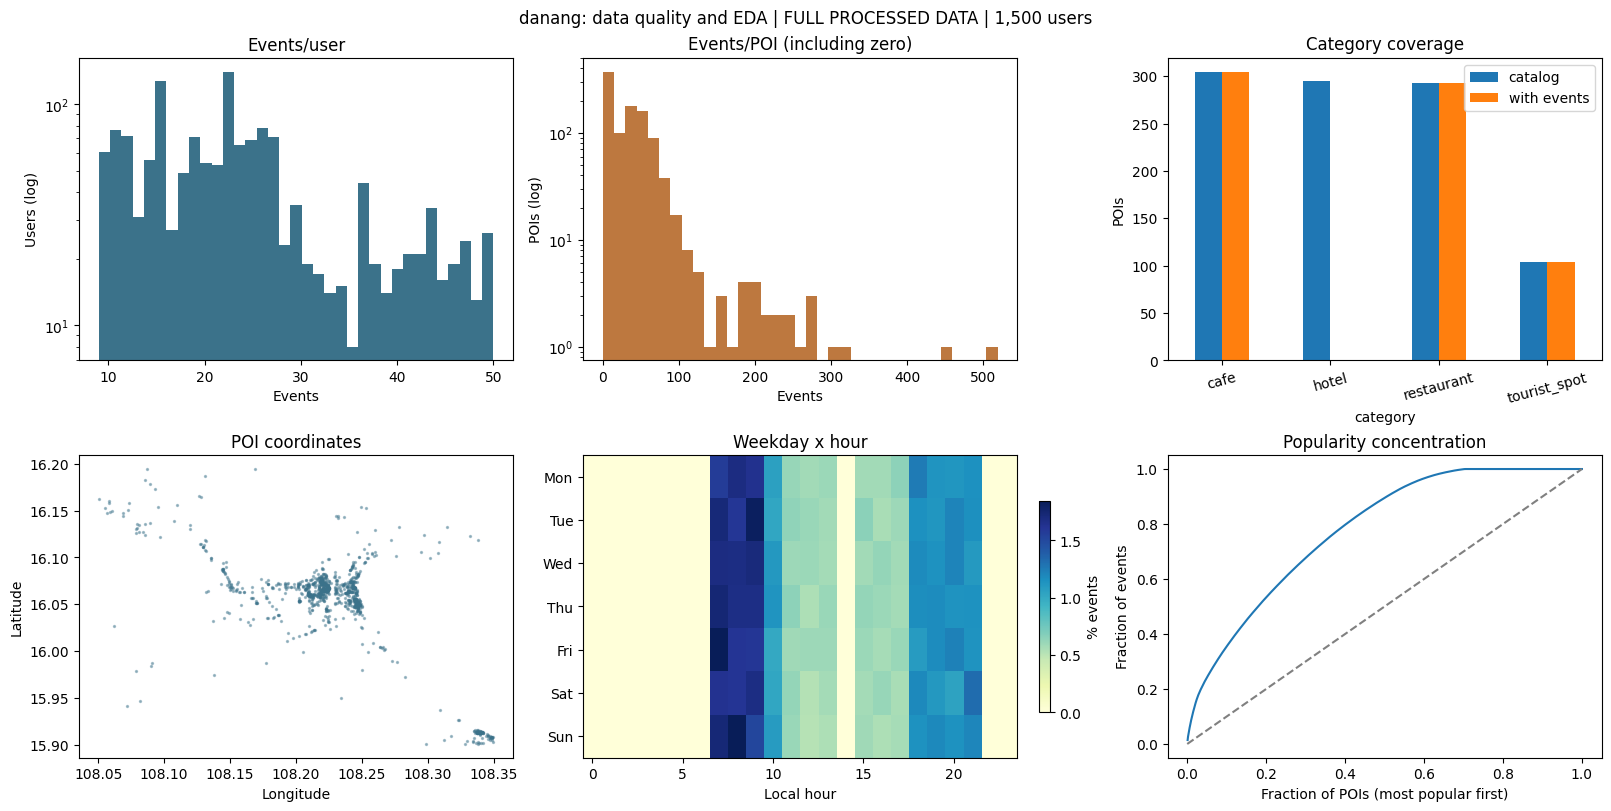

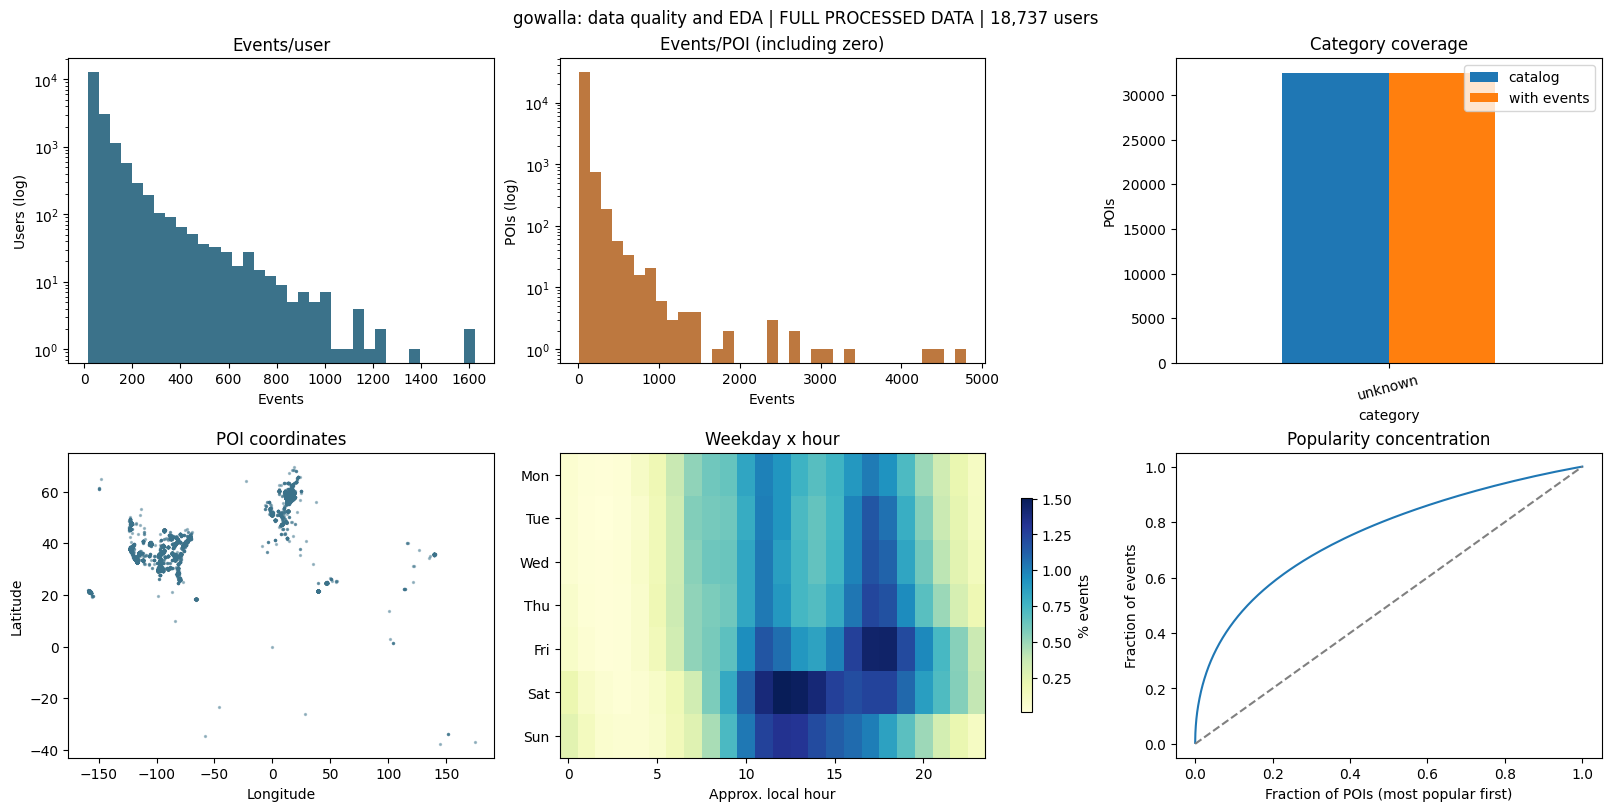

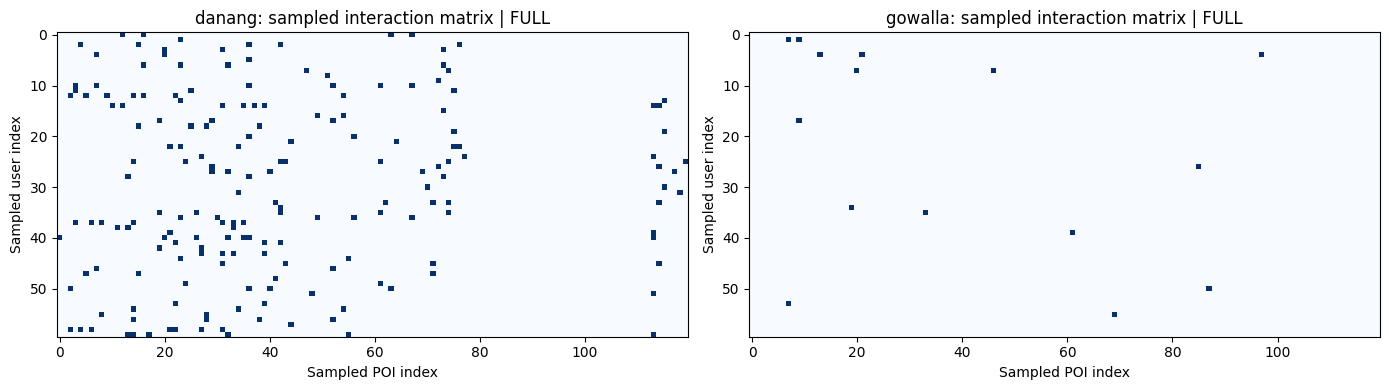

,name,train,validation,test,validation_raw,test_raw,validation_cold_user_events_excluded,test_cold_user_events_excluded,train_end_utc,fit_end_utc,test_start_utc,catalog_assumption,history_assumption,novel_test_events,repeated_test_events,repeated_test_percent,test_item_cold_events
dataset,,,,,,,,,,,,,,,,,
danang,global_time,25347,2025,3883,3621,7242,1596,3359,2023-09-09 01:24:00+00:00,2023-10-18 00:13:00+00:00,2023-10-18 00:22:00+00:00,Static full catalog; eligibility/core filterin...,Frozen fit history; test events do not update ...,3055,828,21.323719,0
gowalla,global_time,894671,109658,207611,127810,255621,18152,48010,2010-08-08 18:51:11+00:00,2010-09-03 13:18:56+00:00,2010-09-03 13:18:57+00:00,Static full catalog; eligibility/core filterin...,Frozen fit history; test events do not update ...,135604,72007,34.683615,4175


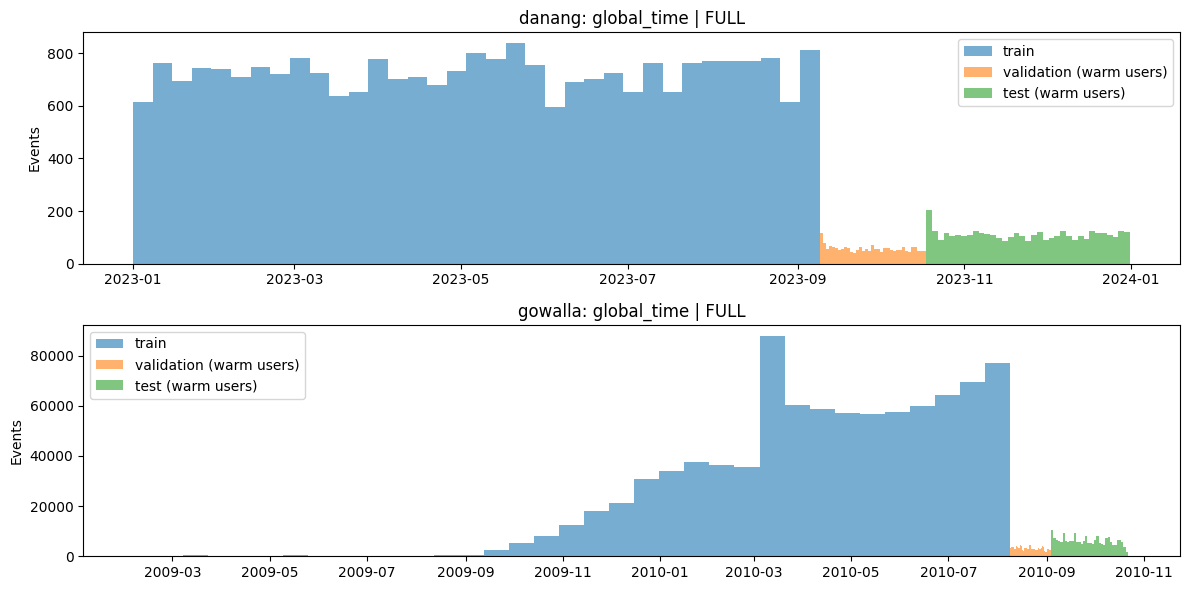

1534

In [8]:
# Kiểm tra dataset, EDA, ma trận và split
# ## 4. Chất lượng dữ liệu trước khi huấn luyện
#
# **Mục đích:** báo cáo trên đúng dữ liệu sẽ được dùng, không suy rộng kết quả smoke sang toàn bộ nguồn.
# Kiểm tra kỹ thuật sạch không chứng minh dữ liệu đại diện cho người dùng thực.
# POI có trong catalog nhưng không có tương tác vẫn được giữ và được đánh dấu chưa có bằng chứng đánh giá.
# Bộ Đà Nẵng đã audit có 295 khách sạn không có check-in; notebook tính lại từ CSV mỗi lần chạy.
QUALITY, quality_rows, category_rows = {}, [], []
for name in DATASETS:
    pois, events, user_ids, poi_ids, fingerprint = DATA_CACHE[name]
    profile = quality_profile(pois, events, dataset_metadata(DATA_DIRS[name]))
    profile.update(smoke_run=RUN_MODE == "smoke", dataset_sha256=fingerprint)
    QUALITY[name] = profile
    quality_rows.append({"dataset": name, **{key: profile[key] for key in
        ["users", "pois", "events", "sparsity_percent", "repeat_event_percent", "unreferenced_pois", "hour_mismatches", "weekday_mismatches"]}})
    for category, counts in profile["category_coverage"].items():
        category_rows.append({"dataset": name, "category": category, **counts})
    for warning in profile["warnings"]:
        print(f"[{name}] {warning}")
display(pd.DataFrame(quality_rows).set_index("dataset"))
category_quality = pd.DataFrame(category_rows)
display(category_quality)
(OUT / "dataset_quality.json").write_text(json.dumps(QUALITY, ensure_ascii=False, indent=2), encoding="utf-8")
category_quality.to_csv(OUT / "category_coverage.csv", index=False)

# ### 4.1. EDA: phân bố, bản đồ và heatmap thời gian
#
# **Mục đích:** kiểm tra user hoạt động ít/nhiều, POI ít/phổ biến, category không có tương tác và mẫu giờ/thứ.
# Heatmap Gowalla dùng giờ xấp xỉ theo kinh độ. Mẫu giờ của dữ liệu mô phỏng có thể phản ánh quy tắc sinh dữ liệu;
# kết quả cao trên Đà Nẵng chưa chứng minh học được hành vi người dùng thật.
for name in DATASETS:
    pois, events, *_ = DATA_CACHE[name]
    label = "SMOKE: technical check" if RUN_MODE == "smoke" else ("USER SUBSET" if QUALITY[name]["source_metadata"].get("is_subset") else "FULL PROCESSED DATA")
    figure = plot_eda(pois, events, name, OUT, run_label=label)
    display(figure)
    plt.close(figure)

# ### 4.2. Ma trận tương tác user–POI
#
# **Mục đích:** trực quan hóa tính thưa trên một mẫu tối đa 60 user × 120 POI, lấy ngẫu nhiên với seed cố định.
# Đây là ảnh minh họa mẫu, không phải toàn bộ ma trận và không được dùng để chọn hyperparameter.
fig, axes = plt.subplots(1, len(DATASETS), figsize=(7 * len(DATASETS), 4), squeeze=False)
for column, name in enumerate(DATASETS):
    pois, events, *_ = DATA_CACHE[name]
    rng = np.random.default_rng(2026)
    sampled_users = np.sort(rng.choice(events.user.unique(), min(60, events.user.nunique()), replace=False))
    sampled_items = np.sort(rng.choice(len(pois), min(120, len(pois)), replace=False))
    sample = events[events.user.isin(sampled_users) & events.item.isin(sampled_items)]
    matrix = pd.crosstab(sample.user, sample.item).reindex(index=sampled_users, columns=sampled_items, fill_value=0)
    axes[0, column].imshow(matrix.to_numpy() > 0, aspect="auto", cmap="Blues", vmin=0, vmax=1)
    axes[0, column].set(title=f"{name}: sampled interaction matrix | {RUN_MODE.upper()}", xlabel="Sampled POI index", ylabel="Sampled user index")
fig.tight_layout()
fig.savefig(OUT / "interaction_matrices.png", dpi=150)
display(fig)
plt.close(fig)

# ## 5. Giao thức đánh giá và kiểm tra split
#
# **Mục đích:** mặc định chia theo hai mốc thời gian chung, tỷ lệ mục tiêu 70/10/20; timestamp bằng nhau luôn cùng tập.
# Chọn epoch/learning rate trên validation, sau đó refit train+validation và đánh giá test bằng lịch sử fit cố định.
# User chưa có lịch sử train bị loại khỏi tuning; user chưa có lịch sử fit bị loại khỏi bảng test warm-user và được đếm riêng.
#
# Hai phạm vi được báo cáo độc lập:
#
# - **Novel visits:** target chưa ghé trong fit; mask toàn bộ POI đã ghé trong fit.
# - **All visits:** giữ cả lượt quay lại, không mask lịch sử. Hai phạm vi có candidate set khác nhau nên đọc bảng riêng.
#
# `per_user` chỉ dùng khi cần đối chiếu giao thức cũ; nó có thể đưa tương tác tương lai của user khác vào graph.
# Tham khảo [Ji et al., temporal leakage](https://arxiv.org/abs/2010.11060).
SPLIT_REPORTS, split_rows = {}, []
fig, axes = plt.subplots(len(DATASETS), 1, figsize=(12, 3 * len(DATASETS)), squeeze=False)
for row, name in enumerate(DATASETS):
    pois, events, *_ = DATA_CACHE[name]
    train, validation, test, fit, info = study_split(events, SPLIT_PROTOCOL)
    fit_pairs = pd.MultiIndex.from_frame(fit[["user", "item"]].drop_duplicates())
    repeated = pd.MultiIndex.from_frame(test[["user", "item"]]).isin(fit_pairs)
    info.update(novel_test_events=int((~repeated).sum()), repeated_test_events=int(repeated.sum()),
                repeated_test_percent=float(repeated.mean() * 100),
                test_item_cold_events=int((~test.item.isin(fit.item)).sum()))
    SPLIT_REPORTS[name] = info
    split_rows.append({"dataset": name, **info})
    for label, frame in [("train", train), ("validation (warm users)", validation), ("test (warm users)", test)]:
        axes[row, 0].hist(pd.to_datetime(frame.ts, unit="s", utc=True).dt.tz_localize(None), bins=35, alpha=.6, label=label)
    axes[row, 0].set(title=f"{name}: {SPLIT_PROTOCOL} | {RUN_MODE.upper()}", ylabel="Events")
    axes[row, 0].legend()
    if SPLIT_PROTOCOL == "global_time":
        assert train.ts.max() < validation.ts.min()
        assert fit.ts.max() < test.ts.min()
display(pd.DataFrame(split_rows).set_index("dataset"))
fig.tight_layout()
fig.savefig(OUT / "temporal_split.png", dpi=150)
display(fig)
plt.close(fig)
(OUT / "split_audit.json").write_text(json.dumps(SPLIT_REPORTS, ensure_ascii=False, indent=2), encoding="utf-8")


## 4. Kiến trúc, giả thuyết và thiết kế thí nghiệm

**Mục đích:** kiểm tra liệu thông tin thời gian/không gian cải thiện xếp hạng so với các baseline trên cùng dữ liệu và budget tuning.
Giả thuyết được kiểm tra riêng cho mỗi dataset; không giả định TAS-GNN phải thắng.

Backbone là graph user–POI nhị phân chuẩn hóa bậc, lan truyền tuyến tính rồi trung bình embedding các lớp,
theo [LightGCN, He et al.](https://arxiv.org/abs/2002.02126).
TAS-GNN của dự án cộng nhánh tọa độ/category và ngữ cảnh sin/cos ngày/tuần qua gating; graph vẫn tĩnh trong mỗi lượt fit.

Với positive $i^+$ và negative $i^-$ không thuộc lịch sử fit:
$\mathcal L_{BPR}=\operatorname{softplus}(-(s(u,i^+,t)-s(u,i^-,t)))+10^{-4}R$,
với $R$ là trung bình tổng bình phương các embedding user/positive/negative được lấy trong batch.

Với rank $r$ của một target: $HR@K=\mathbf 1[r\le K]$,
$NDCG@K=\mathbf 1[r\le K]/\log_2(r+1)$ và $MRR@K=\mathbf 1[r\le K]/r$; báo cáo trung bình theo event và macro-user HR@10.
Đây không phải Recall của tập POI duy nhất theo user. Chấm trên toàn catalog; không lấy sampled negatives khi test.

BPR-MF dùng 0 lớp graph; các model train được dùng cùng danh sách learning rate, số epoch tối đa và patience.
Geo-hourly dùng check-in cuối của fit làm vị trí gốc và thang khoảng cách cố định 5 km, chỉ chạy với global time.
`tas_no_space` bỏ nhánh spatial tĩnh nhưng giữ category trong nhánh time khi có nhãn;
`tas_no_category` thay modulation category bằng item embedding, nên cần đọc cùng bảng cấu hình khi diễn giải ablation.

**Mục đích:** thực thi các cấu hình đã khai báo. Không chọn seed hoặc thay hyperparameter theo kết quả test.
DIM/LAYERS được giữ cố định; learning rate và epoch là hai tham số được chọn trên validation trong grid đã khai báo.
Mỗi seed có thư mục riêng; seed đầu giữ đường dẫn tương thích ứng dụng, không có nghĩa là seed tốt nhất.

In [9]:
# Thiết kế và chạy thí nghiệm
# ## 6. Kiến trúc, giả thuyết và thiết kế thí nghiệm
#
# **Mục đích:** kiểm tra liệu thông tin thời gian/không gian cải thiện xếp hạng so với các baseline trên cùng dữ liệu và budget tuning.
# Giả thuyết được kiểm tra riêng cho mỗi dataset; không giả định TAS-GNN phải thắng.
#
# Backbone là graph user–POI nhị phân chuẩn hóa bậc, lan truyền tuyến tính rồi trung bình embedding các lớp,
# theo [LightGCN, He et al.](https://arxiv.org/abs/2002.02126).
# TAS-GNN của dự án cộng nhánh tọa độ/category và ngữ cảnh sin/cos ngày/tuần qua gating; graph vẫn tĩnh trong mỗi lượt fit.
#
# Với positive $i^+$ và negative $i^-$ không thuộc lịch sử fit:
# $\mathcal L_{BPR}=\operatorname{softplus}(-(s(u,i^+,t)-s(u,i^-,t)))+10^{-4}R$,
# với $R$ là trung bình tổng bình phương các embedding user/positive/negative được lấy trong batch.
#
# Với rank $r$ của một target: $HR@K=\mathbf 1[r\le K]$,
# $NDCG@K=\mathbf 1[r\le K]/\log_2(r+1)$ và $MRR@K=\mathbf 1[r\le K]/r$; báo cáo trung bình theo event và macro-user HR@10.
# Đây không phải Recall của tập POI duy nhất theo user. Chấm trên toàn catalog; không lấy sampled negatives khi test.
#
# BPR-MF dùng 0 lớp graph; các model train được dùng cùng danh sách learning rate, số epoch tối đa và patience.
# Geo-hourly dùng check-in cuối của fit làm vị trí gốc và thang khoảng cách cố định 5 km, chỉ chạy với global time.
# `tas_no_space` bỏ nhánh spatial tĩnh nhưng giữ category trong nhánh time khi có nhãn;
# `tas_no_category` thay modulation category bằng item embedding, nên cần đọc cùng bảng cấu hình khi diễn giải ablation.
variant_rows = []
for name in DATASETS:
    has_categories = dataset_metadata(DATA_DIRS[name])["has_categories"]
    for model, (temporal, spatial, category_features) in model_variants(has_categories, RUN_ABLATION).items():
        variant_rows.append({"dataset": name, "model": model, "time": temporal, "spatial": spatial,
                             "category_features": category_features, "layers": 0 if model == "bpr_mf" else (1 if RUN_MODE == "smoke" else LAYERS)})
display(pd.DataFrame(variant_rows))
experiment_config = {"datasets": DATASETS, "run_mode": RUN_MODE, "seeds": ACTIVE_SEEDS,
    "protocol": SPLIT_PROTOCOL, "run_ablation": RUN_ABLATION, "epochs": EPOCHS,
    "learning_rates": ACTIVE_LRS, "patience": PATIENCE, "dim": DIM, "layers": LAYERS,
    "batch_sizes": BATCH_SIZES, "eval_batch_size": EVAL_BATCH_SIZE,
    "coverage_queries_max": COVERAGE_QUERIES, "bootstrap_resamples": BOOTSTRAP_SAMPLES,
    "smoke_overrides": {"max_users": 24, "epochs": 1, "dim": 16, "layers": 1} if RUN_MODE == "smoke" else None}
(OUT / "experiment_config.json").write_text(json.dumps(experiment_config, indent=2), encoding="utf-8")
print("Trainable fits (tuning candidates + refit):", len(variant_rows) * len(ACTIVE_SEEDS) * (len(ACTIVE_LRS) + 1))
print("Full Gowalla + ablation + nhiều seed có thể tốn nhiều giờ; smoke chỉ kiểm tra kỹ thuật.")

# ### 6.1. Huấn luyện, refit và chấm test
#
# **Mục đích:** thực thi các cấu hình đã khai báo. Không chọn seed hoặc thay hyperparameter theo kết quả test.
# DIM/LAYERS được giữ cố định; learning rate và epoch là hai tham số được chọn trên validation trong grid đã khai báo.
# Mỗi seed có thư mục riêng; seed đầu giữ đường dẫn tương thích ứng dụng, không có nghĩa là seed tốt nhất.
reports, EXPERIMENTS = {}, {}
for name in DATASETS:
    reports[name], EXPERIMENTS[name] = [], []
    for seed in ACTIVE_SEEDS:
        destination = OUT / name if seed == ACTIVE_SEEDS[0] else OUT / name / f"seed_{seed}"
        report = run_study(DATA_DIRS[name], destination,
            epochs=1 if RUN_MODE == "smoke" else EPOCHS[name], seed=seed,
            max_users=24 if RUN_MODE == "smoke" else None,
            dim=16 if RUN_MODE == "smoke" else DIM, layers=1 if RUN_MODE == "smoke" else LAYERS,
            batch_size=BATCH_SIZES[name], eval_batch_size=EVAL_BATCH_SIZE,
            protocol=SPLIT_PROTOCOL, ablation=RUN_ABLATION, learning_rates=ACTIVE_LRS,
            patience=PATIENCE, coverage_queries=COVERAGE_QUERIES)
        reports[name].append(report)
        EXPERIMENTS[name].append((destination, report))
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


,dataset,model,time,spatial,category_features,layers
0,danang,bpr_mf,False,False,False,0
1,danang,lightgcn,False,False,False,3
2,danang,tas_gnn,True,True,True,3
3,danang,tas_no_time,False,True,True,3
4,danang,tas_no_space,True,False,True,3
5,danang,tas_no_category,True,True,False,3
6,gowalla,bpr_mf,False,False,False,0
7,gowalla,lightgcn,False,False,False,3
8,gowalla,tas_gnn,True,True,False,3
9,gowalla,tas_no_time,False,True,False,3


Trainable fits (tuning candidates + refit): 99
Full Gowalla + ablation + nhiều seed có thể tốn nhiều giờ; smoke chỉ kiểm tra kỹ thuật.
danang seed=42: tuning bpr_mf


/content/dss_colab_v2/poi_model.py:228: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:49.)
  self.adj = coo.to_sparse_csr() if coo.is_cuda else coo


{"epoch": 1, "loss": 0.6931183074980218, "validation_HR@10": 0.01059190031152648}
{"epoch": 2, "loss": 0.690825709077307, "validation_HR@10": 0.008722741433021807}
{"epoch": 3, "loss": 0.6883463861039579, "validation_HR@10": 0.014953271028037384}
{"epoch": 4, "loss": 0.685174529496587, "validation_HR@10": 0.027414330218068536}
{"epoch": 5, "loss": 0.6806896096358155, "validation_HR@10": 0.041121495327102804}
{"epoch": 6, "loss": 0.6740242821928425, "validation_HR@10": 0.058566978193146414}
{"epoch": 7, "loss": 0.6646434495156252, "validation_HR@10": 0.0778816199376947}
{"epoch": 8, "loss": 0.6516974004113463, "validation_HR@10": 0.08598130841121496}
{"epoch": 9, "loss": 0.6351618633499022, "validation_HR@10": 0.09657320872274143}
{"epoch": 10, "loss": 0.6144705223026946, "validation_HR@10": 0.09906542056074766}
{"epoch": 11, "loss": 0.5911879144406448, "validation_HR@10": 0.102803738317757}
{"epoch": 12, "loss": 0.5646268217602288, "validation_HR@10": 0.10654205607476636}
{"epoch": 13,

## 5. Kết quả nhiều seed, ma trận metric và learning curves

**Mục đích:** biểu đồ dùng trung bình của tất cả seed, thanh sai số là độ lệch chuẩn giữa seed.
Heatmap đọc theo từng dataset. Learning curves minh họa seed đầu với nhãn rõ ràng và epoch đã chọn.
BPR loss giữa kiến trúc có thể có scale khác nhau; ưu tiên validation metric khi so sánh.

### Ablation và khoảng tin cậy

**Mục đích:** kiểm tra biến thể bỏ thành phần và độ bất định của chênh lệch so với TAS-GNN.
Bootstrap resample theo user, ghép cặp trên cùng user; seed được trung bình trong user trước khi resample.
CI mô tả chênh lệch **macro-user HR@10**, không phải event HR@10. CI chứa 0 chưa cung cấp bằng chứng rõ cho chiều cải thiện.
Đây là phân tích thăm dò nhiều so sánh, chưa hiệu chỉnh multiple comparisons; không chọn lại hyperparameter từ bảng này.

### Phân tích lỗi và tài nguyên

**Mục đích:** tìm nhóm dữ liệu yếu qua các slice và ví dụ đúng/sai của seed đầu. Bảng luôn có số mẫu;
không suy diễn từ nhóm ít mẫu hoặc category không có event. Các rank được tính trên đúng candidate set đã khai báo.

Catalog coverage@10 dùng tối đa `COVERAGE_QUERIES` novel queries với mẫu cố định để so model;
nó chưa phải độ phủ của toàn bộ traffic. Latency p50/p95 đo warm batch scoring với embedding cache,
chưa bao gồm HTTP, truyền CPU hoặc dựng lại graph và không phải latency production.

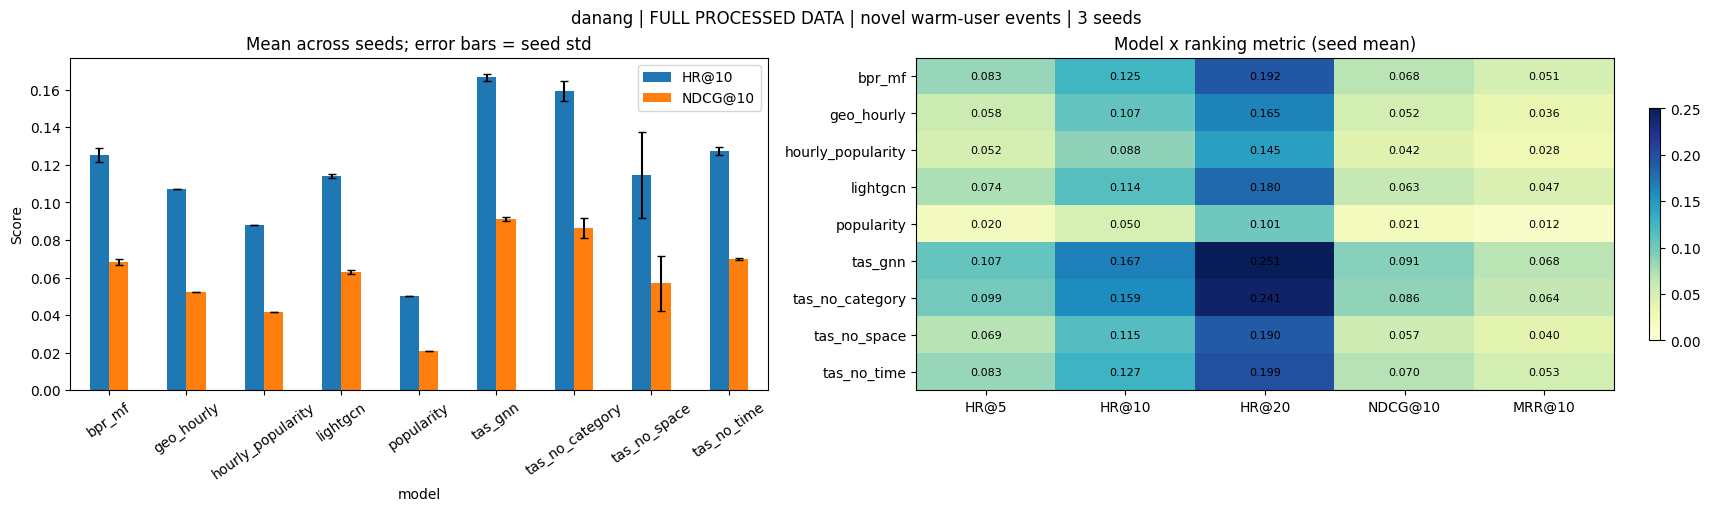

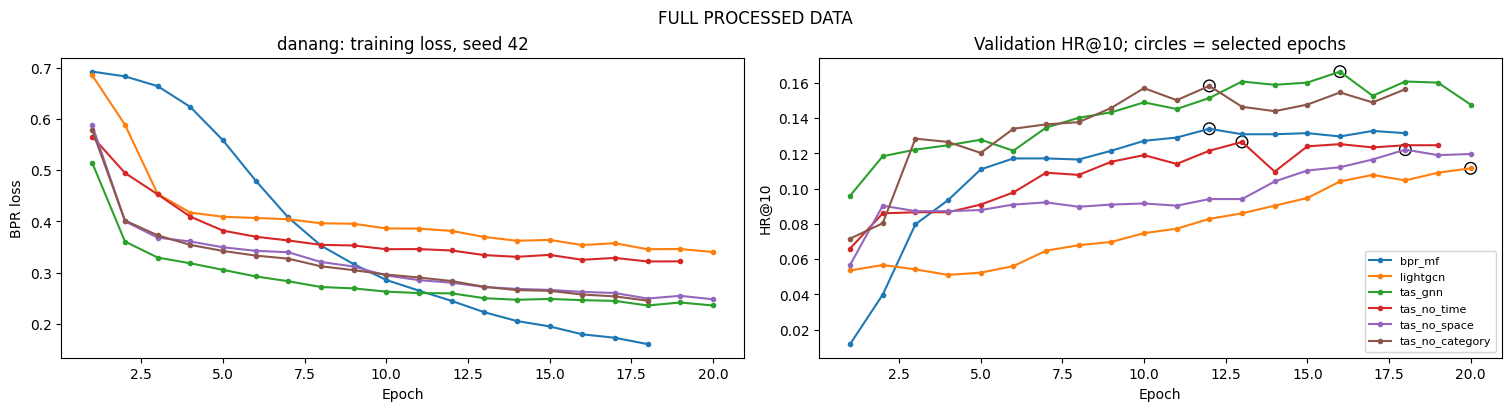

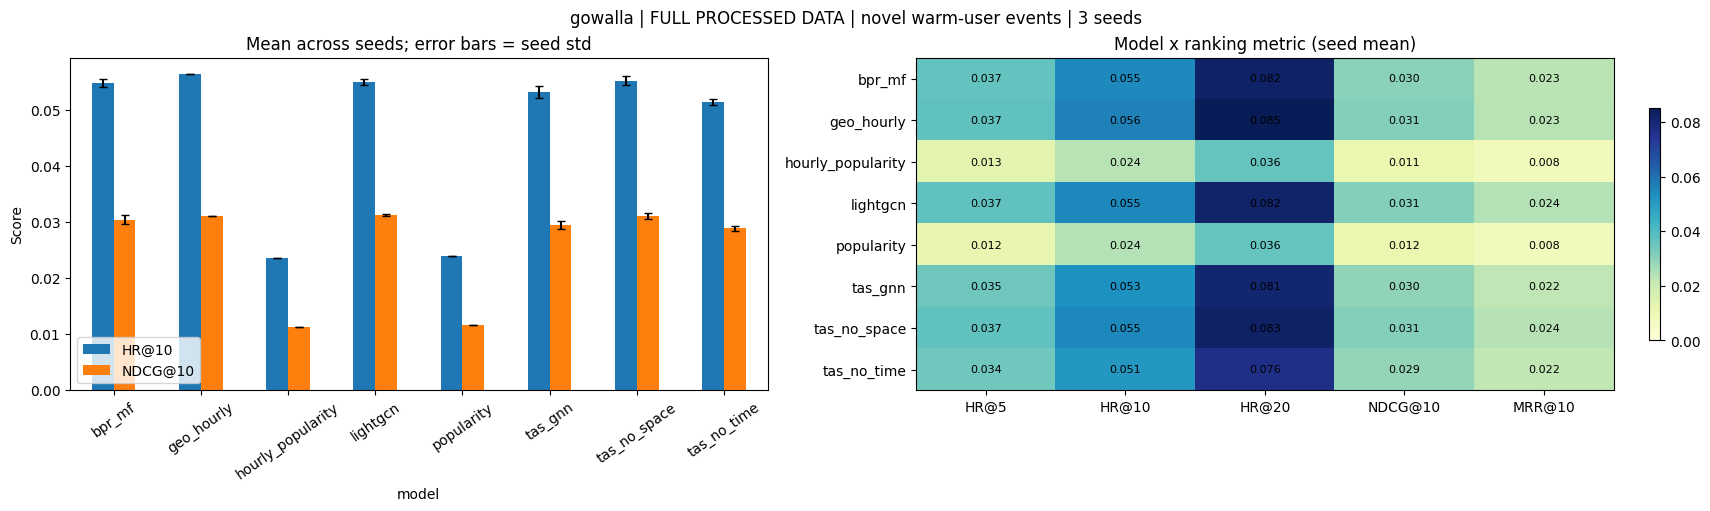

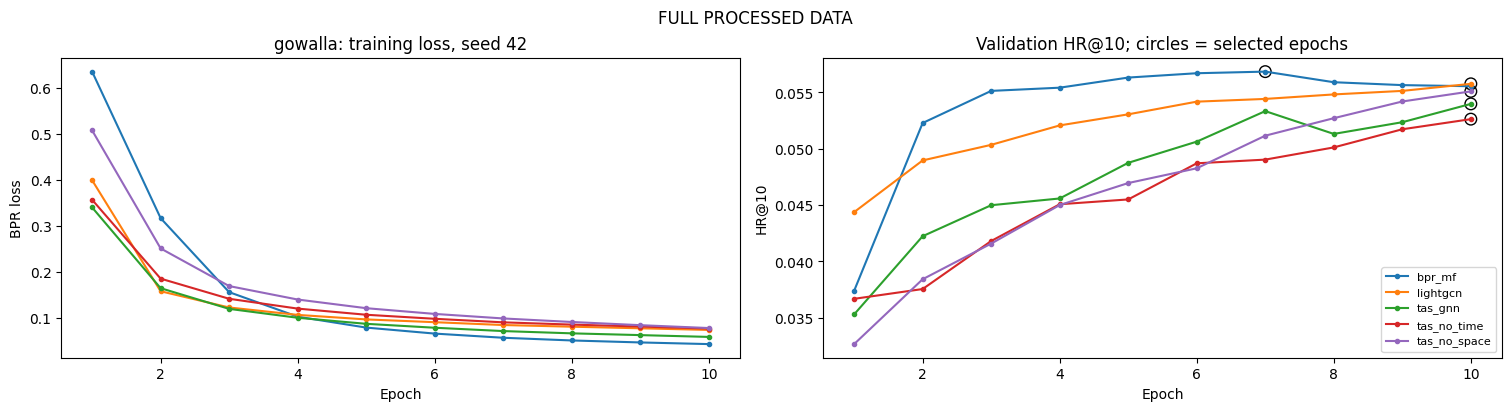

NOVEL VISITS


HR@10                   NDCG@10                  \
                               mean       std count      mean       std count   
dataset model                                                                   
danang  bpr_mf             0.125150  0.003822     3  0.068392  0.001637     3   
        geo_hourly         0.107038  0.000000     3  0.052280  0.000000     3   
        hourly_popularity  0.087725  0.000000     3  0.041784  0.000000     3   
        lightgcn           0.114130  0.001052     3  0.062936  0.001039     3   
        popularity         0.050409  0.000000     3  0.020777  0.000000     3   
        tas_gnn            0.166612  0.001823     3  0.090978  0.001117     3   
        tas_no_category    0.159411  0.005359     3  0.086279  0.005408     3   
        tas_no_space       0.114566  0.022827     3  0.056937  0.014491     3   
        tas_no_time        0.127441  0.002000     3  0.069993  0.000417     3   
gowalla bpr_mf             0.054836  0.000697     3  0.030440  0.000733     3   
        geo_hourly         0.056429  0.000000     3  0.031121  0.000000     3   
        hourly_popularity  0.023569  0.000000     3  0.011341  0.000000     3   
        lightgcn           0.054964  0.000469     3  0.031217  0.000200     3   
        popularity         0.023996  0.000000     3  0.011621  0.000000     3   
        tas_gnn            0.053216  0.001022     3  0.029549  0.000713     3   
        tas_no_space       0.055205  0.000791     3  0.031129  0.000566     3   
        tas_no_time        0.051390  0.000530     3  0.028852  0.000442     3   

                             MRR@10                  \
                               mean       std count   
dataset model                                         
danang  bpr_mf             0.051121  0.001105     3   
        geo_hourly         0.035964  0.000000     3   
        hourly_popularity  0.028042  0.000000     3   
        lightgcn           0.047452  0.000968     3   
        popularity         0.012068  0.000000     3   
        tas_gnn            0.068175  0.000950     3   
        tas_no_category    0.064305  0.005331     3   
        tas_no_space       0.039592  0.012182     3   
        tas_no_time        0.052629  0.000706     3   
gowalla bpr_mf             0.023039  0.000732     3   
        geo_hourly         0.023454  0.000000     3   
        hourly_popularity  0.007670  0.000000     3   
        lightgcn           0.024016  0.000153     3   
        popularity         0.007959  0.000000     3   
        tas_gnn            0.022390  0.000628     3   
        tas_no_space       0.023832  0.000507     3   
        tas_no_time        0.022022  0.000418     3   

                          sample_catalog_coverage_at_10                  
                                                   mean       std count  
dataset model                                                            
danang  bpr_mf                                 0.217871  0.048692     3  
        geo_hourly                             0.122490  0.000000     3  
        hourly_popularity                      0.060241  0.000000     3  
        lightgcn                               0.068608  0.003526     3  
        popularity                             0.018072  0.000000     3  
        tas_gnn                                0.238621  0.013104     3  
        tas_no_category                        0.228581  0.031660     3  
        tas_no_space                           0.088688  0.036840     3  
        tas_no_time                            0.185743  0.010482     3  
gowalla bpr_mf                                 0.028658  0.004467     3  
        geo_hourly                             0.057398  0.000000     3  
        hourly_popularity                      0.002707  0.000000     3  
        lightgcn                               0.015195  0.000347     3  
        popularity                             0.000554  0.000000     3  
        tas_gnn                                0.0

ALL VISITS: candidate set includes previously visited POIs


HR@10             NDCG@10          
                               mean       std      mean       std
dataset model                                                    
danang  bpr_mf             0.226200  0.003072  0.135461  0.001003
        geo_hourly         0.187999  0.000000  0.101753  0.000000
        hourly_popularity  0.165336  0.000000  0.086047  0.000000
        lightgcn           0.209374  0.001689  0.121422  0.001343
        popularity         0.115117  0.000000  0.064398  0.000000
        tas_gnn            0.255902  0.001827  0.149073  0.000755
        tas_no_category    0.249807  0.006500  0.143572  0.004651
        tas_no_space       0.203880  0.032708  0.112532  0.024013
        tas_no_time        0.227144  0.002230  0.136169  0.000729
gowalla bpr_mf             0.138999  0.008124  0.085667  0.004938
        geo_hourly         0.122099  0.000000  0.073047  0.000000
        hourly_popularity  0.033929  0.000000  0.016700  0.000000
        lightgcn           0.084520  0.000428  0.050347  0.000106
        popularity         0.031101  0.000000  0.015376  0.000000
        tas_gnn            0.090445  0.002987  0.051009  0.001729
        tas_no_space       0.085476  0.001994  0.049029  0.001205
        tas_no_time        0.081373  0.000787  0.048073  0.000395

danang TAS-GNN minus reference: macro-user HR@10


,reference,users,macro_user_HR10_difference,ci95_low,ci95_high,resamples
0,bpr_mf,524,0.041779,0.031135,0.053129,2000
1,geo_hourly,524,0.062506,0.048853,0.075700,2000
2,hourly_popularity,524,0.082666,0.068782,0.096771,2000
3,lightgcn,524,0.051483,0.039955,0.062594,2000
4,popularity,524,0.120453,0.105852,0.135126,2000
5,tas_no_category,524,0.007410,0.000986,0.013923,2000
6,tas_no_space,524,0.054111,0.042925,0.065105,2000
7,tas_no_time,524,0.039790,0.029508,0.049480,2000


HR@10             NDCG@10          
                     mean       std      mean       std
model                                                  
tas_gnn          0.166612  0.001823  0.090978  0.001117
tas_no_category  0.159411  0.005359  0.086279  0.005408
tas_no_space     0.114566  0.022827  0.056937  0.014491
tas_no_time      0.127441  0.002000  0.069993  0.000417

gowalla TAS-GNN minus reference: macro-user HR@10


,reference,users,macro_user_HR10_difference,ci95_low,ci95_high,resamples
0,bpr_mf,11419,-0.002798,-0.004468,-0.001152,2000
1,geo_hourly,11419,-0.002751,-0.005483,-0.000035,2000
2,hourly_popularity,11419,0.041232,0.038888,0.043547,2000
3,lightgcn,11419,-0.000968,-0.002531,0.000607,2000
4,popularity,11419,0.039492,0.037079,0.041917,2000
5,tas_no_space,11419,-0.000705,-0.001934,0.000549,2000
6,tas_no_time,11419,0.002841,0.001525,0.004159,2000


HR@10             NDCG@10          
                  mean       std      mean       std
model                                               
tas_gnn       0.053216  0.001022  0.029549  0.000713
tas_no_space  0.055205  0.000791  0.031129  0.000566
tas_no_time   0.051390  0.000530  0.028852  0.000442

In [10]:
# Tổng hợp nhiều seed, learning curves và bootstrap
# ## 7. Kết quả nhiều seed, ma trận metric và learning curves
#
# **Mục đích:** biểu đồ dùng trung bình của tất cả seed, thanh sai số là độ lệch chuẩn giữa seed.
# Heatmap đọc theo từng dataset. Learning curves minh họa seed đầu với nhãn rõ ràng và epoch đã chọn.
# BPR loss giữa kiến trúc có thể có scale khác nhau; ưu tiên validation metric khi so sánh.
rows, all_visit_rows = [], []
for name in DATASETS:
    table, figures = plot_study(reports[name], name, OUT)
    table["dataset"] = name
    rows.append(table)
    for figure in figures:
        display(figure)
        plt.close(figure)
    for report in reports[name]:
        for model, metrics in report["all_event_results"].items():
            all_visit_rows.append({"dataset": name, "seed": report["seed"], "model": model, **metrics})
summary = pd.concat(rows, ignore_index=True)
all_visit_summary = pd.DataFrame(all_visit_rows)
for frame in (summary, all_visit_summary):
    frame["smoke_run"] = RUN_MODE == "smoke"
    frame["protocol"] = SPLIT_PROTOCOL
    frame["is_subset"] = frame.dataset.map({name: any(report["is_subset"] for report in reports[name]) for name in DATASETS})
summary.to_csv(OUT / "all_datasets_comparison.csv", index=False)
all_visit_summary.to_csv(OUT / "all_visit_comparison.csv", index=False)
metrics = ["HR@10", "NDCG@10", "MRR@10", "sample_catalog_coverage_at_10"]
aggregate = summary.groupby(["dataset", "model"])[metrics].agg(["mean", "std", "count"])
aggregate.to_csv(OUT / "multi_seed_summary.csv")
print("NOVEL VISITS")
display(aggregate)
print("ALL VISITS: candidate set includes previously visited POIs")
display(all_visit_summary.groupby(["dataset", "model"])[["HR@10", "NDCG@10"]].agg(["mean", "std"]))

# ### 7.1. Ablation và khoảng tin cậy chênh lệch
#
# **Mục đích:** kiểm tra biến thể bỏ thành phần và độ bất định của chênh lệch so với TAS-GNN.
# Bootstrap resample theo user, ghép cặp trên cùng user; seed được trung bình trong user trước khi resample.
# CI mô tả chênh lệch **macro-user HR@10**, không phải event HR@10. CI chứa 0 chưa cung cấp bằng chứng rõ cho chiều cải thiện.
# Đây là phân tích thăm dò nhiều so sánh, chưa hiệu chỉnh multiple comparisons; không chọn lại hyperparameter từ bảng này.
BOOTSTRAP = {}
for name in DATASETS:
    intervals = paired_user_bootstrap(EXPERIMENTS[name], samples=BOOTSTRAP_SAMPLES)
    BOOTSTRAP[name] = intervals
    intervals.to_csv(OUT / f"{name}_paired_user_ci.csv", index=False)
    print(name, "TAS-GNN minus reference: macro-user HR@10")
    display(intervals)
    ablation = summary[(summary.dataset == name) & summary.model.str.startswith("tas_")]
    display(ablation.groupby("model")[["HR@10", "NDCG@10"]].agg(["mean", "std"]))


,group,events,HR10,slice,model
0,7,441,0.068027,hour,hourly_popularity
1,8,413,0.038741,hour,hourly_popularity
2,9,415,0.079518,hour,hourly_popularity
3,10,427,0.046838,hour,hourly_popularity
4,11,9,0.111111,hour,hourly_popularity
...,...,...,...,...,...
64,6-20,549,0.178506,history_group,tas_gnn
65,21-50,2454,0.164629,history_group,tas_gnn
66,1-10,53,0.000000,poi_group,tas_gnn
67,11-50,1580,0.065190,poi_group,tas_gnn


danang First-seed examples; rank_all and rank_novel use different candidate sets


,user,item,hour,category,fit_history,poi_fit_events,rank_novel,rank_all
9,3,79,8,cafe,34,29,5.0,10.0
12,3,55,7,cafe,34,50,4.0,9.0
14,6,16,8,cafe,28,56,10.0,13.0
0,2,133,9,cafe,29,19,104.0,117.0
1,2,903,20,tourist_spot,29,156,16.0,22.0
2,2,190,8,cafe,29,61,13.0,18.0


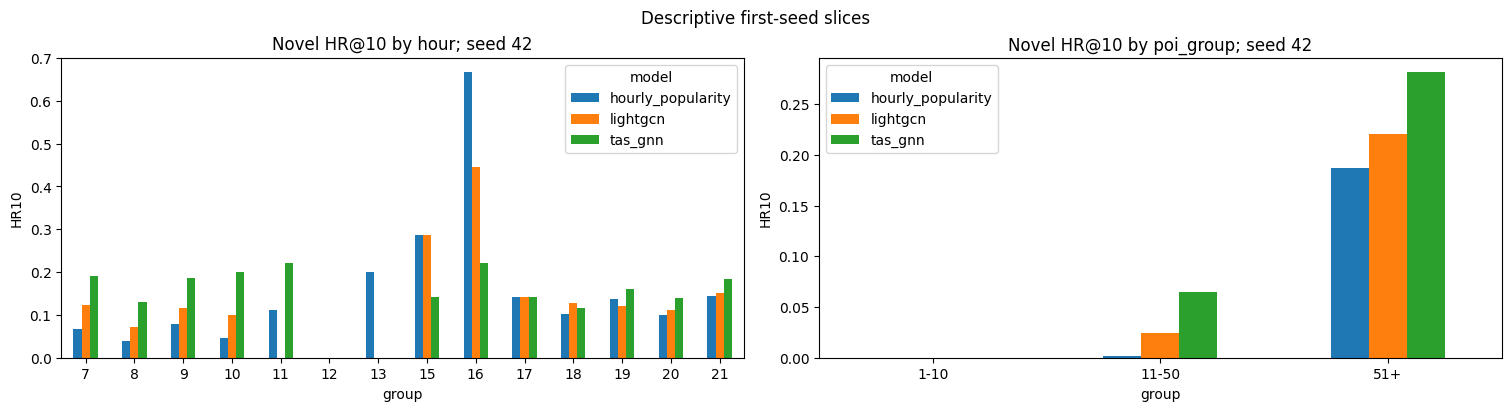

,group,events,HR10,slice,model
0,0,880,0.028409,hour,hourly_popularity
1,1,441,0.036281,hour,hourly_popularity
2,2,257,0.046693,hour,hourly_popularity
3,3,329,0.112462,hour,hourly_popularity
4,4,609,0.185550,hour,hourly_popularity
...,...,...,...,...,...
94,51+,56704,0.044212,history_group,tas_gnn
95,unseen,4175,0.000000,poi_group,tas_gnn
96,1-10,18118,0.000166,poi_group,tas_gnn
97,11-50,60804,0.003552,poi_group,tas_gnn


gowalla First-seed examples; rank_all and rank_novel use different candidate sets


,user,item,hour,category,fit_history,poi_fit_events,rank_novel,rank_all
0,0,127,20,unknown,131,747,7.0,13.0
197,1,1902,18,unknown,131,171,7.0,8.0
302,1,1902,17,unknown,131,171,8.0,9.0
6,0,10351,8,unknown,131,20,11140.0,11208.0
7,0,21609,12,unknown,131,14,15422.0,15493.0
8,0,2604,12,unknown,131,69,16260.0,16331.0


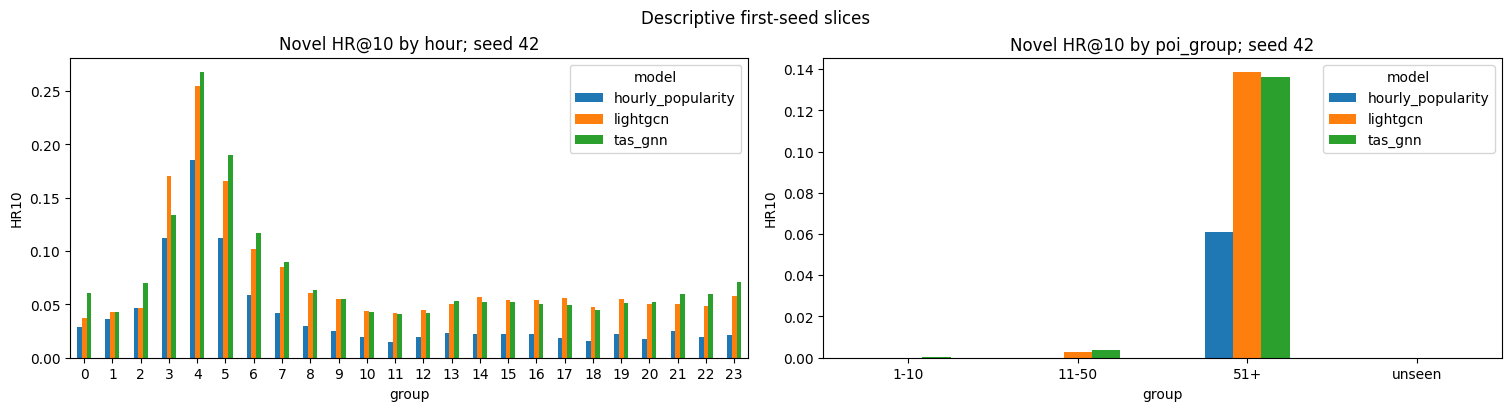

,dataset,seed,model,evaluation_seconds,train_tune_refit_seconds,parameters,peak_cuda_allocated_mib,batch_size,repeats,cached_scores_batch_ms_p50,cached_scores_batch_ms_p95,scope,checkpoint_mib
0,danang,42,popularity,0.511675,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,danang,42,hourly_popularity,0.067478,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,danang,42,geo_hourly,0.247153,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,danang,42,bpr_mf,0.053650,13.954728,159744.0,34.632812,128.0,10.0,0.065140,0.077908,"Cached embeddings, warm batch scoring; exclude...",1.173339
4,danang,42,lightgcn,0.067456,9.177798,159744.0,35.242188,128.0,10.0,0.061021,0.072628,"Cached embeddings, warm batch scoring; exclude...",1.173610
5,danang,42,tas_gnn,0.054919,20.727352,181504.0,43.789551,128.0,10.0,0.823629,1.003967,"Cached embeddings, warm batch scoring; exclude...",1.259980
6,danang,42,tas_no_time,0.051701,11.689375,164352.0,43.457520,128.0,10.0,0.058687,0.074099,"Cached embeddings, warm batch scoring; exclude...",1.192513
7,danang,42,tas_no_space,0.049547,13.759406,176896.0,43.699219,128.0,10.0,0.726826,0.823771,"Cached embeddings, warm batch scoring; exclude...",1.241427
8,danang,42,tas_no_category,0.057284,18.217003,244736.0,44.995605,128.0,10.0,0.731328,0.800480,"Cached embeddings, warm batch scoring; exclude...",1.501400
9,danang,123,popularity,0.051031,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Phân tích lỗi, ví dụ và chi phí inference
# ## 8. Phân tích lỗi, độ phủ và chi phí inference
#
# **Mục đích:** tìm nhóm dữ liệu yếu qua các slice và ví dụ đúng/sai của seed đầu. Bảng luôn có số mẫu;
# không suy diễn từ nhóm ít mẫu hoặc category không có event. Các rank được tính trên đúng candidate set đã khai báo.
#
# Catalog coverage@10 dùng tối đa `COVERAGE_QUERIES` novel queries với mẫu cố định để so model;
# nó chưa phải độ phủ của toàn bộ traffic. Latency p50/p95 đo warm batch scoring với embedding cache,
# chưa bao gồm HTTP, truyền CPU hoặc dựng lại graph và không phải latency production.
resource_rows = []
for name in DATASETS:
    destination, report = EXPERIMENTS[name][0]
    slices, examples, figure = error_slices(destination, report, OUT)
    display(slices)
    print(name, "First-seed examples; rank_all and rank_novel use different candidate sets")
    display(examples[["user", "item", "hour", "category", "fit_history", "poi_fit_events", "rank_novel", "rank_all"]])
    display(figure)
    plt.close(figure)
    for _, seed_report in EXPERIMENTS[name]:
        for model, values in seed_report["resources"].items():
            resource_rows.append({"dataset": name, "seed": seed_report["seed"], "model": model, **values})
resources = pd.DataFrame(resource_rows)
resources.to_csv(OUT / "resources.csv", index=False)
display(resources)


## 6. Kết luận có điều kiện và giới hạn

**Mục đích:** tạo nhận xét từ kết quả thực tế của lượt chạy. Không chèn số liệu từ báo cáo cũ hoặc khẳng định model đề xuất luôn thắng.
Đà Nẵng dùng tương tác mô phỏng; Gowalla là hành vi lịch sử 2009–2010, giờ địa phương xấp xỉ và catalog đã lọc core.
Notebook chưa đánh giá người dùng thực trực tuyến, user cold-start, A/B test, calibration xác suất hoặc hiệu quả AHP/TOPSIS.
Điểm model là điểm xếp hạng, không phải xác suất thích địa điểm.

### Kiểm tra artifact và tải ZIP

**Mục đích:** kiểm tra mọi checkpoint của mọi seed, chấm cặp khớp chấm toàn catalog và khôi phục đúng graph/ID mapping.
ZIP chứa dữ liệu kiểm tra chất lượng, split audit, config, metric, rank từng sự kiện test, biểu đồ,
mã nguồn và SHA256 manifest; không chứa raw download.

Các output của lượt chạy này được gom vào một thư mục cấu hình riêng để tránh trộn kết quả cũ.
Chỉ dùng artifact `danang/` với ứng dụng Đà Nẵng. Artifact Gowalla dùng cho benchmark riêng.
User không có trong `trained_user_ids` cần fallback; không sử dụng embedding chưa được fit.
Môi trường được ghi phiên bản thực tế trong ZIP; khác GPU/driver vẫn có thể gây sai khác số học.

# Báo cáo lượt chạy POI

Run mode: full; protocol: global_time; seeds: [42, 123, 2026].

Các bảng xếp hạng dùng novel test events của warm users. Mean ± std là trung bình và độ lệch chuẩn giữa seed; std không phải khoảng tin cậy. NDCG/MRR được trình bày theo thang 0–100; điểm model không phải xác suất thích địa điểm.

Mỗi dataset có catalog và candidate set riêng; chỉ so sánh model trong cùng dataset. Coverage@10 đo trên mẫu query cố định, không đại diện toàn bộ traffic.

## Đà Nẵng

Dữ liệu: 1,500 user, 996 POI, 36,210 sự kiện. Novel test: 3,055 sự kiện; 21.32% test warm-user là lượt quay lại và bị loại khỏi novel metric; 3,359 cold-user test events bị loại khỏi đánh giá warm-user.

| model | HR@10 (%, mean ± std) | NDCG@10 (%, mean ± std) | MRR@10 (%, mean ± std) | Coverage@10 (mẫu) (%, mean ± std) | Số seed |
| --- | --- | --- | --- | --- | --- |
| tas_gnn | 16.661 ± 0.182 | 9.098 ± 0.112 | 6.818 ± 0.095 | 23.862 ± 1.310 | 3 |
| tas_no_category | 15.941 ± 0.536 | 8.628 ± 0.541 | 6.430 ± 0.533 | 22.858 ± 3.166 | 3 |
| tas_no_time | 12.744 ± 0.200 | 6.999 ± 0.042 | 5.263 ± 0.071 | 18.574 ± 1.048 | 3 |
| bpr_mf | 12.515 ± 0.382 | 6.839 ± 0.164 | 5.112 ± 0.110 | 21.787 ± 4.869 | 3 |
| tas_no_space | 11.457 ± 2.283 | 5.694 ± 1.449 | 3.959 ± 1.218 | 8.869 ± 3.684 | 3 |
| lightgcn | 11.413 ± 0.105 | 6.294 ± 0.104 | 4.745 ± 0.097 | 6.861 ± 0.353 | 3 |
| geo_hourly | 10.704 ± 0.000 | 5.228 ± 0.000 | 3.596 ± 0.000 | 12.249 ± 0.000 | 3 |
| hourly_popularity | 8.773 ± 0.000 | 4.178 ± 0.000 | 2.804 ± 0.000 | 6.024 ± 0.000 | 3 |
| popularity | 5.041 ± 0.000 | 2.078 ± 0.000 | 1.207 ± 0.000 | 1.807 ± 0.000 | 3 |

Model có event HR@10 mean cao nhất trong lượt chạy: TAS-GNN (16.661%). Thứ hạng này mô tả test hiện tại, không dùng để chọn lại hyperparameter.

TAS-GNN so với baseline có event HR@10 mean cao nhất (BPR-MF): +4.146 điểm phần trăm. Đây là chênh lệch trung bình theo event, khác estimand macro-user của bootstrap bên dưới.

Ma trận metric: số trong ô là mean (%); màu chuẩn hóa riêng theo cột, không so màu giữa dataset.

[Ảnh PNG 300 dpi](report_figures/danang_metric_matrix.png) · [Ảnh SVG](report_figures/danang_metric_matrix.svg)

So sánh HR@10, NDCG@10, MRR@10. Thanh sai số = seed std; một seed không có ước lượng std.

[Ảnh PNG 300 dpi](report_figures/danang_model_comparison.png) · [Ảnh SVG](report_figures/danang_model_comparison.svg)

Ma trận chênh lệch HR@10 (pp): dương nghĩa là model hàng cao hơn model cột; không phải kiểm định thống kê.

[Ảnh PNG 300 dpi](report_figures/danang_pairwise_hr10_delta.png) · [Ảnh SVG](report_figures/danang_pairwise_hr10_delta.svg)

Chênh lệch macro-user HR@10 và CI 95%. Seed được trung bình trong từng user trước bootstrap; CI chứa 0 chưa cho thấy chiều cải thiện rõ; chưa hiệu chỉnh nhiều so sánh.

[Ảnh PNG 300 dpi](report_figures/danang_paired_user_ci.png) · [Ảnh SVG](report_figures/danang_paired_user_ci.svg)

| reference | Số user | Chênh lệch (pp) | CI95 thấp (pp) | CI95 cao (pp) |
| --- | --- | --- | --- | --- |
| popularity | 524 | 12.045 | 10.585 | 13.513 |
| hourly_popularity | 524 | 8.267 | 6.878 | 9.677 |
| geo_hourly | 524 | 6.251 | 4.885 | 7.57 |
| tas_no_space | 524 | 5.411 | 4.292 | 6.511 |
| lightgcn | 524 | 5.148 | 3.995 | 6.259 |
| bpr_mf | 524 | 4.178 | 3.113 | 5.313 |
| tas_no_time | 524 | 3.979 | 2.951 | 4.948 |
| tas_no_category | 524 | 0.741 | 0.099 | 1.392 |

Giới hạn dữ liệu: hotel: 295 catalog POIs, zero interactions; recommendation quality is unverified.

Giới hạn dữ liệu: Synthetic interactions/ratings/prices/popularity; results cannot establish real user preference quality.

Giới hạn dữ liệu: District labels contain spelling/prefix variants; raw values are reported without silently editing the source.

Giới hạn dữ liệu: Catalog lacks per-row OSM element IDs; source attribution cannot be verified POI by POI from this CSV alone.

## Gowalla

Dữ liệu: 18,737 user, 32,510 POI, 1,278,102 sự kiện. Novel test: 135,604 sự kiện; 34.68% test warm-user là lượt quay lại và bị loại khỏi novel metric; 48,010 cold-user test events bị loại khỏi đánh giá warm-user.

| model | HR@10 (%, mean ± std) | NDCG@10 (%, mean ± std) | MRR@10 (%, mean ± std) | Coverage@10 (mẫu) (%, mean ± std) | Số seed |
| --- | --- | --- | --- | --- | --- |
| geo_hourly | 5.643 ± 0.000 | 3.112 ± 0.000 | 2.345 ± 0.000 | 5.740 ± 0.000 | 3 |
| tas_no_space | 5.520 ± 0.079 | 3.113 ± 0.057 | 2.383 ± 0.051 | 1.885 ± 0.061 | 3 |
| lightgcn | 5.496 ± 0.047 | 3.122 ± 0.020 | 2.402 ± 0.015 | 1.520 ± 0.035 | 3 |
| bpr_mf | 5.484 ± 0.070 | 3.044 ± 0.073 | 2.304 ± 0.073 | 2.866 ± 0.447 | 3 |
| tas_gnn | 5.322 ± 0.102 | 2.955 ± 0.071 | 2.239 ± 0.063 | 2.504 ± 0.171 | 3 |
| tas_no_time | 5.139 ± 0.053 | 2.885 ± 0.044 | 2.202 ± 0.042 | 1.572 ± 0.056 | 3 |
| popularity | 2.400 ± 0.000 | 1.162 ± 0.000 | 0.796 ± 0.000 | 0.055 ± 0.000 | 3 |
| hourly_popularity | 2.357 ± 0.000 | 1.134 ± 0.000 | 0.767 ± 0.000 | 0.271 ± 0.000 | 3 |

Model có event HR@10 mean cao nhất trong lượt chạy: Geo-hourly (5.643%). Thứ hạng này mô tả test hiện tại, không dùng để chọn lại hyperparameter.

TAS-GNN so với baseline có event HR@10 mean cao nhất (Geo-hourly): -0.321 điểm phần trăm. Đây là chênh lệch trung bình theo event, khác estimand macro-user của bootstrap bên dưới.

Ma trận metric: số trong ô là mean (%); màu chuẩn hóa riêng theo cột, không so màu giữa dataset.

[Ảnh PNG 300 dpi](report_figures/gowalla_metric_matrix.png) · [Ảnh SVG](report_figures/gowalla_metric_matrix.svg)

So sánh HR@10, NDCG@10, MRR@10. Thanh sai số = seed std; một seed không có ước lượng std.

[Ảnh PNG 300 dpi](report_figures/gowalla_model_comparison.png) · [Ảnh SVG](report_figures/gowalla_model_comparison.svg)

Ma trận chênh lệch HR@10 (pp): dương nghĩa là model hàng cao hơn model cột; không phải kiểm định thống kê.

[Ảnh PNG 300 dpi](report_figures/gowalla_pairwise_hr10_delta.png) · [Ảnh SVG](report_figures/gowalla_pairwise_hr10_delta.svg)

Chênh lệch macro-user HR@10 và CI 95%. Seed được trung bình trong từng user trước bootstrap; CI chứa 0 chưa cho thấy chiều cải thiện rõ; chưa hiệu chỉnh nhiều so sánh.

[Ảnh PNG 300 dpi](report_figures/gowalla_paired_user_ci.png) · [Ảnh SVG](report_figures/gowalla_paired_user_ci.svg)

| reference | Số user | Chênh lệch (pp) | CI95 thấp (pp) | CI95 cao (pp) |
| --- | --- | --- | --- | --- |
| hourly_popularity | 11419 | 4.123 | 3.889 | 4.355 |
| popularity | 11419 | 3.949 | 3.708 | 4.192 |
| tas_no_time | 11419 | 0.284 | 0.152 | 0.416 |
| tas_no_space | 11419 | -0.07 | -0.193 | 0.055 |
| lightgcn | 11419 | -0.097 | -0.253 | 0.061 |
| geo_hourly | 11419 | -0.275 | -0.548 | -0.004 |
| bpr_mf | 11419 | -0.28 | -0.447 | -0.115 |

Giới hạn dữ liệu: Local time approximated by longitude; timezone boundaries and DST are not modeled.

Giới hạn dữ liệu: Activity core excludes many rare users/POIs; this is not a cold-start benchmark.

Giới hạn dữ liệu: Movement diagnostics found implausible-speed or simultaneous-location steps; flags use static catalog coordinates and are not automatic deletion rules.

## Giới hạn chung

Đà Nẵng dùng tương tác mô phỏng; Gowalla là hành vi lịch sử 2009–2010, giờ địa phương xấp xỉ và catalog đã lọc core.

Catalog/eligibility/core transductive; lịch sử fit cố định trong test.

DIM/LAYERS cố định; tuning chỉ trong grid learning rate và epoch đã khai báo.

Seed std và user bootstrap phản ánh hai nguồn bất định khác nhau; không phải bằng chứng nhân quả.

Chưa đánh giá user cold-start, người dùng thực trực tuyến, A/B test, calibration xác suất hoặc hiệu quả AHP/TOPSIS.



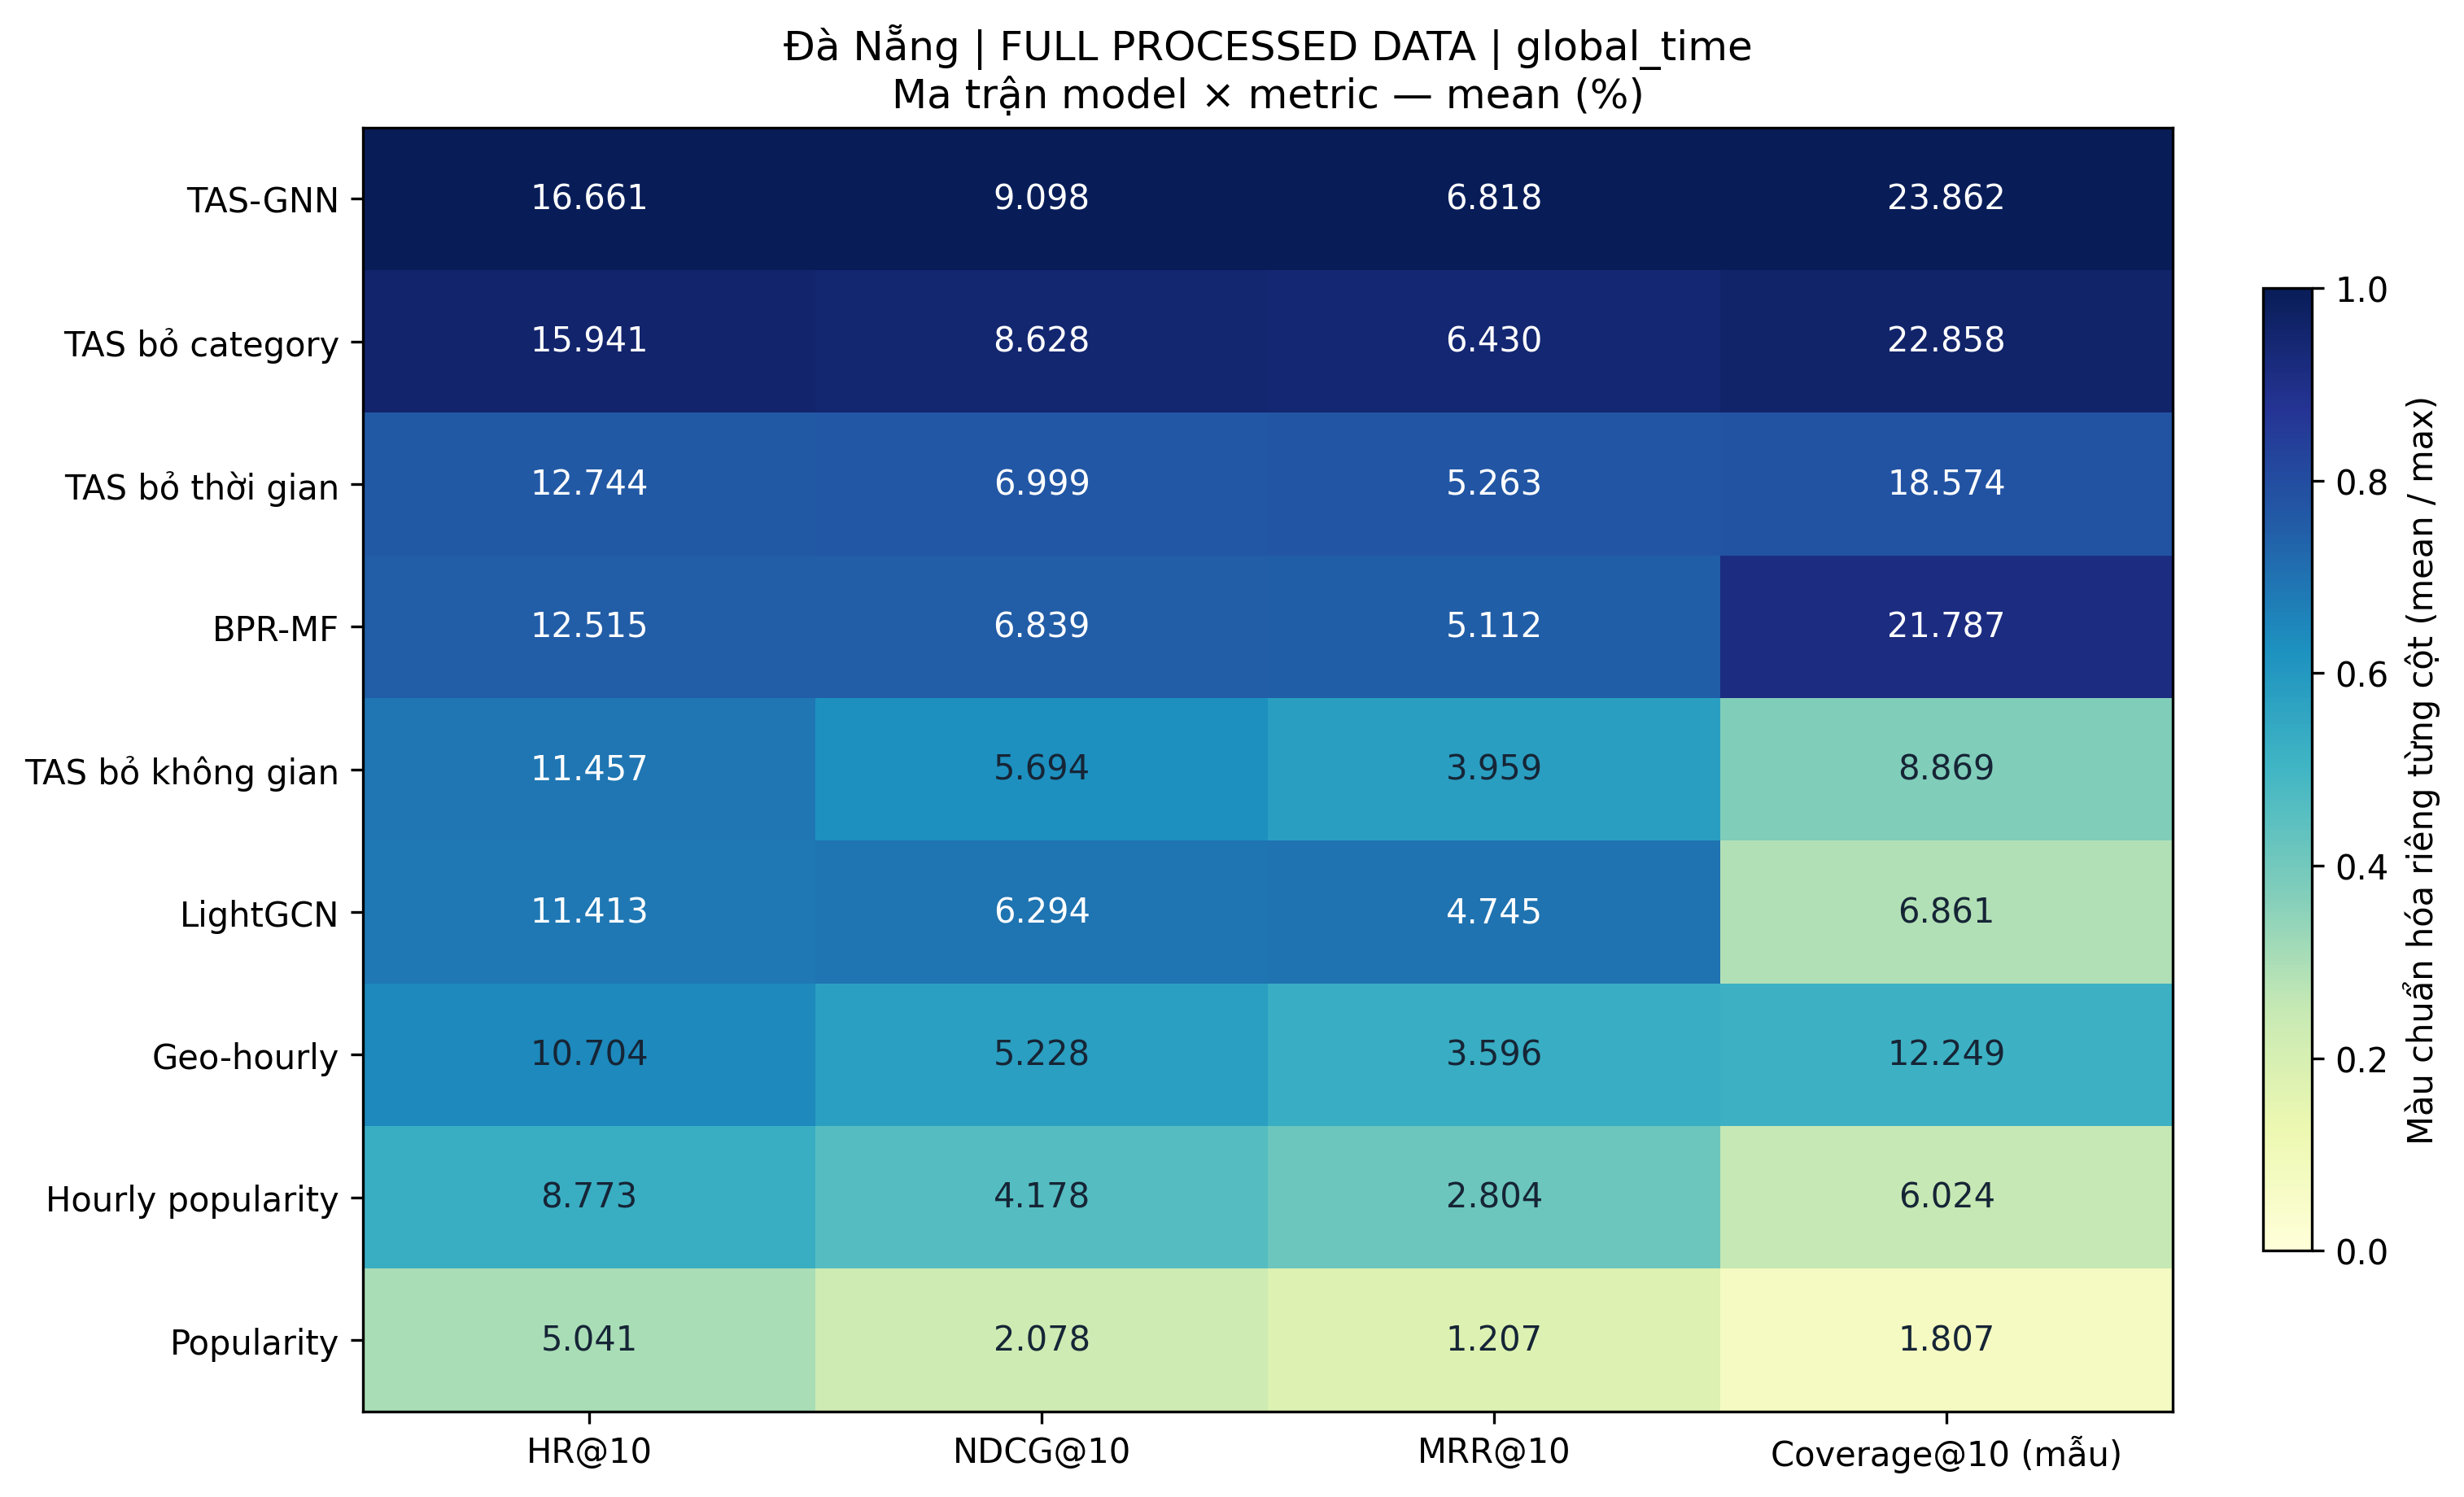


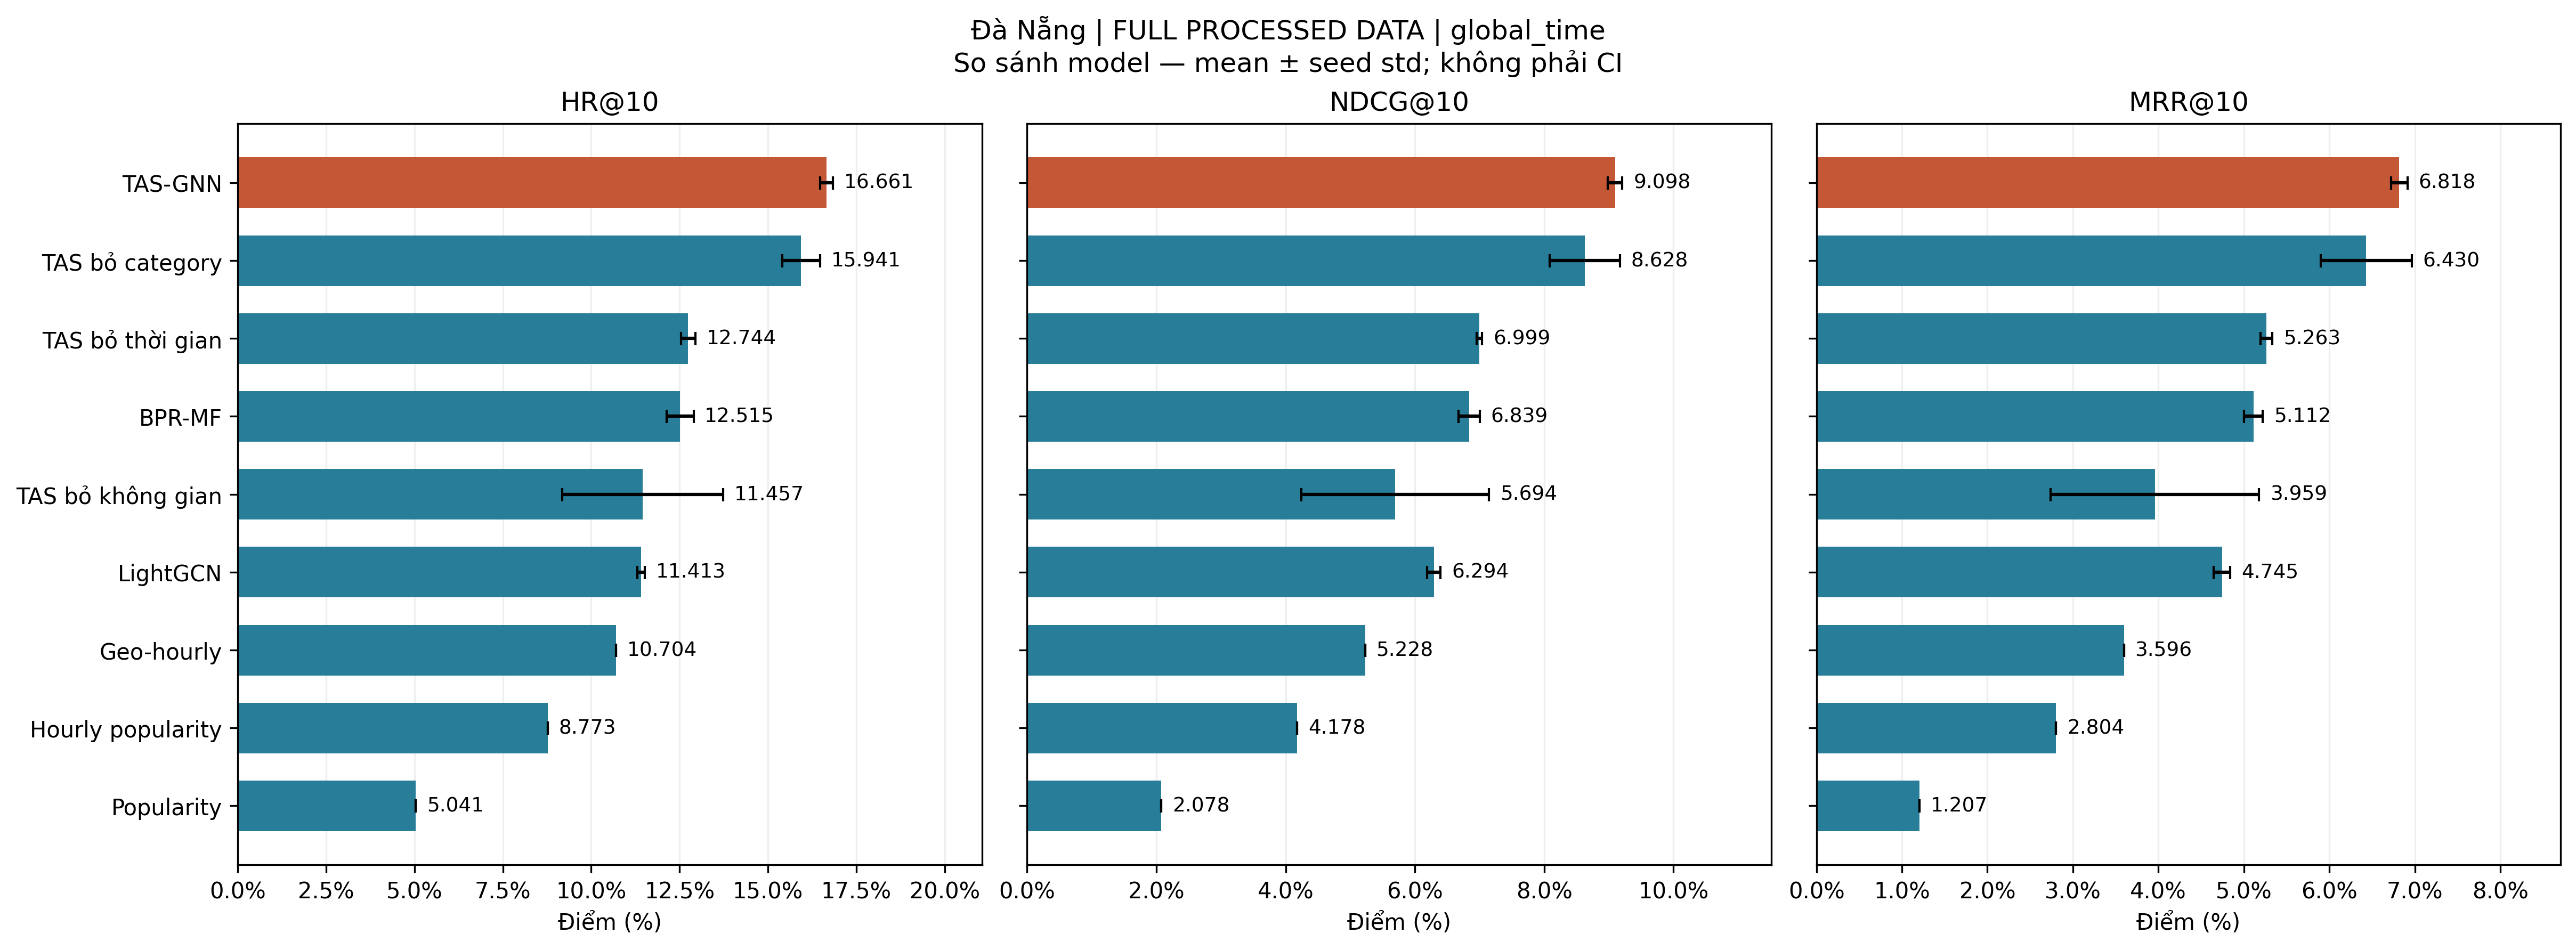


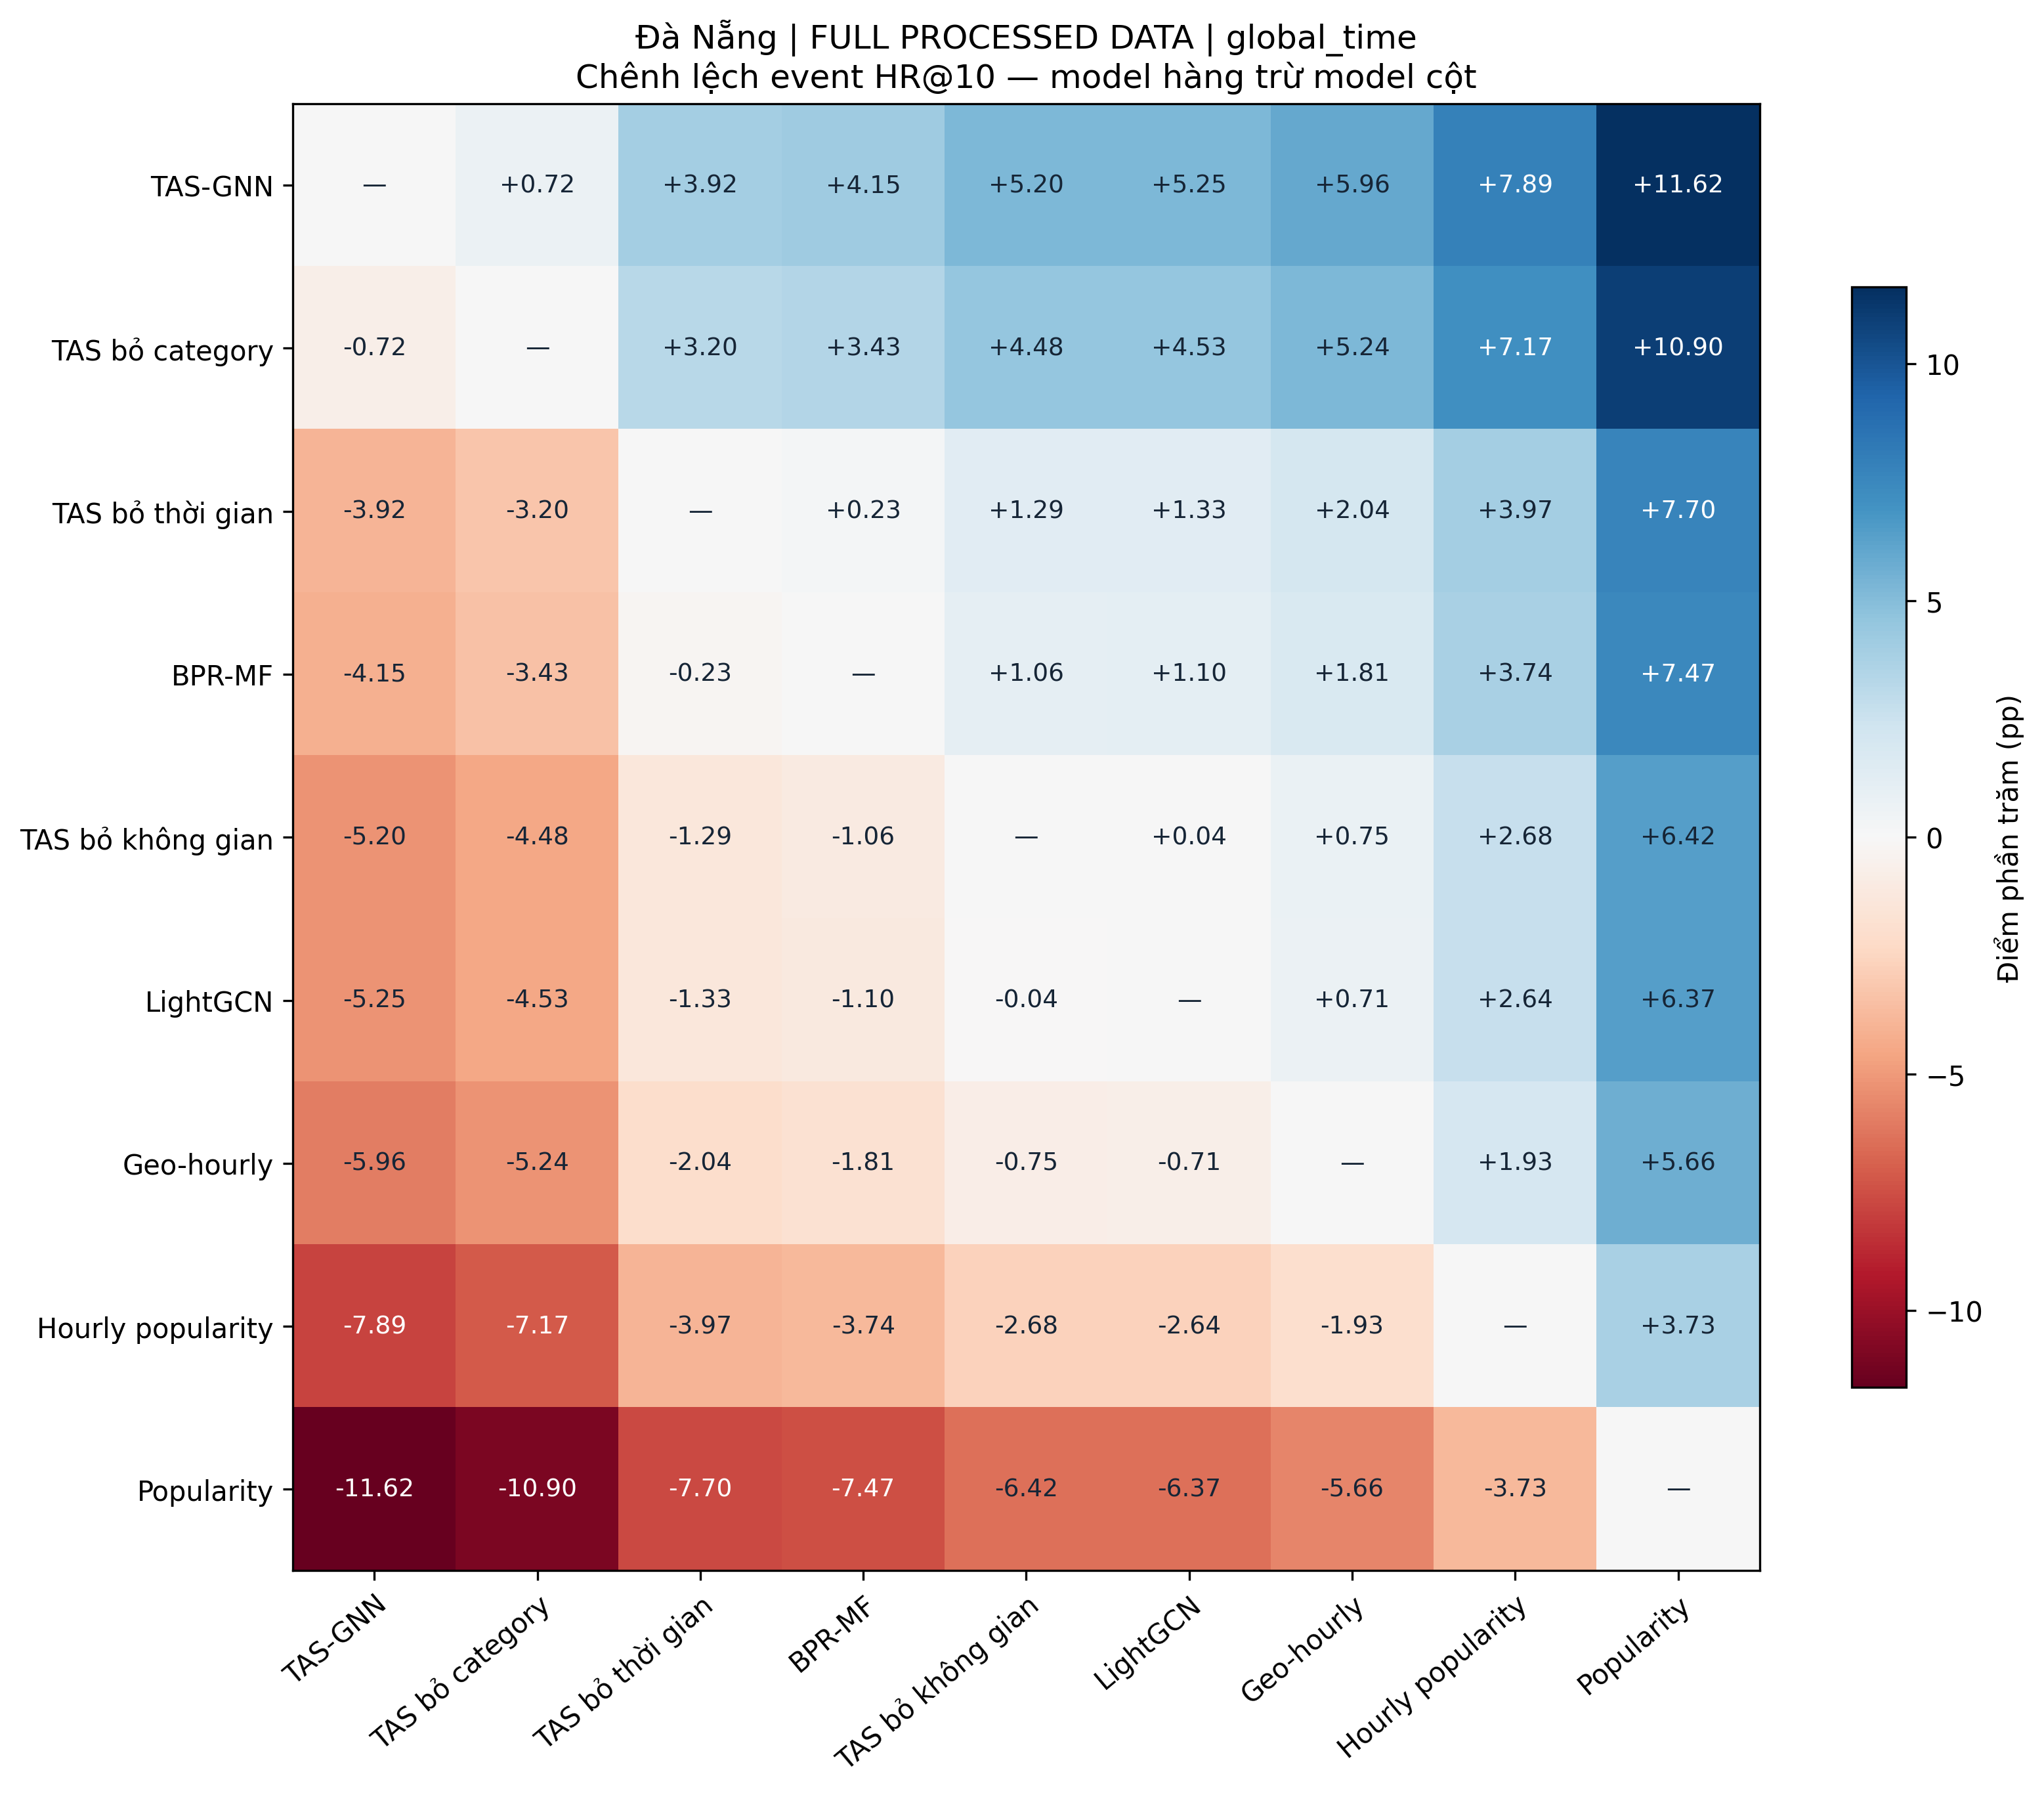


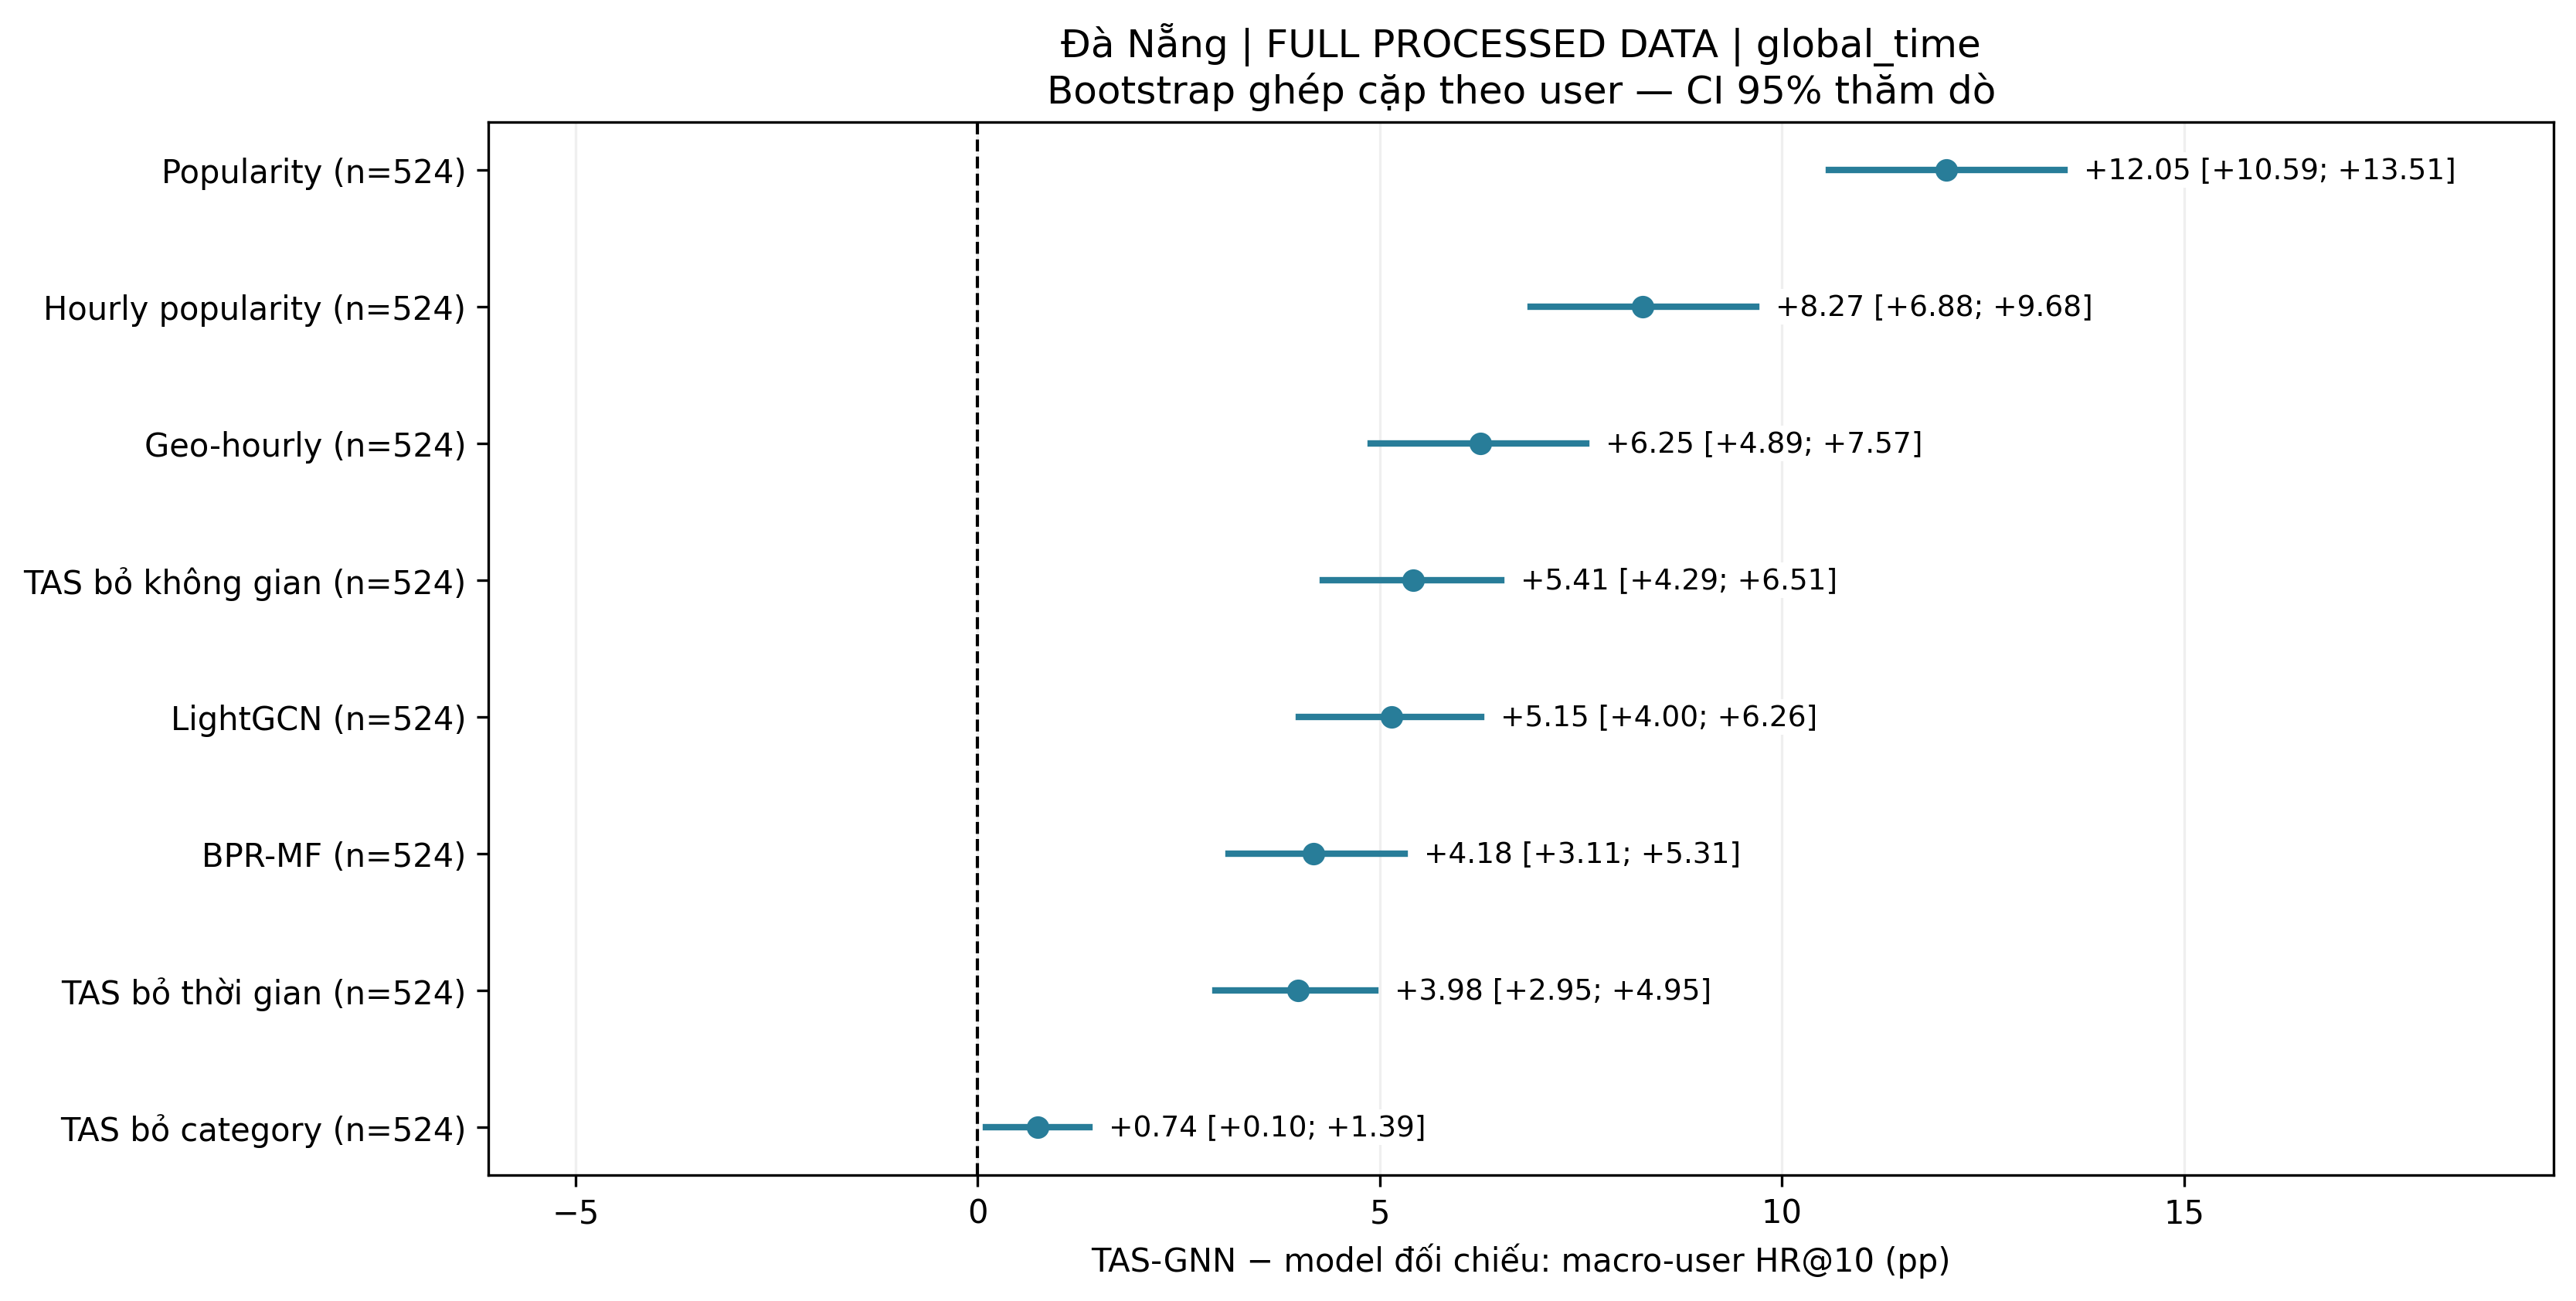


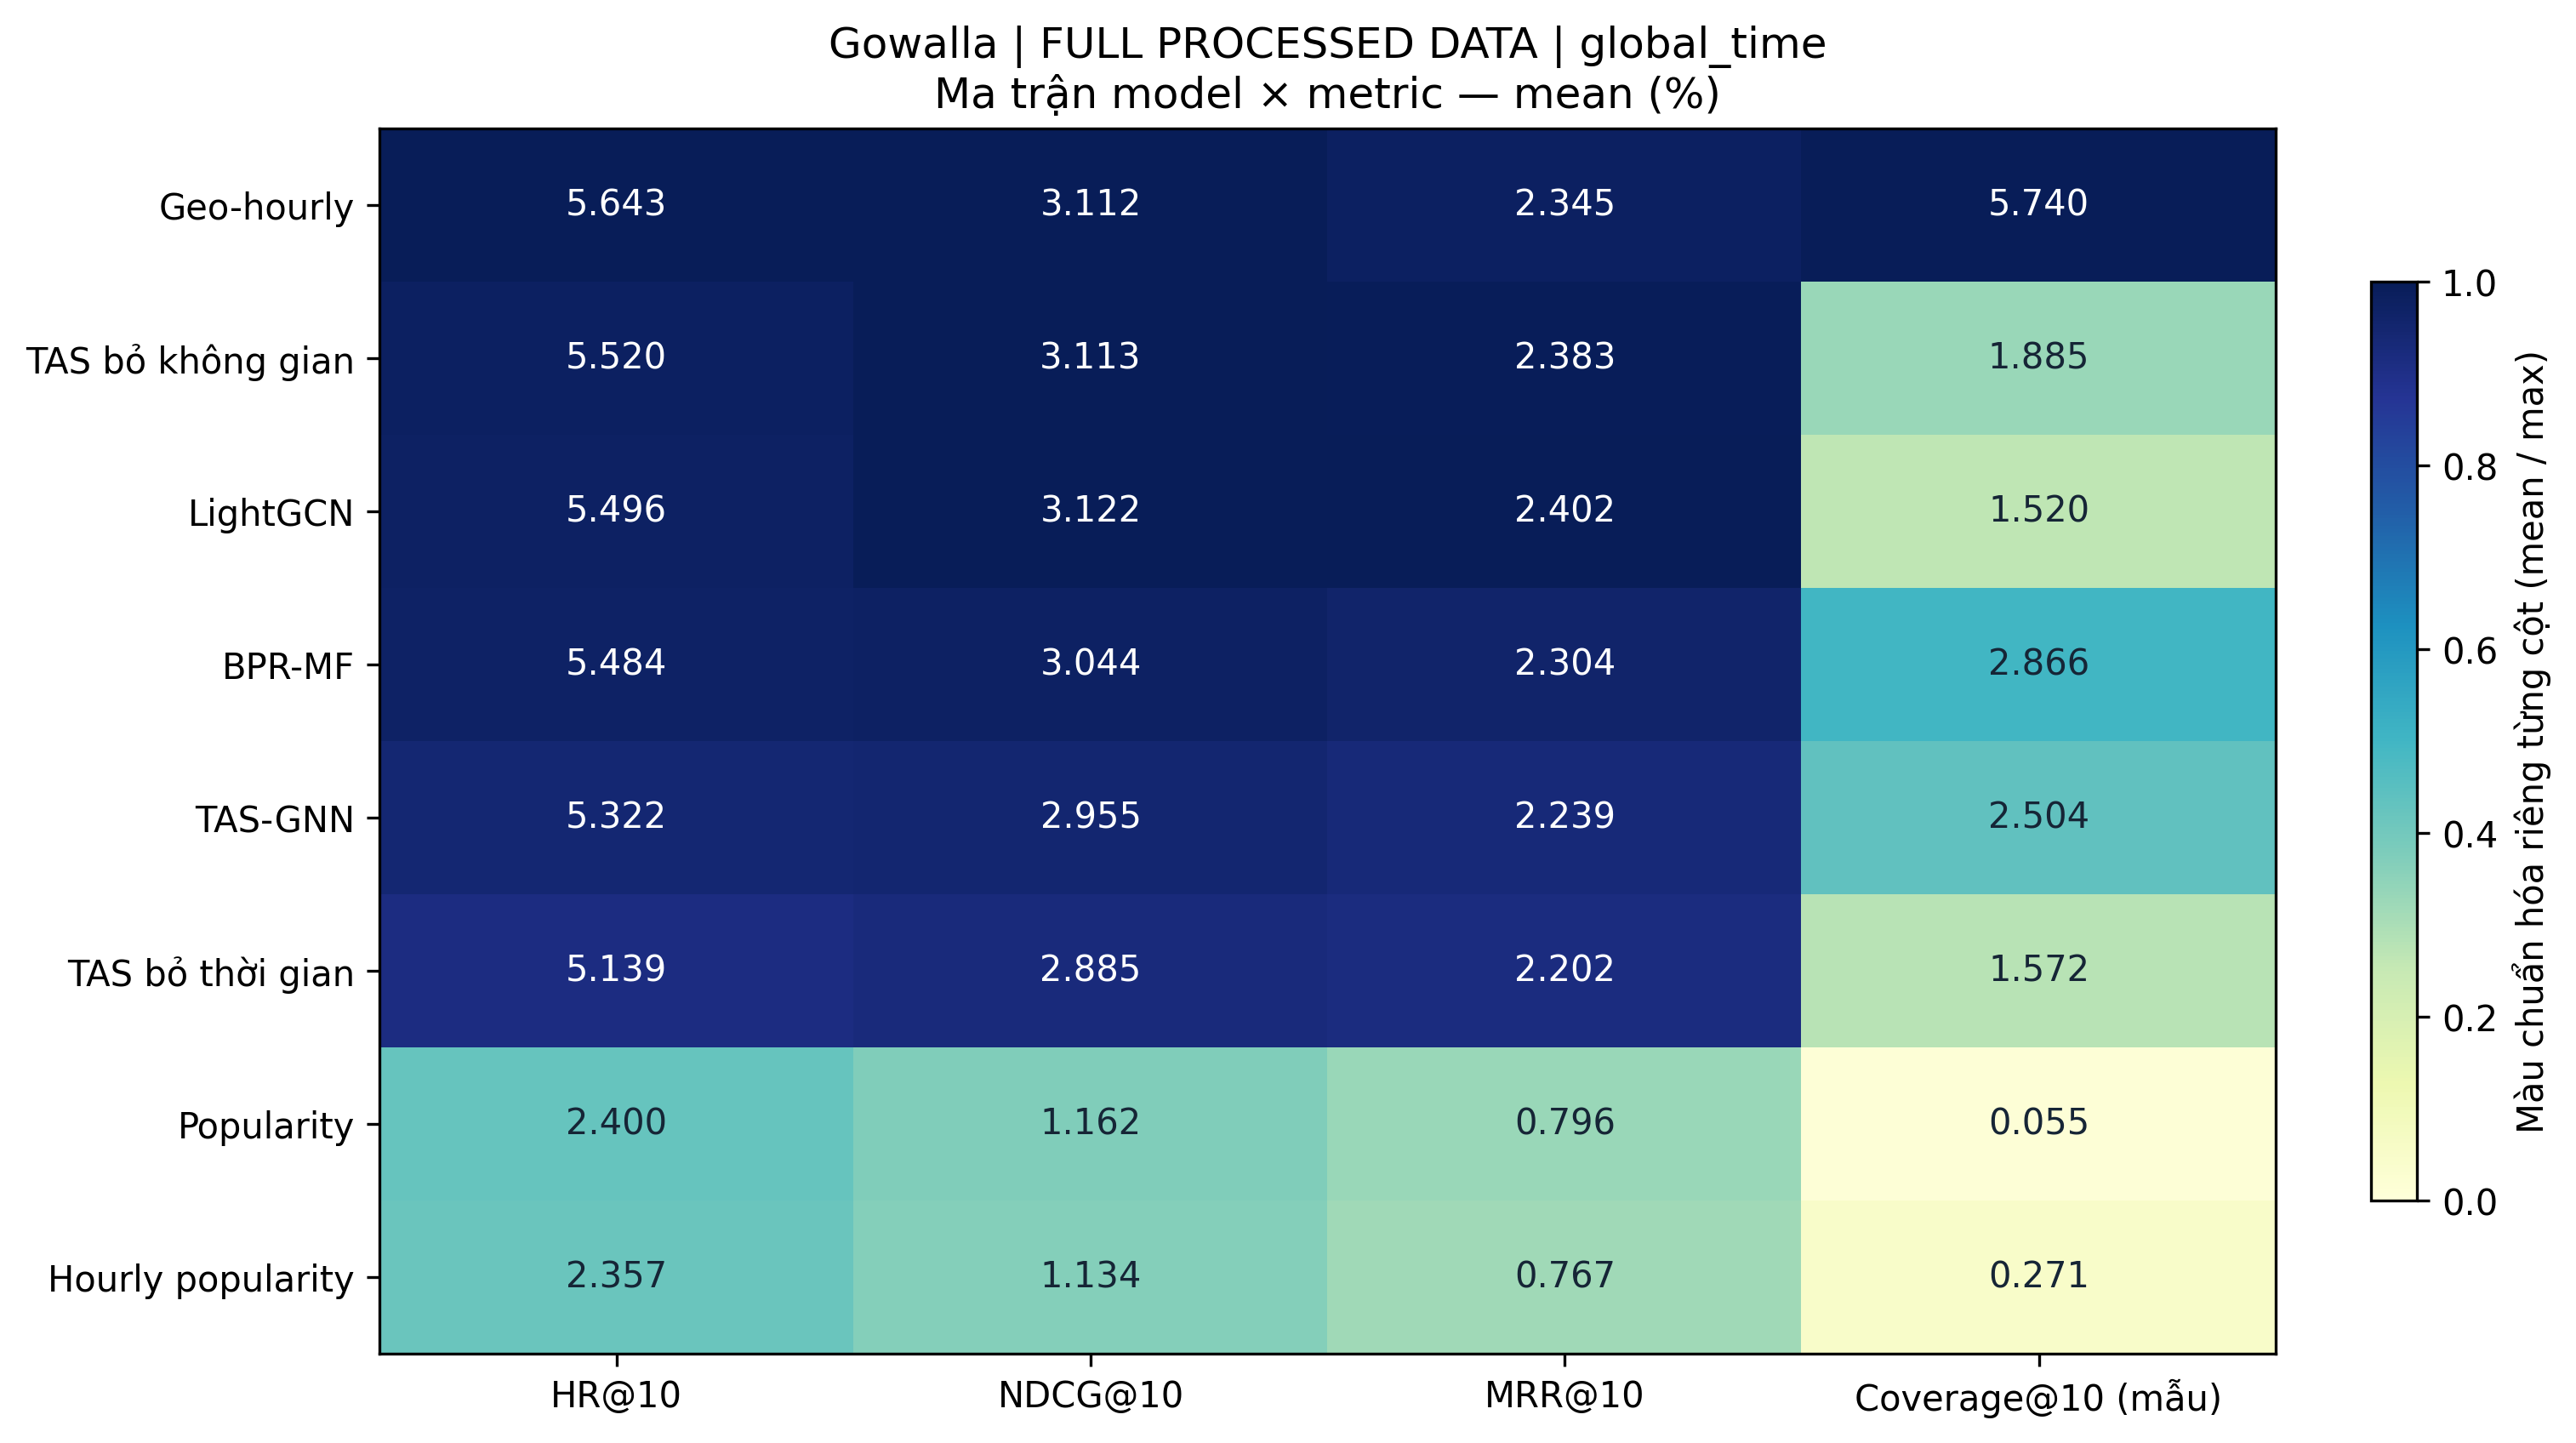


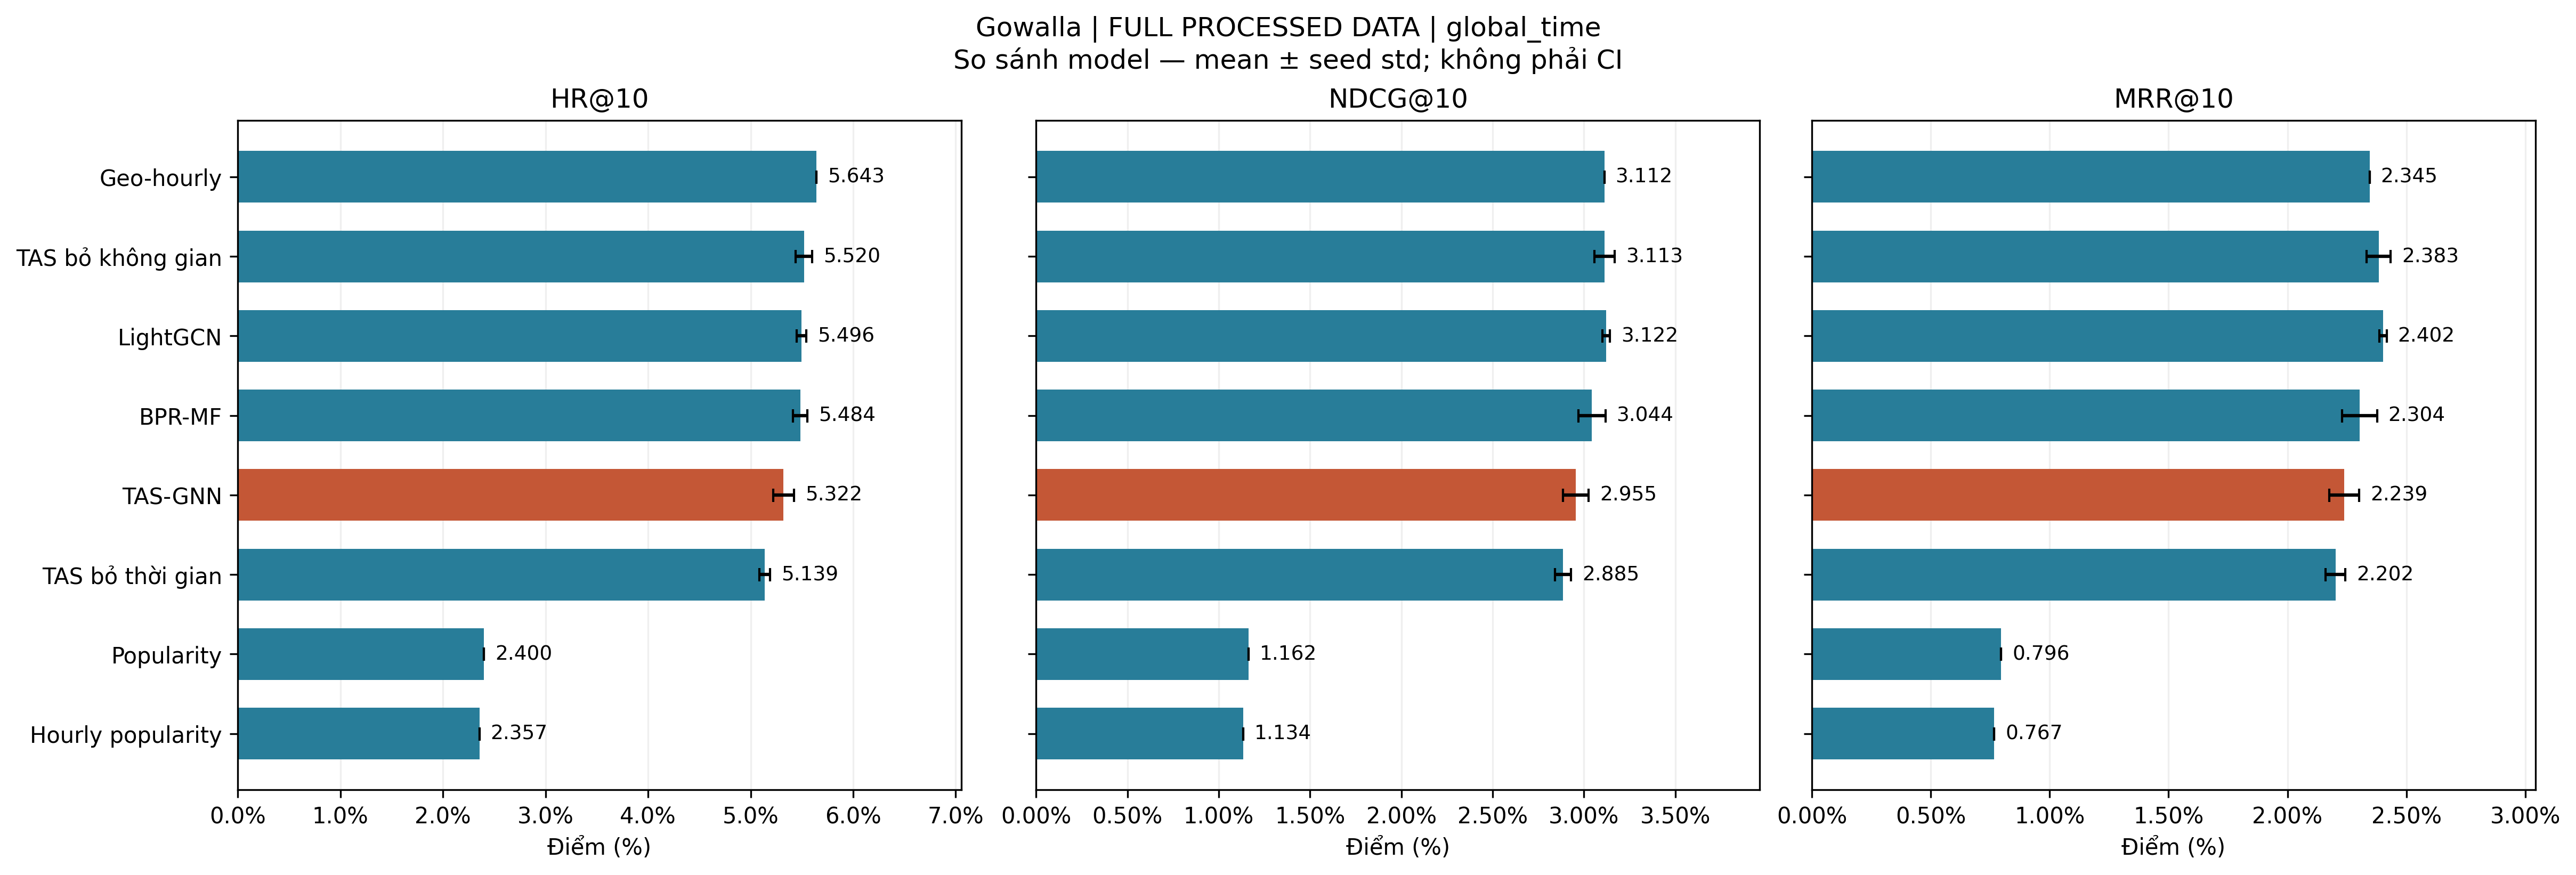


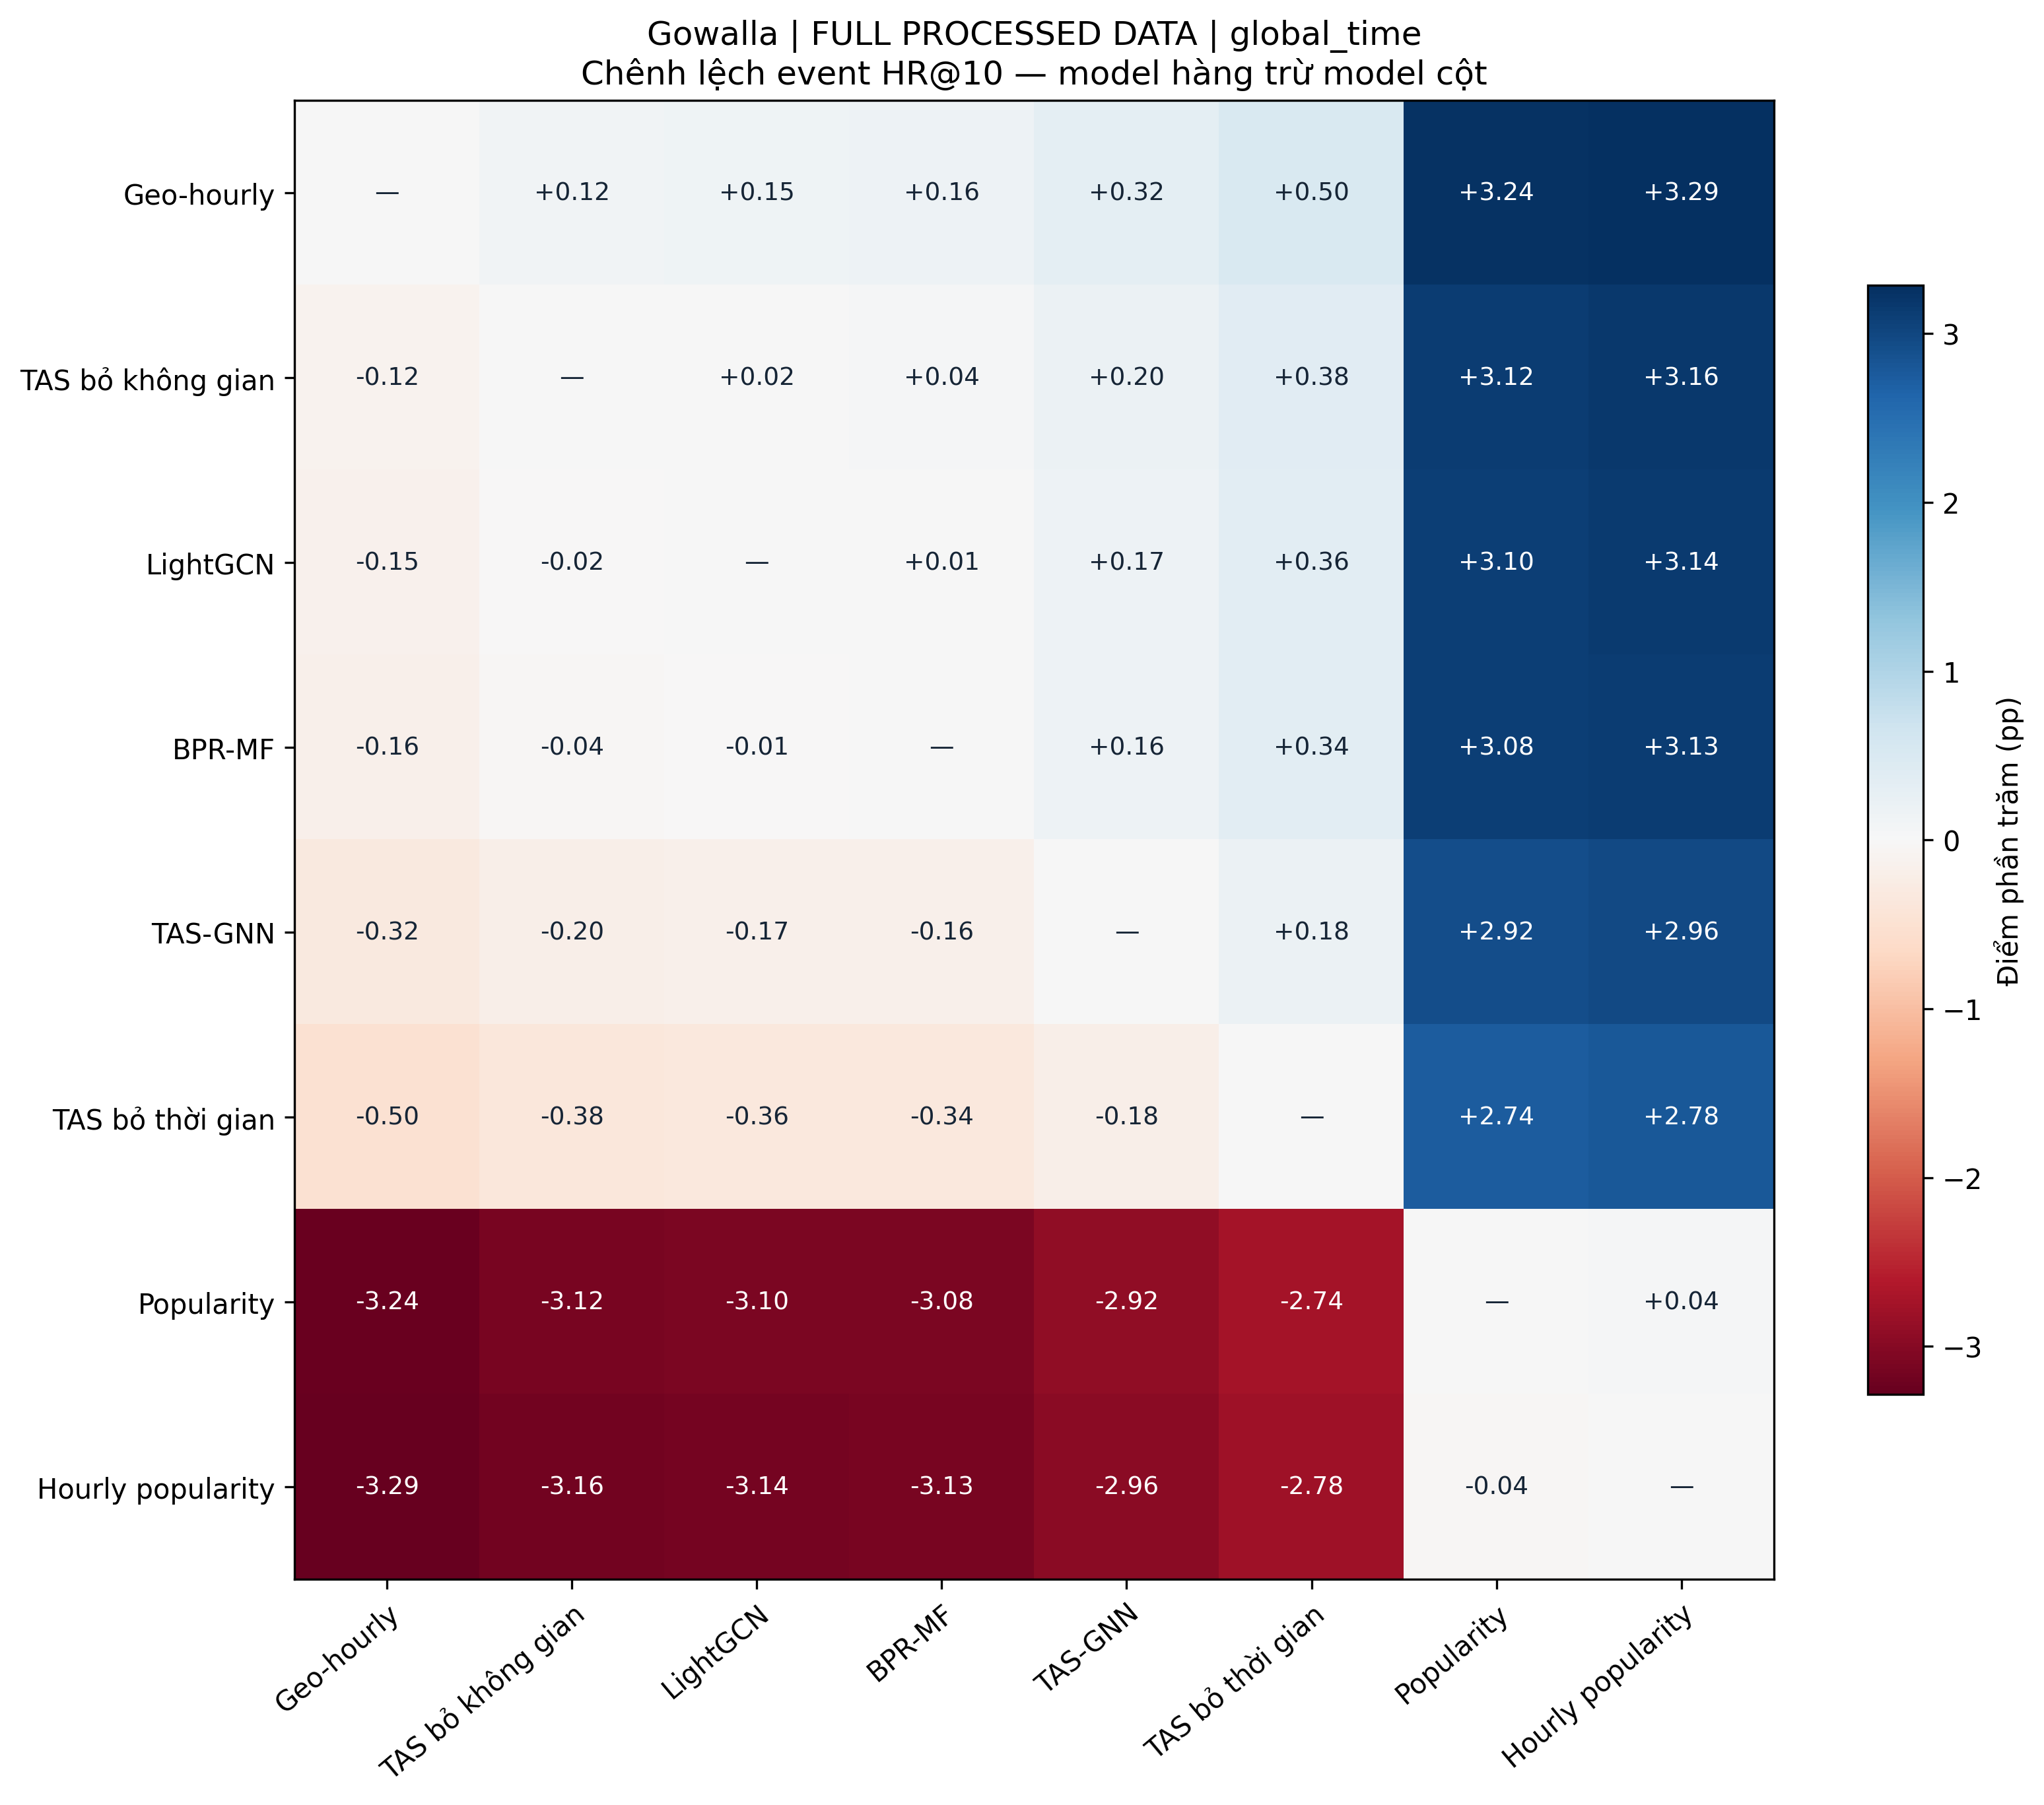


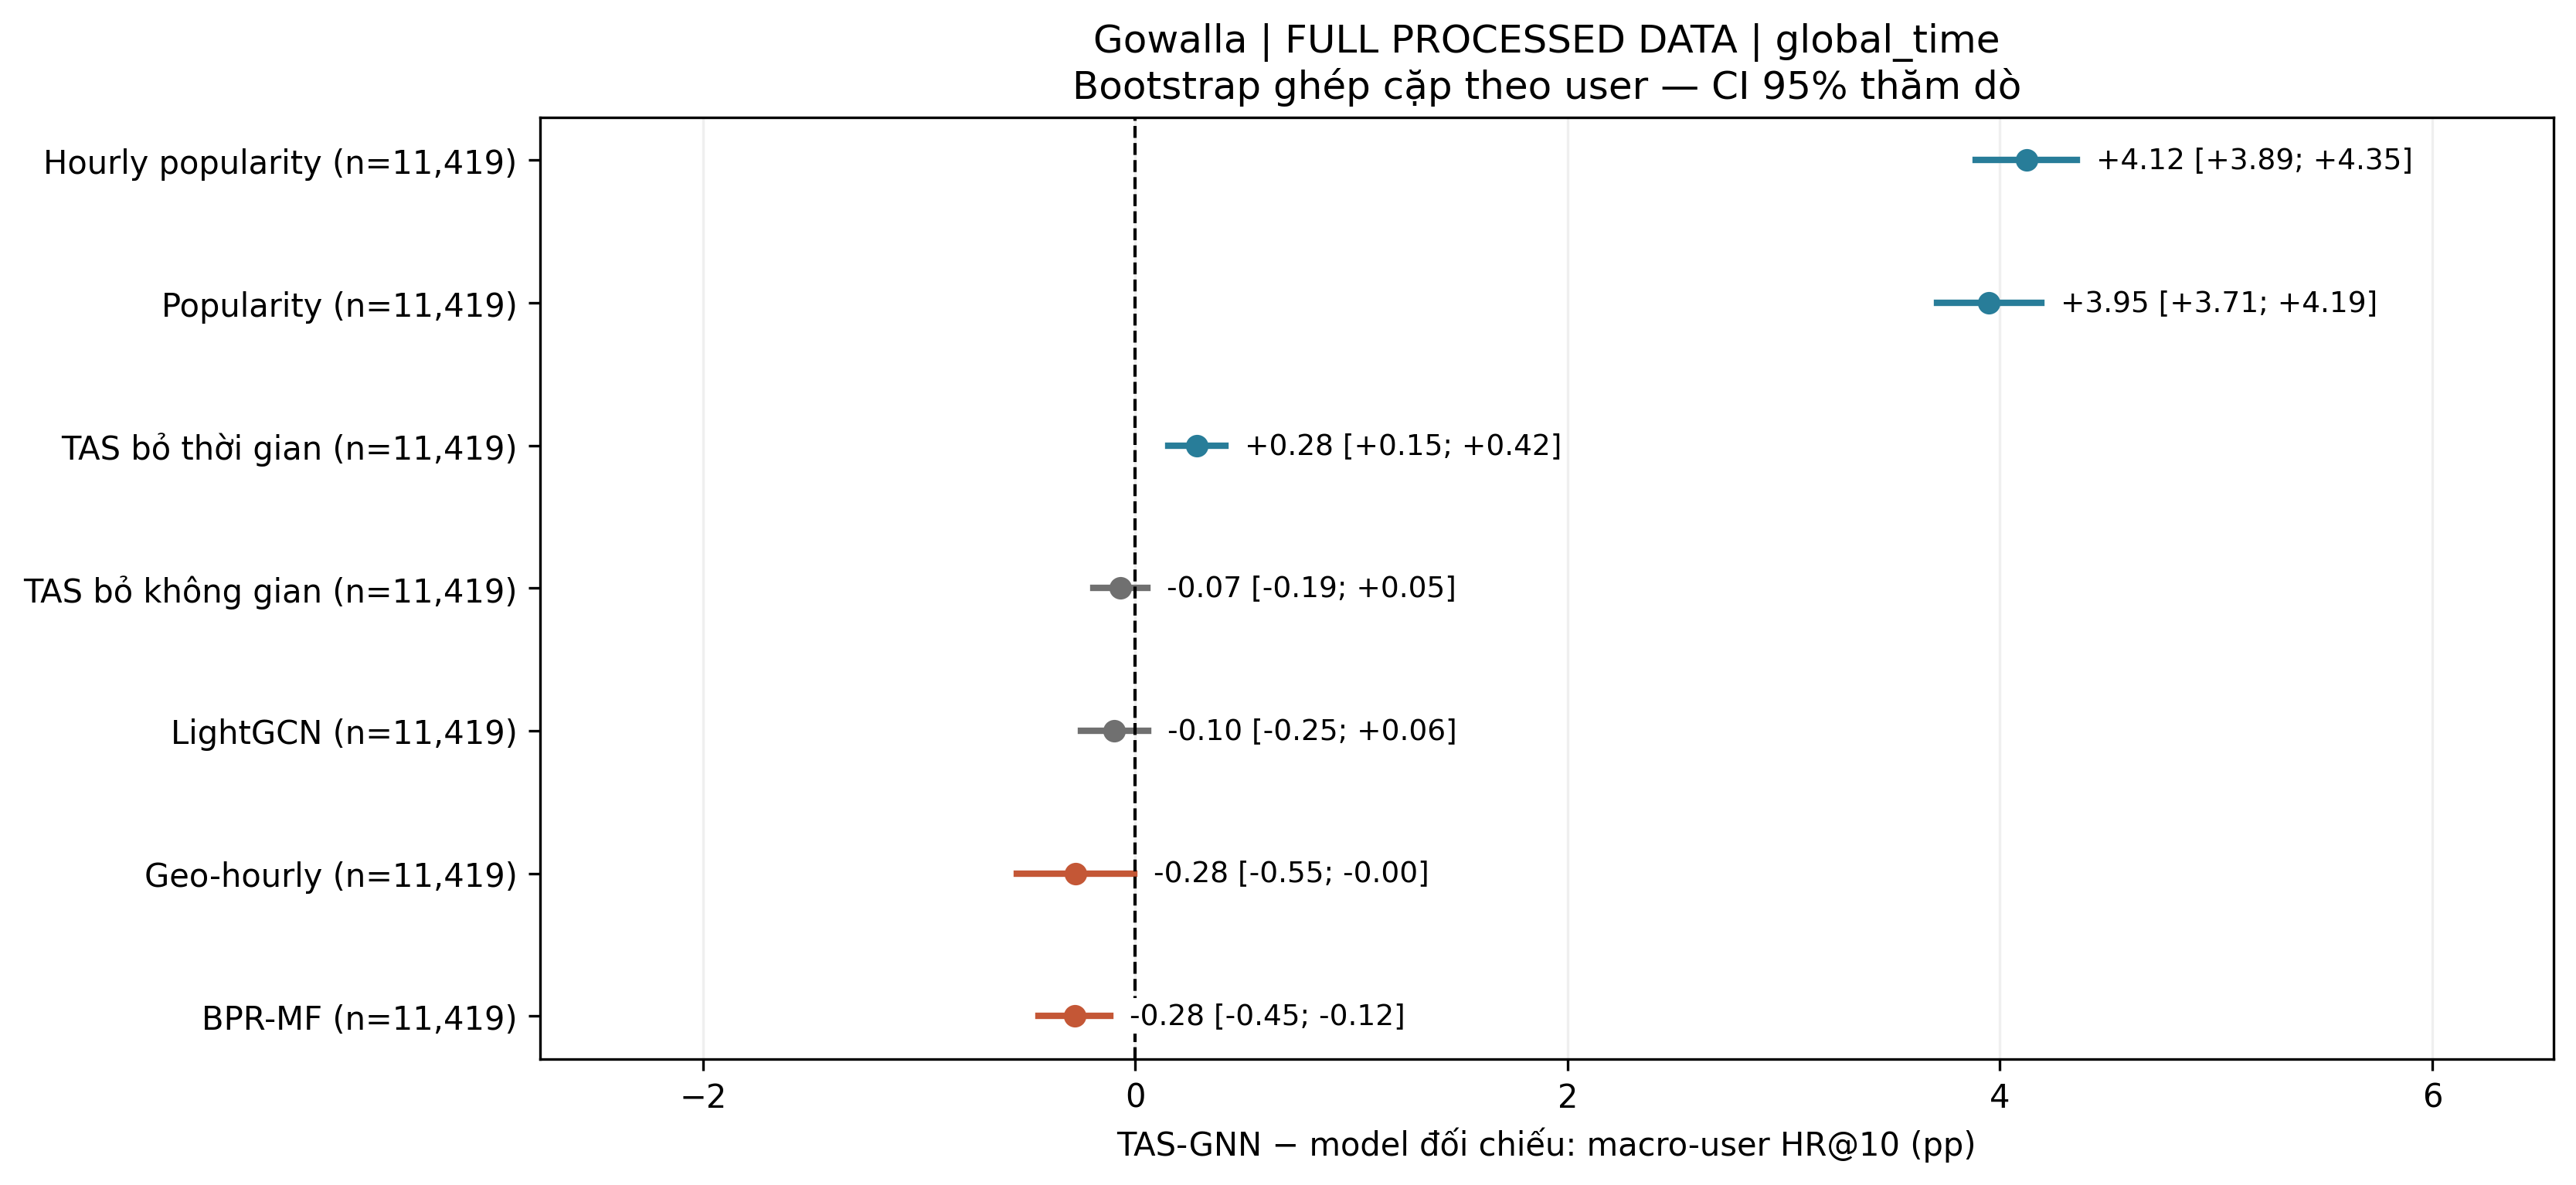

Báo cáo HTML: /content/dss_colab_v2/artifacts/full_global_time_641d6a1a/research_report.html
Ảnh PNG 300 dpi + SVG: /content/dss_colab_v2/artifacts/full_global_time_641d6a1a/report_figures
Bảng số liệu CSV: /content/dss_colab_v2/artifacts/full_global_time_641d6a1a/report_tables
Chạy cell xuất ZIP tiếp theo để tải cả báo cáo và hình.


In [15]:
# Kết luận, ma trận và biểu đồ dùng trong báo cáo
# Chạy lại cell này sau mục 5 để xuất hình; không cần huấn luyện lại nếu kernel còn kết quả.
import base64
from html import escape
from IPython.display import HTML, Markdown, display
from matplotlib.ticker import PercentFormatter


# Display limits only; exported PNG/SVG files retain their original resolution.
REPORT_PREVIEW_WIDTH = 850
REPORT_PREVIEW_HEIGHT = 450


def report_preview_html(path, max_width=REPORT_PREVIEW_WIDTH, max_height=REPORT_PREVIEW_HEIGHT):
    payload = Path(path).read_bytes()
    if payload[:8] != b"\x89PNG\r\n\x1a\n":
        raise ValueError("Report preview expects a PNG file")
    width = int.from_bytes(payload[16:20], "big")
    height = int.from_bytes(payload[20:24], "big")
    scale = min(1.0, max_width / width, max_height / height)
    preview_width, preview_height = max(1, round(width * scale)), max(1, round(height * scale))
    encoded = base64.b64encode(payload).decode("ascii")
    return (f'<div style="width:100%;max-width:{max_width}px;margin:16px auto;">'
            f'<img src="data:image/png;base64,{encoded}" alt="{escape(Path(path).name)}" '
            f'width="{preview_width}" height="{preview_height}" '
            'style="display:block;max-width:100%;height:auto;margin:0 auto;" /></div>')


def export_research_report(aggregate, bootstrap, quality, splits, datasets, output,
                           run_mode, protocol, seeds, source_note=""):
    """Export observed aggregate results only; never reconstruct individual seeds."""
    output = Path(output)
    figure_dir, table_dir = output / "report_figures", output / "report_tables"
    figure_dir.mkdir(parents=True, exist_ok=True)
    table_dir.mkdir(parents=True, exist_ok=True)
    metric_names = ["HR@10", "NDCG@10", "MRR@10", "sample_catalog_coverage_at_10"]
    metric_labels = ["HR@10", "NDCG@10", "MRR@10", "Coverage@10 (mẫu)"]
    model_labels = {"popularity": "Popularity", "hourly_popularity": "Hourly popularity",
                    "geo_hourly": "Geo-hourly", "bpr_mf": "BPR-MF", "lightgcn": "LightGCN",
                    "tas_gnn": "TAS-GNN", "tas_no_time": "TAS bỏ thời gian",
                    "tas_no_space": "TAS bỏ không gian", "tas_no_category": "TAS bỏ category"}
    dataset_labels = {"danang": "Đà Nẵng", "gowalla": "Gowalla"}
    md, html_parts, figure_paths = [], [], []

    def heading(text, level=2):
        md.append("#" * level + " " + text)
        html_parts.append(f"<h{level}>{escape(text)}</h{level}>")

    def paragraph(text):
        md.append(text)
        html_parts.append(f"<p>{escape(text)}</p>")

    def table(frame):
        # No tabulate dependency in the standalone Colab notebook.
        flat = frame.reset_index().astype(str)
        clean = lambda value: str(value).replace("|", "\\|").replace("\n", " ")
        lines = ["| " + " | ".join(map(clean, flat.columns)) + " |",
                 "| " + " | ".join(["---"] * len(flat.columns)) + " |"]
        lines += ["| " + " | ".join(map(clean, row)) + " |" for row in flat.to_numpy()]
        md.append("\n".join(lines))
        html_parts.append(frame.to_html(escape=True, border=0))

    def save_figure(fig, stem, caption):
        png, svg = figure_dir / f"{stem}.png", figure_dir / f"{stem}.svg"
        fig.savefig(png, dpi=300, bbox_inches="tight", facecolor="white")
        fig.savefig(svg, bbox_inches="tight", facecolor="white")
        plt.close(fig)
        relative = png.relative_to(output).as_posix()
        md.append(f"{caption}\n\n[Ảnh PNG 300 dpi]({relative}) · "
                  f"[Ảnh SVG]({svg.relative_to(output).as_posix()})")
        payload = base64.b64encode(png.read_bytes()).decode("ascii")
        html_parts.append(f'<figure><img src="data:image/png;base64,{payload}" '
                          f'alt="{escape(caption)}"><figcaption>{escape(caption)}</figcaption></figure>')
        figure_paths.append(png)

    heading("Báo cáo lượt chạy POI", 1)
    paragraph(f"Run mode: {run_mode}; protocol: {protocol}; seeds: {list(seeds)}.")
    if source_note:
        paragraph(source_note)
    if run_mode == "smoke":
        paragraph("SMOKE: chỉ kiểm tra luồng kỹ thuật; không dùng số liệu này làm benchmark chất lượng.")
    paragraph("Các bảng xếp hạng dùng novel test events của warm users. Mean ± std là trung bình "
              "và độ lệch chuẩn giữa seed; std không phải khoảng tin cậy. NDCG/MRR được trình bày "
              "theo thang 0–100; điểm model không phải xác suất thích địa điểm.")
    paragraph("Mỗi dataset có catalog và candidate set riêng; chỉ so sánh model trong cùng dataset. "
              "Coverage@10 đo trên mẫu query cố định, không đại diện toàn bộ traffic.")

    for name in datasets:
        data = aggregate.xs(name, level="dataset")
        order = data[("HR@10", "mean")].sort_values(ascending=False, kind="stable").index
        data = data.loc[order]
        means = data.loc[:, [(metric, "mean") for metric in metric_names]].copy()
        stds = data.loc[:, [(metric, "std") for metric in metric_names]].copy()
        counts = data.loc[:, [(metric, "count") for metric in metric_names]].copy()
        means.columns = stds.columns = counts.columns = metric_names
        if means.empty or not np.isfinite(means.to_numpy()).all():
            raise ValueError(f"{name}: thiếu mean hữu hạn; cần hoàn thành đánh giá trước khi xuất báo cáo")
        labels = [model_labels.get(model, model) for model in order]
        subset = bool(quality[name].get("source_metadata", {}).get("is_subset"))
        scope = "SMOKE" if run_mode == "smoke" else ("USER SUBSET" if subset else "FULL PROCESSED DATA")
        title = f"{dataset_labels.get(name, name)} | {scope} | {protocol}"
        n_seed = counts["HR@10"].astype(int)
        heading(dataset_labels.get(name, name))
        if subset:
            paragraph("USER SUBSET: kết quả của tập con, không phải benchmark trên toàn bộ dữ liệu sau lọc.")
        profile, split = quality[name], splits[name]
        paragraph(f"Dữ liệu: {profile['users']:,} user, {profile['pois']:,} POI, {profile['events']:,} sự kiện. "
                  f"Novel test: {split['novel_test_events']:,} sự kiện; "
                  f"{split['repeated_test_percent']:.2f}% test warm-user là lượt quay lại và bị loại khỏi novel metric; "
                  f"{split['test_cold_user_events_excluded']:,} cold-user test events bị loại khỏi đánh giá warm-user.")

        numeric = pd.DataFrame(index=order)
        formatted = pd.DataFrame(index=order)
        numeric.index.name = formatted.index.name = "model"
        for metric, label in zip(metric_names, metric_labels):
            numeric[f"{metric}_mean"] = means[metric]
            numeric[f"{metric}_std"] = stds[metric]
            numeric[f"{metric}_seed_count"] = counts[metric].astype(int)
            formatted[label + " (%, mean ± std)"] = [
                f"{100 * mean:.3f} ± {100 * std:.3f}" if count > 1 and np.isfinite(std)
                else f"{100 * mean:.3f} (1 seed; chưa ước lượng std)"
                for mean, std, count in zip(means[metric], stds[metric], counts[metric])]
        formatted["Số seed"] = n_seed
        numeric.to_csv(table_dir / f"{name}_metrics.csv", encoding="utf-8-sig")
        means.to_csv(table_dir / f"{name}_metric_matrix.csv", encoding="utf-8-sig")
        table(formatted)

        winner = order[0]
        tied = order[np.isclose(means["HR@10"], means.loc[winner, "HR@10"], rtol=0, atol=1e-12)]
        paragraph("Model có event HR@10 mean cao nhất trong lượt chạy: "
                  + ", ".join(model_labels.get(model, model) for model in tied)
                  + f" ({100 * means.loc[winner, 'HR@10']:.3f}%). "
                  "Thứ hạng này mô tả test hiện tại, không dùng để chọn lại hyperparameter.")
        if "tas_gnn" in means.index:
            references = means.loc[~means.index.str.startswith("tas_"), "HR@10"]
            if not references.empty:
                reference = references.idxmax()
                delta = 100 * (means.loc["tas_gnn", "HR@10"] - references[reference])
                paragraph(f"TAS-GNN so với baseline có event HR@10 mean cao nhất "
                          f"({model_labels.get(reference, reference)}): {delta:+.3f} điểm phần trăm. "
                          "Đây là chênh lệch trung bình theo event, khác estimand macro-user của bootstrap bên dưới.")

        with plt.rc_context({"font.family": "DejaVu Sans", "font.size": 10}):
            # Columns use separate color normalization; annotations retain observed means.
            values = means.to_numpy() * 100
            normalized = values / np.maximum(values.max(axis=0, keepdims=True), 1e-12)
            fig, ax = plt.subplots(figsize=(10, max(4.8, len(order) * .48 + 1.7)), layout="constrained")
            im = ax.imshow(normalized, cmap="YlGnBu", aspect="auto", vmin=0, vmax=1)
            ax.set(xticks=range(len(metric_labels)), xticklabels=metric_labels,
                   yticks=range(len(order)), yticklabels=labels,
                   title=f"{title}\nMa trận model × metric — mean (%)")
            for row in range(len(order)):
                for col in range(len(metric_names)):
                    ax.text(col, row, f"{values[row, col]:.3f}", ha="center", va="center",
                            color="white" if normalized[row, col] > .65 else "#162536")
            fig.colorbar(im, ax=ax, shrink=.75, label="Màu chuẩn hóa riêng từng cột (mean / max)")
            save_figure(fig, f"{name}_metric_matrix",
                        "Ma trận metric: số trong ô là mean (%); màu chuẩn hóa riêng theo cột, không so màu giữa dataset.")

            fig, axes = plt.subplots(1, 3, figsize=(16, max(5.2, len(order) * .47 + 1.6)),
                                     sharey=True, layout="constrained")
            colors = ["#c45736" if model == "tas_gnn" else "#287d99" for model in order]
            positions = np.arange(len(order))
            for ax, metric in zip(axes, metric_names[:3]):
                x = means[metric].to_numpy() * 100
                errors = stds[metric].fillna(0).to_numpy() * 100
                ax.barh(positions, x, xerr=errors, color=colors, capsize=3, height=.65)
                ax.set(title=metric, xlabel="Điểm (%)", yticks=positions, yticklabels=labels)
                ax.xaxis.set_major_formatter(PercentFormatter(100))
                ax.grid(axis="x", alpha=.2)
                ax.set_axisbelow(True)
                ax.set_xlim(0, max(.01, np.max(x + errors)) * 1.25)
                for row, (mean, error) in enumerate(zip(x, errors)):
                    ax.annotate(f"{mean:.3f}", (mean + error, row), xytext=(5, 0),
                                textcoords="offset points", va="center", fontsize=9)
            axes[0].invert_yaxis()
            fig.suptitle(f"{title}\nSo sánh model — mean ± seed std; không phải CI")
            save_figure(fig, f"{name}_model_comparison",
                        "So sánh HR@10, NDCG@10, MRR@10. Thanh sai số = seed std; một seed không có ước lượng std.")

            delta_matrix = (means["HR@10"].to_numpy()[:, None]
                            - means["HR@10"].to_numpy()[None, :]) * 100
            delta_frame = pd.DataFrame(delta_matrix, index=order, columns=order)
            delta_frame.index.name = "row_model_minus_column_model"
            delta_frame.to_csv(table_dir / f"{name}_pairwise_hr10_delta_pp.csv", encoding="utf-8-sig")
            bound = max(float(np.abs(delta_matrix).max()), .001)
            fig, ax = plt.subplots(figsize=(11, 9), layout="constrained")
            im = ax.imshow(delta_matrix, cmap="RdBu", vmin=-bound, vmax=bound)
            ax.set(xticks=range(len(order)), xticklabels=labels,
                   yticks=range(len(order)), yticklabels=labels,
                   title=f"{title}\nChênh lệch event HR@10 — model hàng trừ model cột")
            plt.setp(ax.get_xticklabels(), rotation=40, ha="right", rotation_mode="anchor")
            for row in range(len(order)):
                for col in range(len(order)):
                    ax.text(col, row, "—" if row == col else f"{delta_matrix[row, col]:+.2f}",
                            ha="center", va="center", fontsize=9,
                            color="white" if abs(delta_matrix[row, col]) > bound * .6 else "#162536")
            fig.colorbar(im, ax=ax, shrink=.75, label="Điểm phần trăm (pp)")
            save_figure(fig, f"{name}_pairwise_hr10_delta",
                        "Ma trận chênh lệch HR@10 (pp): dương nghĩa là model hàng cao hơn model cột; không phải kiểm định thống kê.")

            intervals = bootstrap.get(name, pd.DataFrame())
            if not intervals.empty:
                intervals = intervals.sort_values("macro_user_HR10_difference", ascending=False).copy()
                intervals.to_csv(table_dir / f"{name}_paired_user_ci.csv", index=False, encoding="utf-8-sig")
                fig, ax = plt.subplots(figsize=(11, max(4.6, len(intervals) * .5 + 1.5)), layout="constrained")
                for row, (_, value) in enumerate(intervals.iterrows()):
                    lo, hi = 100 * value.ci95_low, 100 * value.ci95_high
                    mean = 100 * value.macro_user_HR10_difference
                    color = "#287d99" if lo > 0 else ("#c45736" if hi < 0 else "#707070")
                    ax.plot([lo, hi], [row, row], color=color, linewidth=2)
                    ax.plot(mean, row, "o", color=color)
                    ax.annotate(f"{mean:+.2f} [{lo:+.2f}; {hi:+.2f}]", (hi, row),
                                xytext=(6, 0), textcoords="offset points", va="center", fontsize=9,
                                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.2})
                ax.axvline(0, color="black", linestyle="--", linewidth=1)
                ax.set(yticks=range(len(intervals)),
                       yticklabels=[f"{model_labels.get(row.reference, row.reference)} (n={int(row.users):,})"
                                    for row in intervals.itertuples()],
                       xlabel="TAS-GNN − model đối chiếu: macro-user HR@10 (pp)",
                       title=f"{title}\nBootstrap ghép cặp theo user — CI 95% thăm dò")
                ax.margins(x=.45)
                ax.invert_yaxis()
                ax.grid(axis="x", alpha=.2)
                save_figure(fig, f"{name}_paired_user_ci",
                            "Chênh lệch macro-user HR@10 và CI 95%. Seed được trung bình trong từng user trước bootstrap; "
                            "CI chứa 0 chưa cho thấy chiều cải thiện rõ; chưa hiệu chỉnh nhiều so sánh.")
                ci_table = intervals.set_index("reference")[["users", "macro_user_HR10_difference", "ci95_low", "ci95_high"]].copy()
                ci_table.columns = ["Số user", "Chênh lệch (pp)", "CI95 thấp (pp)", "CI95 cao (pp)"]
                ci_table.iloc[:, 1:] = ci_table.iloc[:, 1:] * 100
                table(ci_table.round(3))
            else:
                paragraph("Chưa có paired-user CI hợp lệ; không suy diễn độ chắc chắn từ bảng mean/std.")

        for warning in profile.get("warnings", []):
            paragraph("Giới hạn dữ liệu: " + warning)

    heading("Giới hạn chung")
    for text in ["Đà Nẵng dùng tương tác mô phỏng; Gowalla là hành vi lịch sử 2009–2010, giờ địa phương xấp xỉ và catalog đã lọc core.",
                 "Catalog/eligibility/core transductive; lịch sử fit cố định trong test.",
                 "DIM/LAYERS cố định; tuning chỉ trong grid learning rate và epoch đã khai báo.",
                 "Seed std và user bootstrap phản ánh hai nguồn bất định khác nhau; không phải bằng chứng nhân quả.",
                 "Chưa đánh giá user cold-start, người dùng thực trực tuyến, A/B test, calibration xác suất hoặc hiệu quả AHP/TOPSIS."]:
        paragraph(text)
    report_text = "\n\n".join(md) + "\n"
    (output / "research_summary.md").write_text(report_text, encoding="utf-8")
    html = ('<!doctype html><html lang="vi"><meta charset="utf-8">'
            '<meta name="viewport" content="width=device-width,initial-scale=1">'
            '<title>Báo cáo lượt chạy POI</title><style>'
            'body{font:16px/1.6 Arial,sans-serif;max-width:1200px;margin:40px auto;padding:0 24px;color:#162536}'
            'table{border-collapse:collapse;font-size:13px;display:block;overflow:auto}'
            'td,th{padding:8px;border:1px solid #dce3e8;text-align:right}th{background:#f0f5f7}'
            'img{display:block;width:auto;max-width:100%;height:auto;max-height:450px;margin:0 auto}figure{margin:24px 0}figcaption{color:#455a64}'
            '@media print{figure,table{break-inside:avoid}body{margin:0}img{max-height:none}}</style><body>'
            + "\n".join(html_parts) + '</body></html>')
    (output / "research_report.html").write_text(html, encoding="utf-8")
    return report_text, figure_paths


REPORT_METRICS = ["HR@10", "NDCG@10", "MRR@10", "sample_catalog_coverage_at_10"]
report_aggregate = summary.groupby(["dataset", "model"])[REPORT_METRICS].agg(["mean", "std", "count"])
report_text, report_figures = export_research_report(
    report_aggregate, BOOTSTRAP, QUALITY, SPLIT_REPORTS, DATASETS, OUT,
    RUN_MODE, SPLIT_PROTOCOL, ACTIVE_SEEDS)
display(Markdown(report_text))
for path in report_figures:
    display(HTML(report_preview_html(path)))
print("Báo cáo HTML:", OUT / "research_report.html")
print("Ảnh PNG 300 dpi + SVG:", OUT / "report_figures")
print("Bảng số liệu CSV:", OUT / "report_tables")
print("Chạy cell xuất ZIP tiếp theo để tải cả báo cáo và hình.")


In [13]:
# Kiểm tra checkpoint và xuất ZIP
# ## 10. Kiểm tra artifact, tái lập và tải ZIP
#
# **Mục đích:** kiểm tra mọi checkpoint của mọi seed, chấm cặp khớp chấm toàn catalog và khôi phục đúng graph/ID mapping.
# ZIP chứa dữ liệu kiểm tra chất lượng, split audit, config, metric, rank từng sự kiện test, biểu đồ,
# mã nguồn và SHA256 manifest; không chứa raw download.
#
# Các output của lượt chạy này được gom vào một thư mục cấu hình riêng để tránh trộn kết quả cũ.
# Chỉ dùng artifact `danang/` với ứng dụng Đà Nẵng. Artifact Gowalla dùng cho benchmark riêng.
# User không có trong `trained_user_ids` cần fallback; không sử dụng embedding chưa được fit.
# Môi trường được ghi phiên bản thực tế trong ZIP; khác GPU/driver vẫn có thể gây sai khác số học.
checked = 0
for name in DATASETS:
    for destination, report in EXPERIMENTS[name]:
        for model_name in report["model_configs"]:
            model, bundle = restore_bundle(destination / f"{model_name}.pt")
            assert bundle["dataset_sha256"] == DATA_CACHE[name][4]
            assert bundle["poi_ids"] == DATA_CACHE[name][3]
            assert bundle["user_ids"] == DATA_CACHE[name][2]
            assert len(bundle["trained_user_ids"]) > 0
            user = int(bundle["fit_pairs"][0, 0])
            with torch.inference_mode():
                emb = model.embeddings()
                scores = model.scores(user, 8, 0, 1680000000., emb)
                pair = model.score_pairs(torch.tensor([user]), torch.tensor([0]), torch.tensor([8]),
                    torch.tensor([0]), torch.tensor([1680000000.], dtype=torch.float64), emb)
                assert torch.isfinite(scores).all()
                assert torch.allclose(pair[0], scores[0], atol=1e-5)
            checked += 1
print("Checkpoint roundtrips passed:", checked)
for filename in ("poi_model.py", "poi_datasets.py", "poi_analysis.py"):
    shutil.copy2(WORK / filename, OUT / filename)
import platform, matplotlib
runtime = {"python": platform.python_version(), "platform": platform.platform(),
           "torch": str(torch.__version__), "numpy": np.__version__, "pandas": pd.__version__,
           "matplotlib": matplotlib.__version__, "cuda_runtime": torch.version.cuda,
           "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"}
(OUT / "runtime.json").write_text(json.dumps(runtime, indent=2), encoding="utf-8")
pins = [f"{name}=={runtime[name]}" for name in ("numpy", "pandas", "matplotlib", "torch")]
(OUT / "runtime_requirements.txt").write_text("\n".join(pins) + "\n", encoding="utf-8")
manifest = {str(path.relative_to(OUT)).replace("\\", "/"): hashlib.sha256(path.read_bytes()).hexdigest()
            for path in OUT.rglob("*") if path.is_file() and path.name != "manifest.json"}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
archive_path = shutil.make_archive(str(WORK / f"dss_{RUN_TAG}_artifacts"), "zip", OUT)
import zipfile
with zipfile.ZipFile(archive_path) as archive:
    assert archive.testzip() is None
    for filename, checksum in manifest.items():
        digest = hashlib.sha256()
        with archive.open(filename) as member:
            for block in iter(lambda: member.read(1024 * 1024), b""):
                digest.update(block)
        assert digest.hexdigest() == checksum, filename
print("Verified ZIP:", archive_path)
try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print("Chạy local: lấy ZIP tại", archive_path)


Checkpoint roundtrips passed: 33
Verified ZIP: /content/dss_colab_v2/dss_full_global_time_641d6a1a_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Tài liệu tham khảo và cách đọc kết quả

- [Gowalla — Stanford SNAP](https://snap.stanford.edu/data/loc-gowalla.html): nguồn và thời kỳ thu thập check-in.
- [LightGCN — He et al., SIGIR 2020](https://arxiv.org/abs/2002.02126): backbone graph dùng trong baseline.
- [Data leakage in recommender offline evaluation — Ji et al.](https://arxiv.org/abs/2010.11060): lý do dùng global timeline.
- [Recommenders evaluation](https://recommenders-team.github.io/recommenders/evaluation.html): ranking metrics và catalog coverage.

Luôn đọc cùng `dataset_quality.json`, `split_audit.json`, `experiment_config.json` và `research_summary.md`.
Bản source notebook không đính kèm điểm benchmark chưa được chạy; bản executed smoke chỉ chứng minh luồng kỹ thuật.